# Correlation Across Models

Reads every prediction CSV in a Drive folder and compiles **multiple tables** -- one for each detected generation model group -- each indexed by `filepath` (sorted), with two columns per model:

- `score_<model>`
- `delta_vector_<model>` — 1 if `score >= 0.5`, else 0

The generation model group name is extracted from the filename (the part before the first underscore). The individual model name is whatever follows this group prefix and precedes `predictions` in the filename (e.g. `stylegan2_freqnet_GAN_predictions.csv` -> `freqnet_GAN` for the `stylegan2` group). Adding a new model just means dropping its CSV into the folder and re-running.

For each of these tables, this computes the score correlation across models (Pearson for the continuous score vectors) and delta correlation (Pearson + Spearman for the binary delta vectors), and renders each as an annotated heatmap. It also calculates oracle accuracy for each group, taking into account that the correct label for `ffhq` is 0 and for all other subsets is 1.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import glob
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

## Helper functions

In [ ]:
def compute_fnr(combined, dataset_name, delta_threshold=0.5):
    # Fake subsets are those with label 1 (anything but ffhq).
    # FNR is the rate of false negatives (predicting 0 when it's 1).
    if 'ffhq' in dataset_name.lower():
        return None

    delta_cols = [c for c in combined.columns if c.startswith('delta_vector_')]
    fnr_values = {}
    for col in delta_cols:
        model_name = col.replace('delta_vector_', '')
        fnr = (combined[col] == 0).sum() / len(combined)
        fnr_values[model_name] = fnr

    return fnr_values


## Calibrated Scores
Compute calibrated scores: given a score, count the number of FFHQ scores above or at that score.

In [ ]:
# To support models starting with 'tf' as baselines across metrics and compute FNR for fake subsets, we will update the relevant functions.

In [ ]:
import numpy as np

def get_calibrated_score(score, sorted_ffhq_scores):
    # The calibrated score is the count of FFHQ scores >= the given score
    # Use searchsorted to quickly find the count in a sorted array
    # sorted_ffhq_scores must be sorted ascendingly
    idx = np.searchsorted(sorted_ffhq_scores, score, side='left')
    return len(sorted_ffhq_scores) - idx


In [ ]:
def compute_oracle_accuracy(combined, dataset_name):
    if combined is None:
        print(f"[{dataset_name}] No combined data available for oracle accuracy computation.")
        return None

    delta_cols = [c for c in combined.columns if c.startswith('delta_vector_')]

    # Exclude columns that are all 1s (100% positive rate)
    valid_delta_cols = [c for c in delta_cols if combined[c].mean() < 1.0]

    excluded_cols = set(delta_cols) - set(valid_delta_cols)
    if excluded_cols:
        excluded_names = [c.replace('delta_vector_', '') for c in excluded_cols]
        print(f"[{dataset_name}] Excluded models with 100% positive rate: {', '.join(excluded_names)}")

    if not valid_delta_cols:
        print(f"[{dataset_name}] No valid models left to compute oracle accuracy.")
        return None

    # The oracle predicts 1 (fake) if ANY model predicts 1 (hard-OR)
    oracle_prediction = combined[valid_delta_cols].any(axis=1).astype(int)

    if 'ffhq' in dataset_name.lower():
        # For ffhq (label 0), oracle is correct if it predicts 0
        correct_entries = (oracle_prediction == 0).sum()
    else:
        # For other datasets (label 1), oracle is correct if it predicts 1
        correct_entries = (oracle_prediction == 1).sum()

    # Calculate accuracy: sum of entries / total number of entries
    total_entries = len(oracle_prediction)
    oracle_accuracy = correct_entries / total_entries

    print(f"[{dataset_name}] Oracle Accuracy: {oracle_accuracy:.2%} ({correct_entries} / {total_entries})")
    print("-" * 50)

    return oracle_accuracy

# The loop for this function is now integrated into cell crurM6bdv4VE.

In [ ]:
def extract_model_name(path, group_prefix):
    """'stylegan2_freqnet_GAN_predictions.csv' with group_prefix='stylegan2_' -> 'freqnet_GAN'"""
    fname = os.path.basename(path)
    stem = fname[:-4] if fname.lower().endswith('.csv') else fname

    # Strip the provided group_prefix, performing a case-insensitive check
    if stem.lower().startswith(group_prefix.lower()):
        stem = stem[len(group_prefix):]
    else:
        # Fallback if prefix doesn't match for some reason, or if it's an "ungrouped" file
        # In the context of this refactor, this branch should ideally not be hit
        # if the grouping logic in crurM6bdv4VE is sound.
        pass

    return re.sub(r'_?predictions$', '', stem, flags=re.IGNORECASE)

In [ ]:
def build_combined_table(csv_paths, group_prefix, delta_threshold=0.5):
    """Compile a group of prediction CSVs into one table indexed by filepath,
    with score_<model> / delta_vector_<model> columns.
    Files that resolve to a duplicate model name are skipped with a warning."""
    if not csv_paths:
        return None

    frames = []
    seen_models = {}
    for path in csv_paths:
        try:
            df = pd.read_csv(path)
        except Exception as e:
            print(f"ERROR: Could not read CSV {os.path.basename(path)}: {e}. Skipping.")
            continue

        if 'filepath' not in df.columns:
            print(f"WARNING: CSV {os.path.basename(path)} is missing the 'filepath' column. Skipping this file.")
            continue

        model = extract_model_name(path, group_prefix) # Pass group_prefix here
        if model in seen_models:
            print(f'WARNING: model name "{model}" is not unique -- skipping {os.path.basename(path)} '
                  f'(already used by {seen_models[model]}). Rename the file so the model name is unique.')
            continue
        seen_models[model] = os.path.basename(path)

        df = df.set_index('filepath').sort_index()

        sub = pd.DataFrame(index=df.index)
        sub[f'score_{model}'] = df['score']
        sub[f'delta_vector_{model}'] = (df['score'] >= delta_threshold).astype(int)
        # Removed the creation of error_<model> column as per user request
        frames.append(sub)

    if not frames:
        return None

    return pd.concat(frames, axis=1, join='inner').sort_index()

In [ ]:
def compute_correlations(combined):
    """Pearson correlation of score_* columns; Pearson + Spearman of delta_vector_* columns.

    NOTE: delta_vector_* columns that are constant (the model scored >= 0.5 on
    every single image, or on none of them -- i.e. a 100% or 0% positive rate)
    are excluded from the delta correlation heatmaps. A constant column has
    zero variance, so its correlation with every other model is mathematically
    undefined (NaN); leaving it in just produces blank/NaN cells in the heatmap
    without telling you why. The corresponding score_* column for that model
    (the continuous score vector) is NOT excluded, since it is not
    necessarily constant even when the thresholded delta_vector is.
    """
    import re

    # Exclude baseline models containing 'tf-' or 'tf_'
    score_cols = [c for c in combined.columns if c.startswith('score_') and not re.search(r'(^|_)tf[-_]', c.lower())]
    delta_cols = [c for c in combined.columns if c.startswith('delta_vector_') and not re.search(r'(^|_)tf[-_]', c.lower())]

    constant_delta_cols = [c for c in delta_cols if combined[c].nunique() <= 1]
    used_delta_cols = [c for c in delta_cols if c not in constant_delta_cols]

    if constant_delta_cols:
        print('NOTE: excluding constant delta_vector column(s) from the delta correlation '
              'heatmaps (model predicted the same class for every image, so correlation '
              'with other models is undefined):')
        for c in constant_delta_cols:
            value = int(combined[c].iloc[0])
            pct = 100 if value == 1 else 0
            print(f'  - {c}: always {value} ({pct}% positive rate) -- excluded')

    return {
        'score_pearson': combined[score_cols].corr(method='pearson'),
        'delta_pearson': combined[used_delta_cols].corr(method='pearson'),
        'delta_spearman': combined[used_delta_cols].corr(method='spearman'),
    }


In [ ]:
def plot_corr_heatmap(corr, title, filename):
    """Render a correlation matrix as a heatmap with the numeric value in each cell."""
    n = len(corr)
    fig, ax = plt.subplots(figsize=(1.3 * n + 2, 1.1 * n + 2))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')

    ax.set_xticks(range(n))
    ax.set_xticklabels(corr.columns, rotation=45, ha='right')
    ax.set_yticks(range(n))
    ax.set_yticklabels(corr.index)

    for i in range(n):
        for j in range(n):
            value = corr.iloc[i, j]
            text_color = 'white' if abs(value) > 0.6 else 'black'
            ax.text(j, i, f'{value:.2f}', ha='center', va='center', color=text_color)

    fig.colorbar(im, ax=ax, label='correlation')
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

def plot_accuracy_bar(combined, dataset_name, title, filename, benchmark_line=None):
    """Bar chart of each model's accuracy.
    For FFHQ (label 0), accuracy is 1 - positive_rate.
    For others (label 1), accuracy is positive_rate.
    """
    delta_cols = [c for c in combined.columns if c.startswith('delta_vector_')]
    rates = combined[delta_cols].mean()

    if 'ffhq' in dataset_name.lower():
        accuracies = 1.0 - rates
        ylabel_text = 'Accuracy (1 - positive rate)'
    else:
        accuracies = rates
        ylabel_text = 'Accuracy (positive rate)'

    accuracies = accuracies.sort_values(ascending=False)
    labels = [c.replace('delta_vector_', '') for c in accuracies.index]

    fig, ax = plt.subplots(figsize=(0.6 * len(accuracies) + 2, 5))
    colors = ['#c44e52' if (r == 0 or r == 1) else '#4c72b0' for r in accuracies.values]
    bars = ax.bar(labels, accuracies.values, color=colors)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel(ylabel_text)
    ax.set_title(title)

    # Fix matplotlib warning by explicitly setting xticks first
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right')

    ax.axhline(0, color='black', linewidth=0.8)
    ax.axhline(1, color='black', linewidth=0.8, linestyle='--', alpha=0.3)

    if benchmark_line is not None:
        ax.axhline(benchmark_line, color='red', linestyle=':', linewidth=1.5, alpha=0.8, label=f'Benchmark ({benchmark_line})')
        ax.legend(loc='lower left')

    for bar, rate in zip(bars, accuracies.values):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.02, f'{rate:.2f}',
                 ha='center', va='bottom', fontsize=9)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

## Point this at your Drive folder
Edit `MAIN_RESULTS_DIR` below to the folder containing your prediction CSVs.

In [ ]:
import os
import glob
import re
import pandas as pd

# MAIN_RESULTS_DIR = '/content/drive/MyDrive/{YOUR RESULTS DRIVE FOLDER NAME}' MAKE SURE YOU INPUT THE NAME HERE
MAIN_RESULTS_DIR = '/content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results'
result_subfolders = sorted([d for d in glob.glob(os.path.join(MAIN_RESULTS_DIR, '*')) if os.path.isdir(d) and d.endswith('_results')])

print(f"Checking filepath intersections across {len(result_subfolders)} folders...\n")

for drive_csv_dir in result_subfolders:
    folder_name = os.path.basename(drive_csv_dir)
    all_csvs = sorted(glob.glob(os.path.join(drive_csv_dir, '*.csv')))

    # Group CSVs by prefix (same logic as main script)
    grouped_csvs = {}
    for path in all_csvs:
        fname = os.path.basename(path)
        if 'patchforensics' in fname.lower():
            continue

        match = re.match(r'([^_]+)_.*', fname)
        group_name = match.group(1).lower() if match else 'ungrouped'

        if group_name not in grouped_csvs:
            grouped_csvs[group_name] = []
        grouped_csvs[group_name].append(path)

    print("=" * 70)
    print(f"Folder: {folder_name}")
    print("=" * 70)

    for group_name, csv_list in grouped_csvs.items():
        print(f"\n--- Group: {group_name} ({len(csv_list)} files) ---")
        if len(csv_list) == 0:
            continue

        common_index = None

        for p in csv_list:
            fname = os.path.basename(p)

            try:
                df = pd.read_csv(p)
            except Exception as e:
                print(f"  [ERROR] Could not read {fname}: {e}")
                continue

            if 'filepath' not in df.columns:
                print(f"  [WARNING] Skipping {fname}: no 'filepath' column.")
                continue

            current_filepaths = set(df['filepath'].dropna().values)

            if common_index is None:
                common_index = current_filepaths
                print(f"  Loaded {fname: <50} -> {len(current_filepaths)} rows. (Initial intersection)")
            else:
                previous_intersection = common_index.copy()
                common_index = common_index.intersection(current_filepaths)
                print(f"  Loaded {fname: <50} -> Intersection size: {len(common_index)}")

                if len(common_index) == 0:
                    print("\n  🚨 ZERO INTERSECTION REACHED! 🚨")
                    print(f"  The file {fname} has NO overlapping filepaths with the previous files.\n")

                    print("  Sample filepaths from previous intersection:")
                    print(f"    {list(previous_intersection)[:3]}")

                    print(f"\n  Sample filepaths from current file ({fname}):")
                    print(f"    {list(current_filepaths)[:3]}")
                    break # Stop checking this group once it hits 0

        if common_index is not None and len(common_index) > 0:
            print(f"  ✅ Success: Final intersection size for {group_name} is {len(common_index)}")


Checking filepath intersections across 8 folders...

Folder: ffhq_results

--- Group: ffhq (20 files) ---
  Loaded ffhq_faces_aide_DM_predictions.csv                 -> 20000 rows. (Initial intersection)
  Loaded ffhq_faces_aide_GAN_predictions.csv                -> Intersection size: 20000
  Loaded ffhq_faces_aide_genimage_predictions.csv           -> Intersection size: 20000
  Loaded ffhq_faces_cnndetection_GAN_predictions.csv        -> Intersection size: 20000
  Loaded ffhq_faces_co-spy_DM_predictions.csv               -> Intersection size: 20000
  Loaded ffhq_faces_co-spy_GAN_predictions.csv              -> Intersection size: 20000
  Loaded ffhq_faces_dmimagedetection_DM_predictions.csv     -> Intersection size: 20000
  Loaded ffhq_faces_dmimagedetection_GAN_predictions.csv    -> Intersection size: 20000
  Loaded ffhq_faces_freqnet_GAN_predictions.csv             -> Intersection size: 20000
  Loaded ffhq_faces_grag2021_GAN_predictions.csv            -> Intersection size: 20000
  Lo

Found 8 result subfolders: ['sd3_results', 'ffhq_results', 'flux_results', 'stylegan1_results', 'sd1.5_results', 'sd2_results', 'sdxl_results', 'stylegan23_results']

Processing folder: /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/sd3_results
Found 21 CSV(s) total in /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/sd3_results
  sd3: 21 file(s) -> ['sd3_faces_aide_DM_predictions.csv', 'sd3_faces_aide_GAN_predictions.csv', 'sd3_faces_aide_genimage_predictions.csv', 'sd3_faces_cnndetection_GAN_predictions.csv', 'sd3_faces_co-spy_DM_predictions.csv', 'sd3_faces_co-spy_GAN_predictions.csv', 'sd3_faces_dmimagedetection_DM_predictions.csv', 'sd3_faces_dmimagedetection_GAN_predictions.csv', 'sd3_faces_freqnet_GAN_predictions.csv', 'sd3_faces_grag2021_GAN_predictions.csv', 'sd3_faces_patchforensics_GAN_predictions.csv', 'sd3_faces_rine1_GAN_predictions.csv', 'sd3_faces_rine2_GAN_predictions.csv', 'sd3_faces_rine4_GAN_predictions.csv', 'sd3_faces_rine_DM_pred

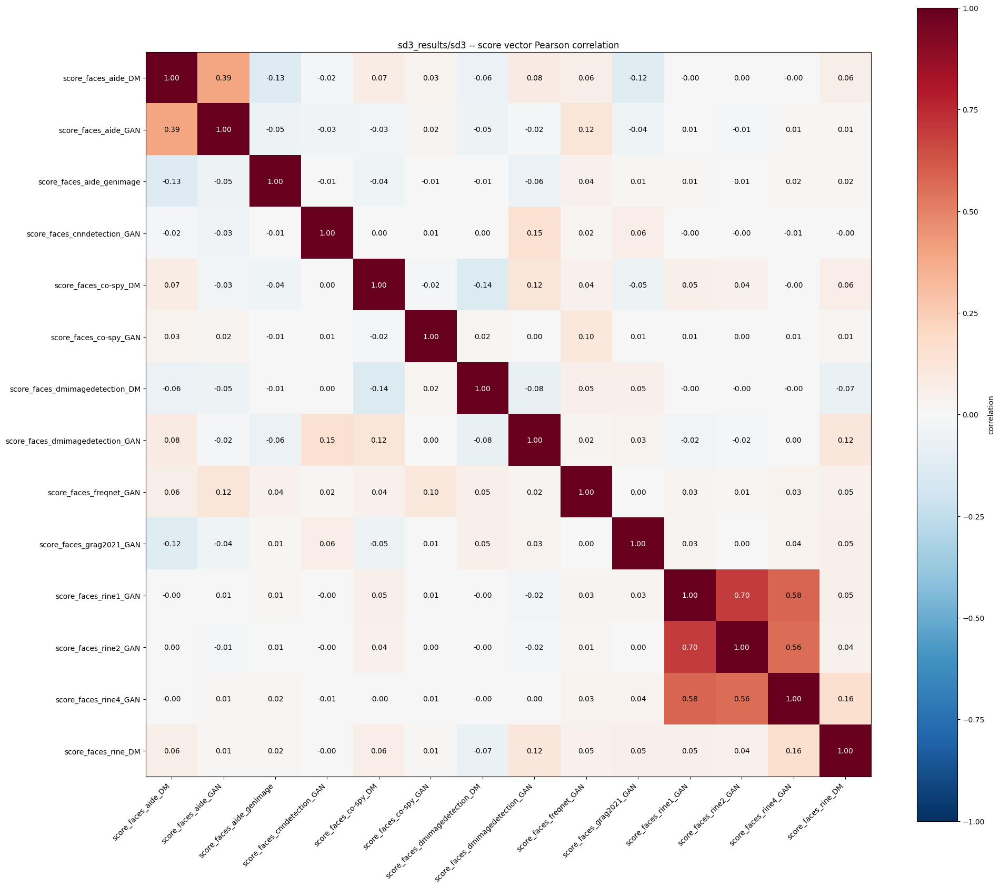

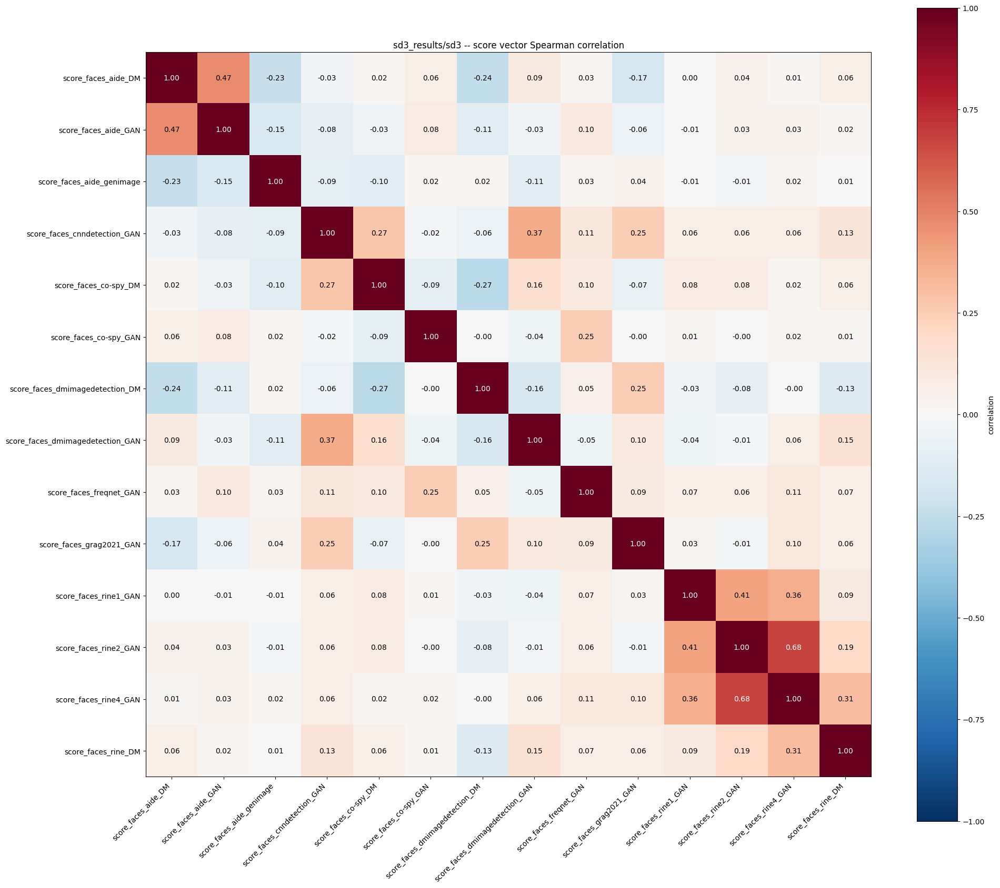

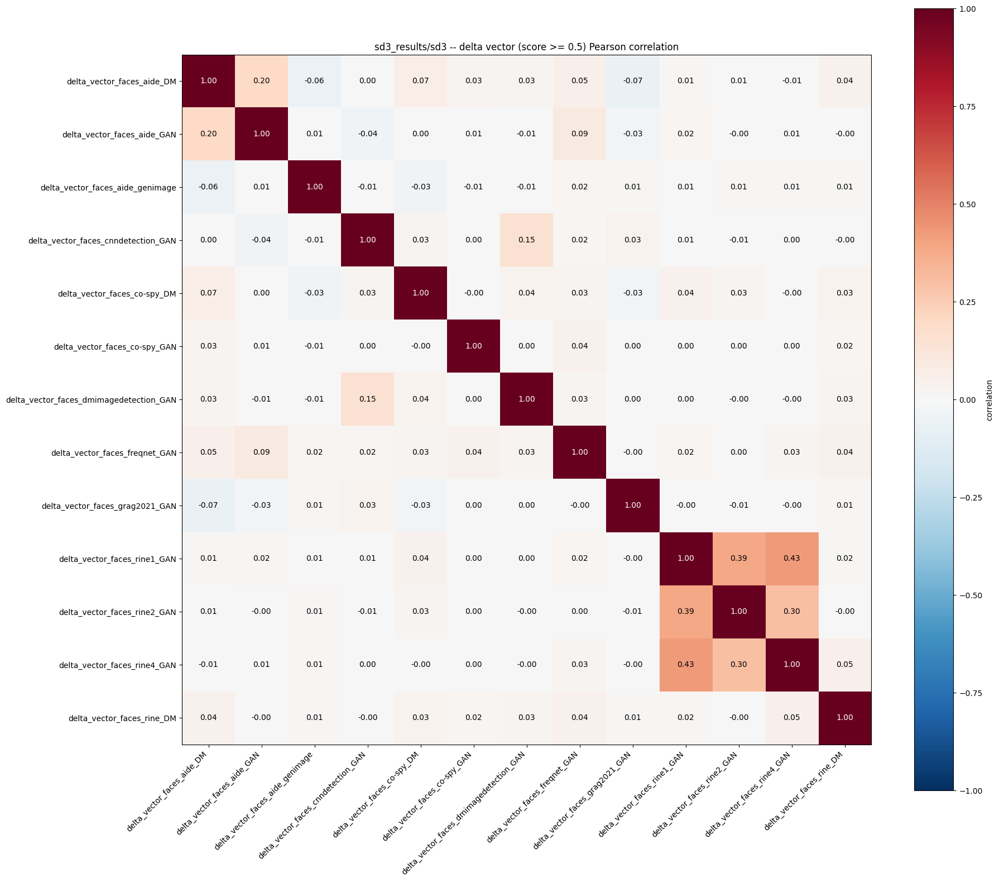

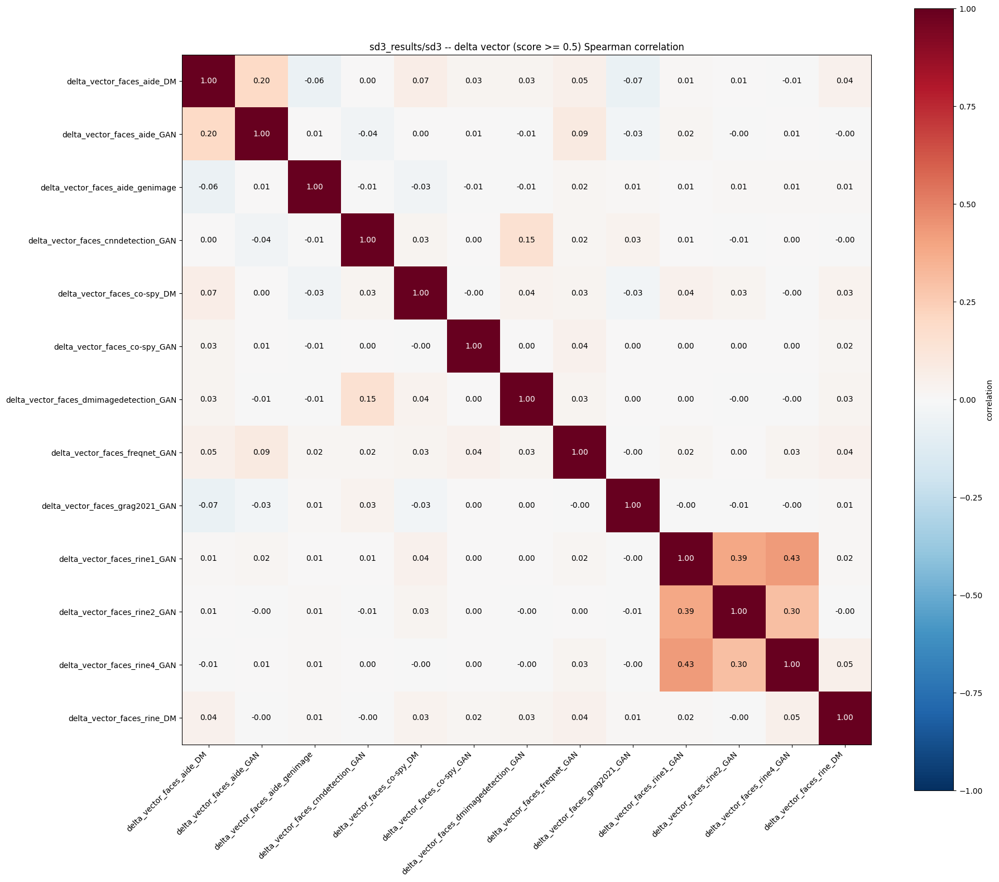

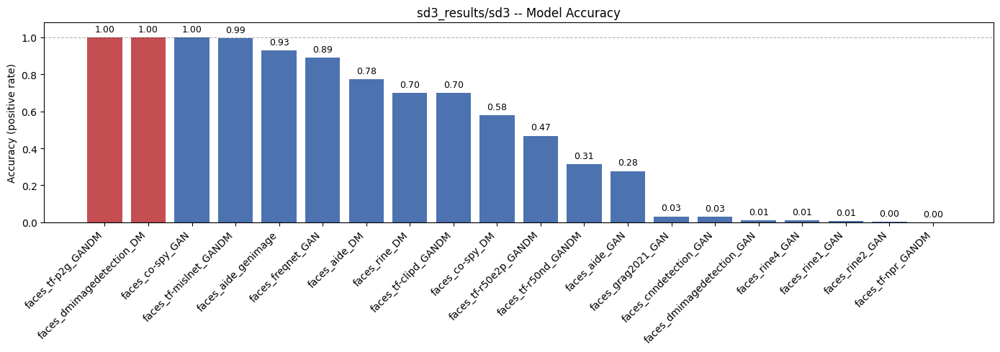

[sd3_results/sd3] Excluded models with 100% positive rate: faces_tf-p2g_GANDM, faces_dmimagedetection_DM
[sd3_results/sd3] Oracle Accuracy: 100.00% (10000 / 10000)
--------------------------------------------------

Processing folder: /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/ffhq_results
Found 20 CSV(s) total in /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/ffhq_results
  ffhq: 20 file(s) -> ['ffhq_faces_aide_DM_predictions.csv', 'ffhq_faces_aide_GAN_predictions.csv', 'ffhq_faces_aide_genimage_predictions.csv', 'ffhq_faces_cnndetection_GAN_predictions.csv', 'ffhq_faces_co-spy_DM_predictions.csv', 'ffhq_faces_co-spy_GAN_predictions.csv', 'ffhq_faces_dmimagedetection_DM_predictions.csv', 'ffhq_faces_dmimagedetection_GAN_predictions.csv', 'ffhq_faces_freqnet_GAN_predictions.csv', 'ffhq_faces_grag2021_GAN_predictions.csv', 'ffhq_faces_rine1_GAN_predictions.csv', 'ffhq_faces_rine2_GAN_predictions.csv', 'ffhq_faces_rine4_GAN_predictions.csv', 'ffhq_

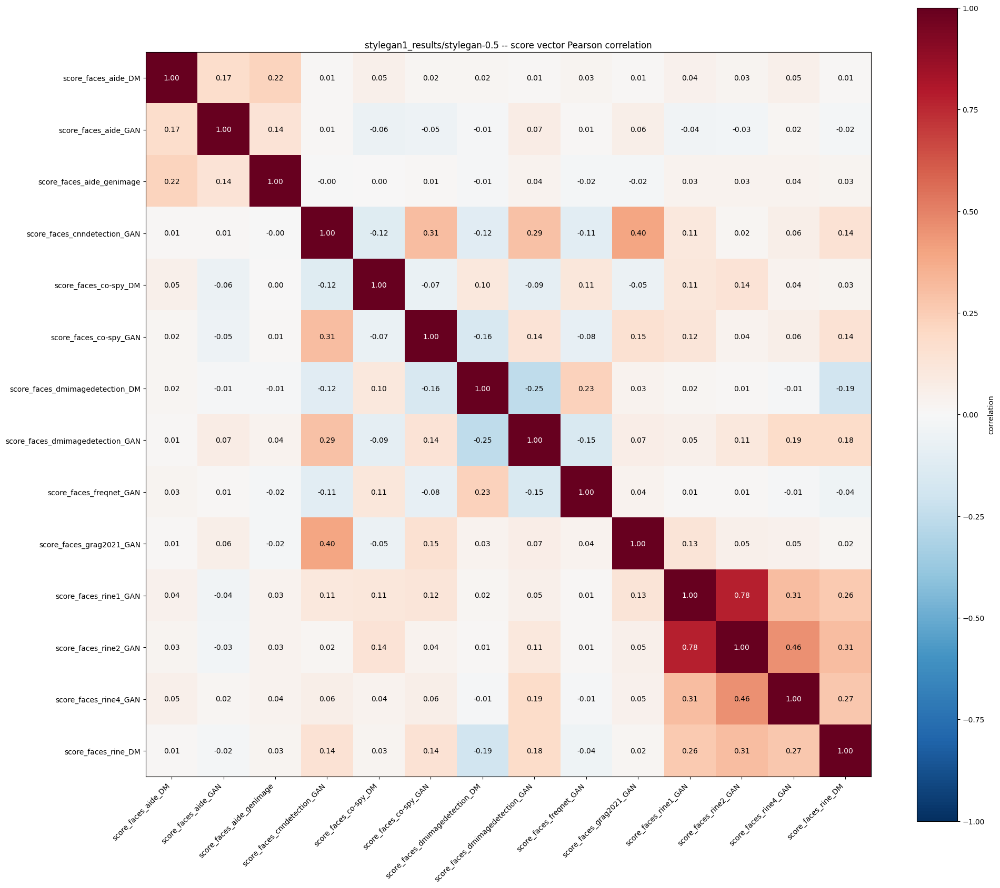

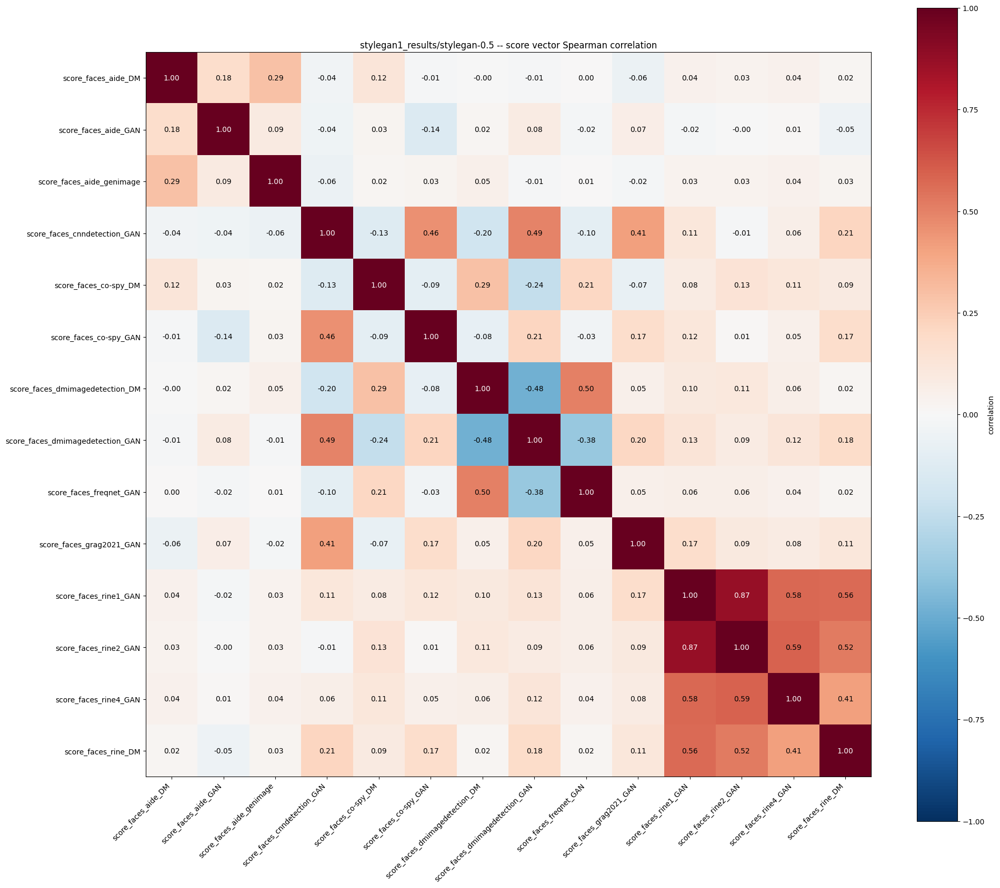

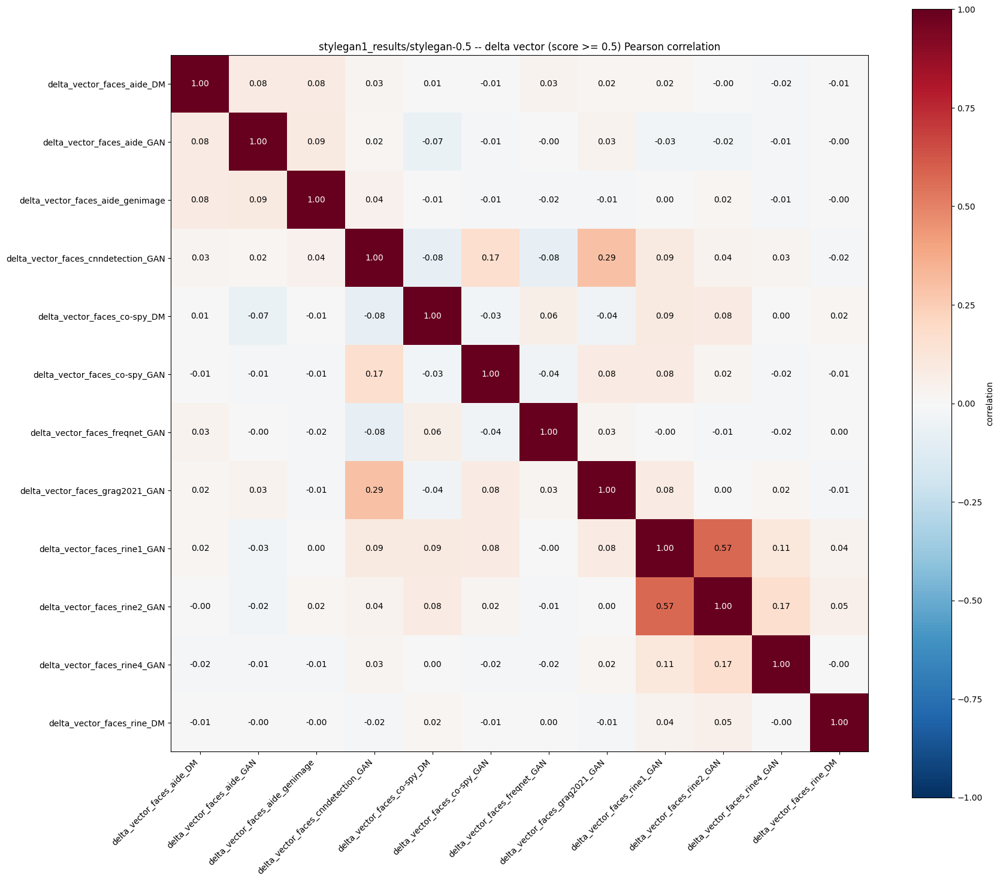

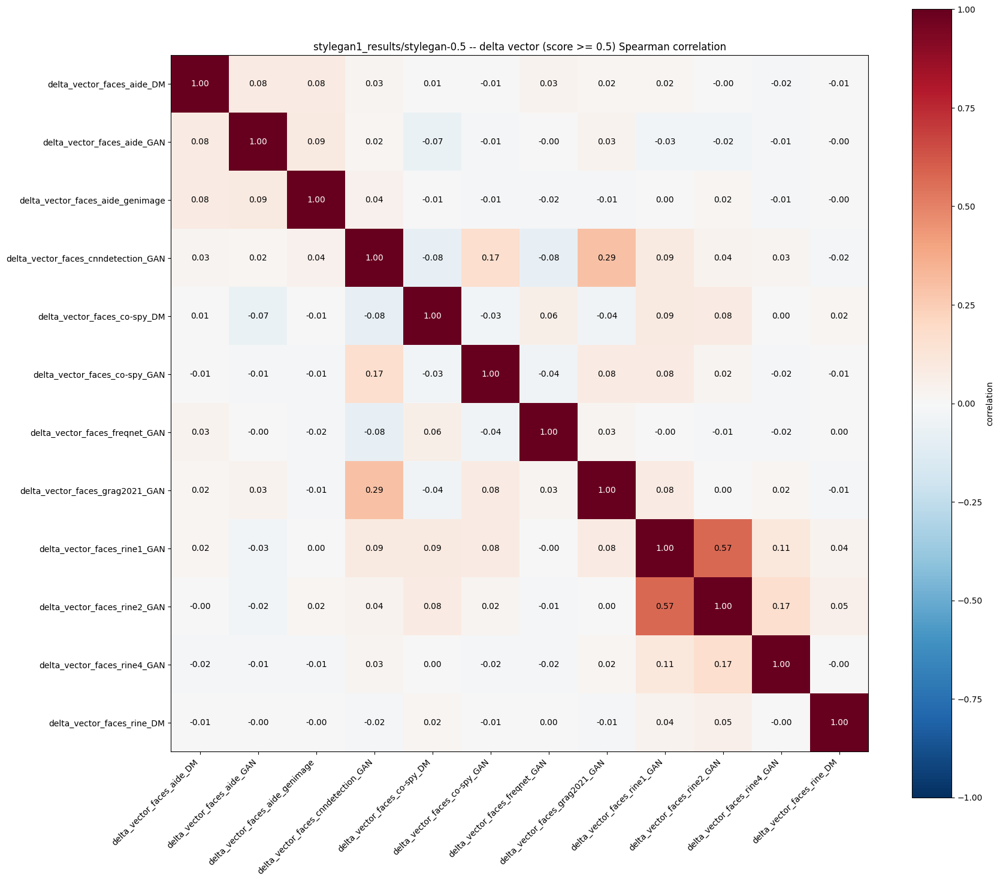

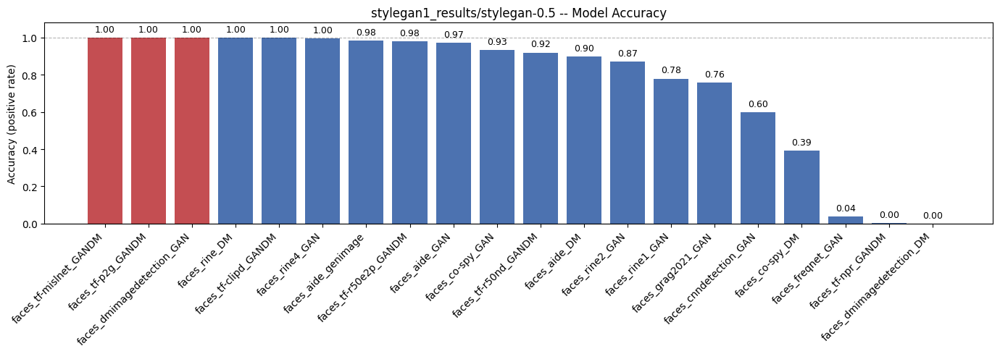


Processing correlations for stylegan1_results/stylegan-0.7...
NOTE: excluding constant delta_vector column(s) from the delta correlation heatmaps (model predicted the same class for every image, so correlation with other models is undefined):
  - delta_vector_faces_dmimagedetection_DM: always 0 (0% positive rate) -- excluded
  - delta_vector_faces_dmimagedetection_GAN: always 1 (100% positive rate) -- excluded
  - delta_vector_faces_rine_DM: always 1 (100% positive rate) -- excluded


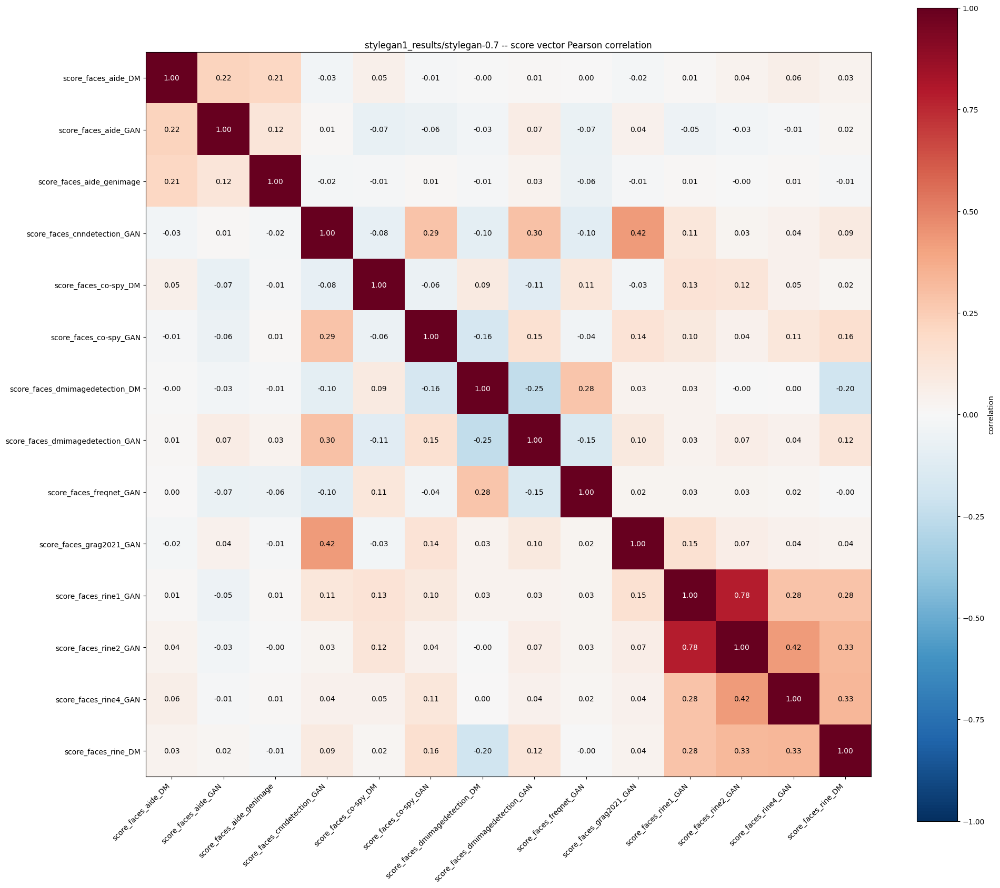

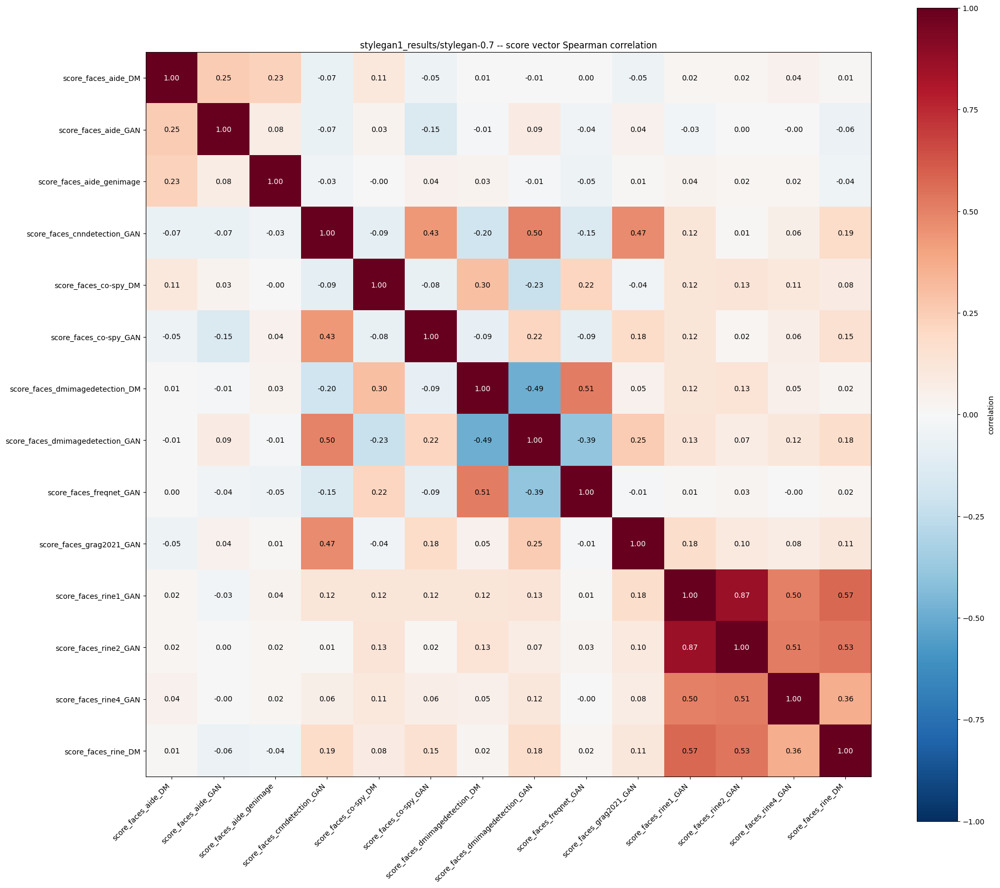

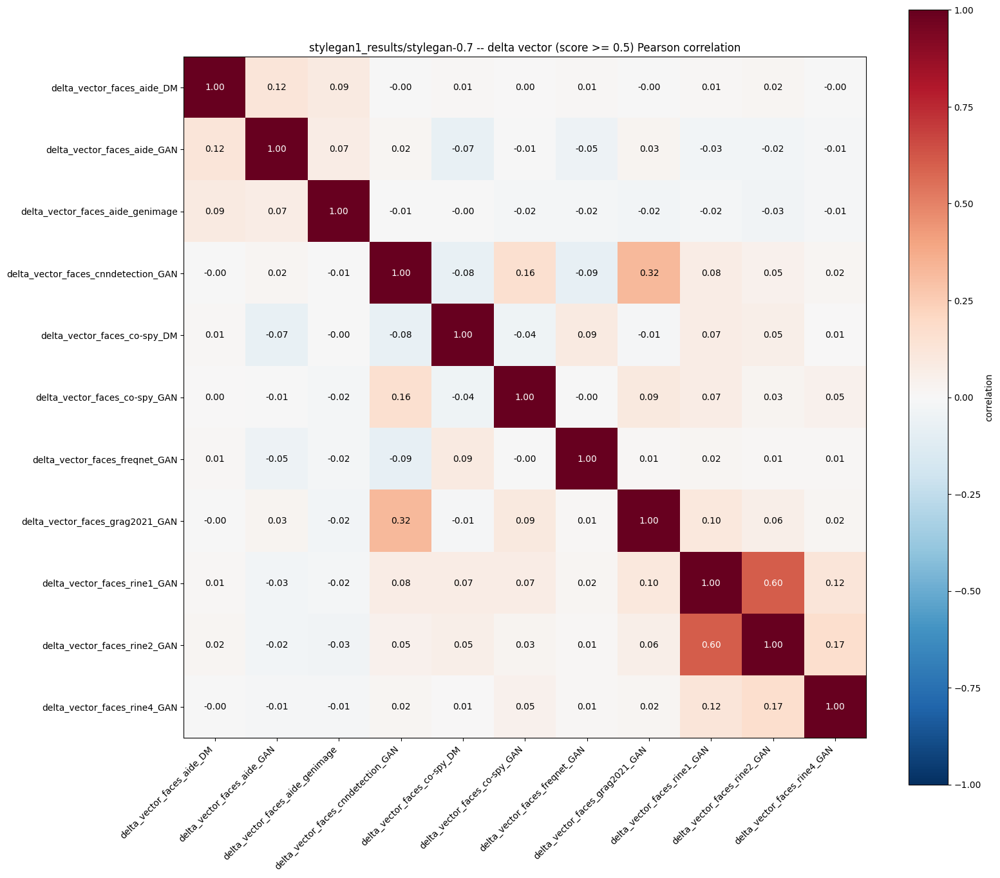

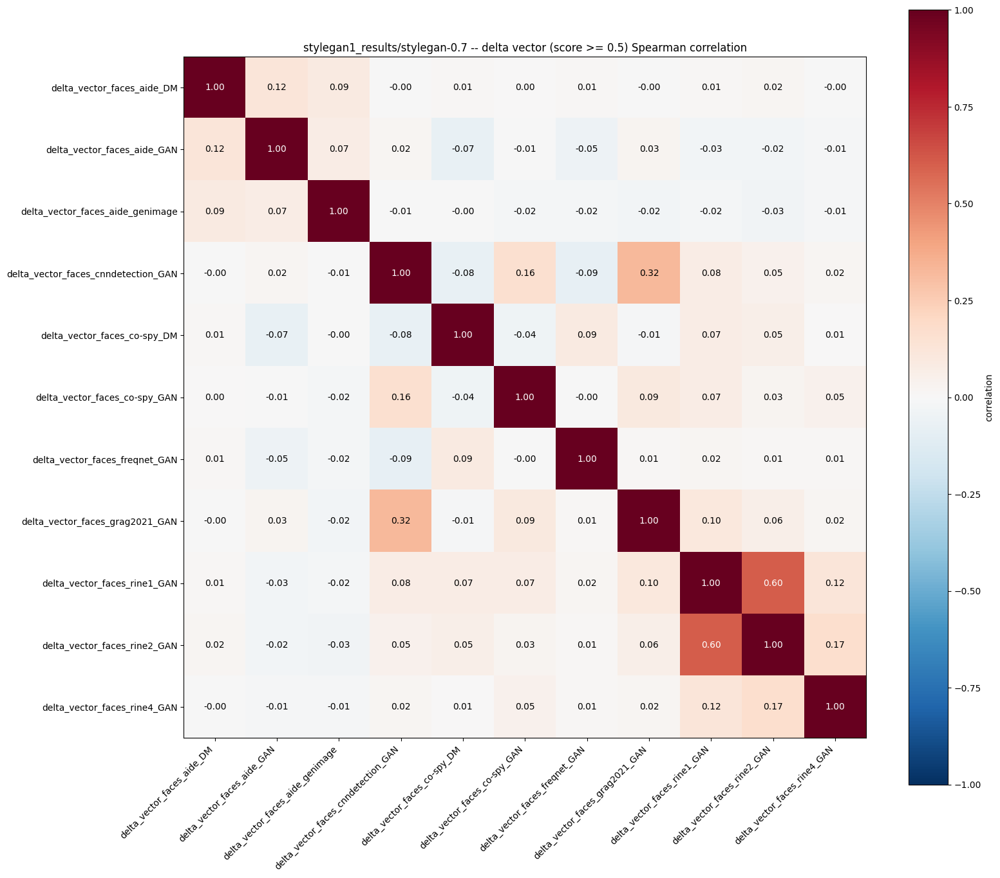

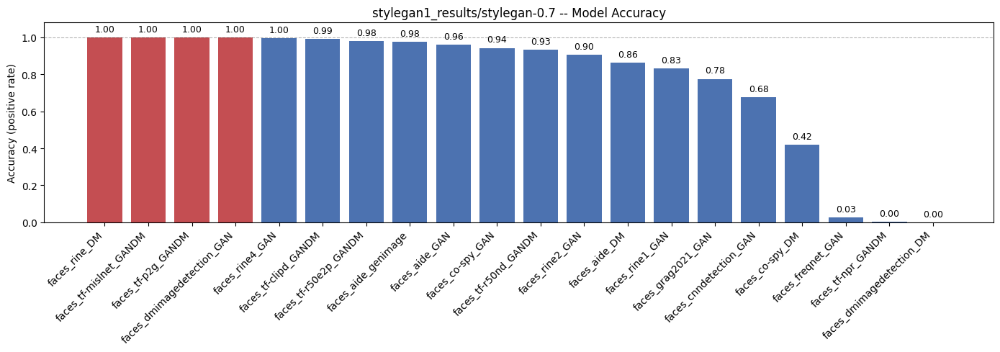


Processing correlations for stylegan1_results/stylegan...


/tmp/ipykernel_435/1925035193.py:5: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
/tmp/ipykernel_435/1925035193.py:5: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')


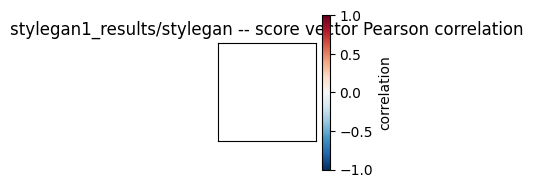

/tmp/ipykernel_435/1925035193.py:5: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
/tmp/ipykernel_435/1925035193.py:5: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')


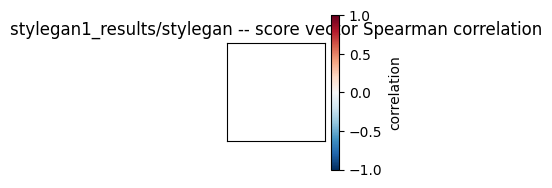

/tmp/ipykernel_435/1925035193.py:5: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
/tmp/ipykernel_435/1925035193.py:5: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')


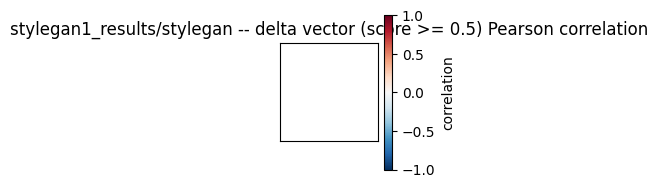

/tmp/ipykernel_435/1925035193.py:5: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
/tmp/ipykernel_435/1925035193.py:5: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')


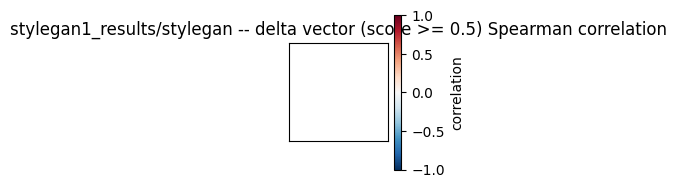

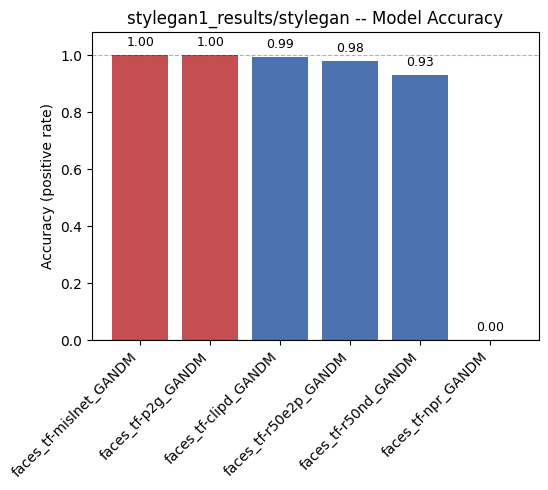

[stylegan1_results/stylegan-0.5] Excluded models with 100% positive rate: faces_tf-p2g_GANDM, faces_tf-mislnet_GANDM, faces_dmimagedetection_GAN
[stylegan1_results/stylegan-0.5] Oracle Accuracy: 100.00% (2600 / 2600)
--------------------------------------------------
[stylegan1_results/stylegan-0.7] Excluded models with 100% positive rate: faces_tf-p2g_GANDM, faces_rine_DM, faces_tf-mislnet_GANDM, faces_dmimagedetection_GAN
[stylegan1_results/stylegan-0.7] Oracle Accuracy: 100.00% (2600 / 2600)
--------------------------------------------------
[stylegan1_results/stylegan] Excluded models with 100% positive rate: faces_tf-mislnet_GANDM, faces_tf-p2g_GANDM
[stylegan1_results/stylegan] Oracle Accuracy: 100.00% (10000 / 10000)
--------------------------------------------------

Processing folder: /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/sd1.5_results
Found 20 CSV(s) total in /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/sd1.5_results
  sd1.5: 20 

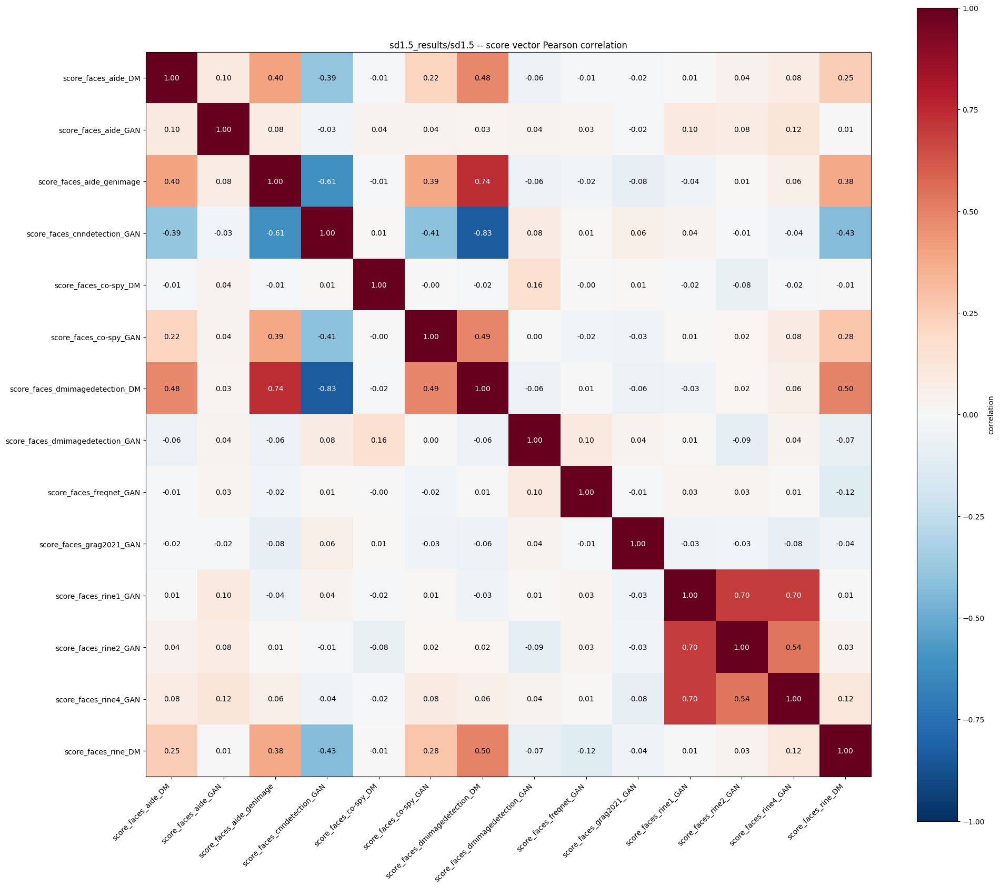

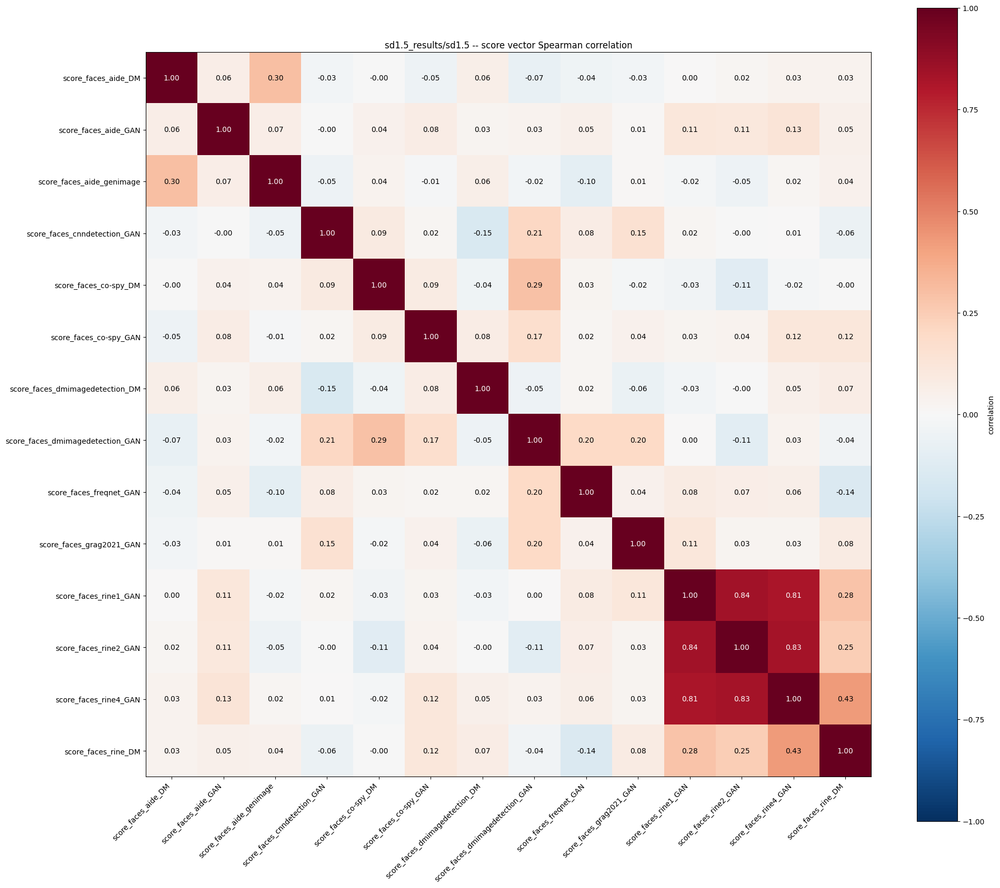

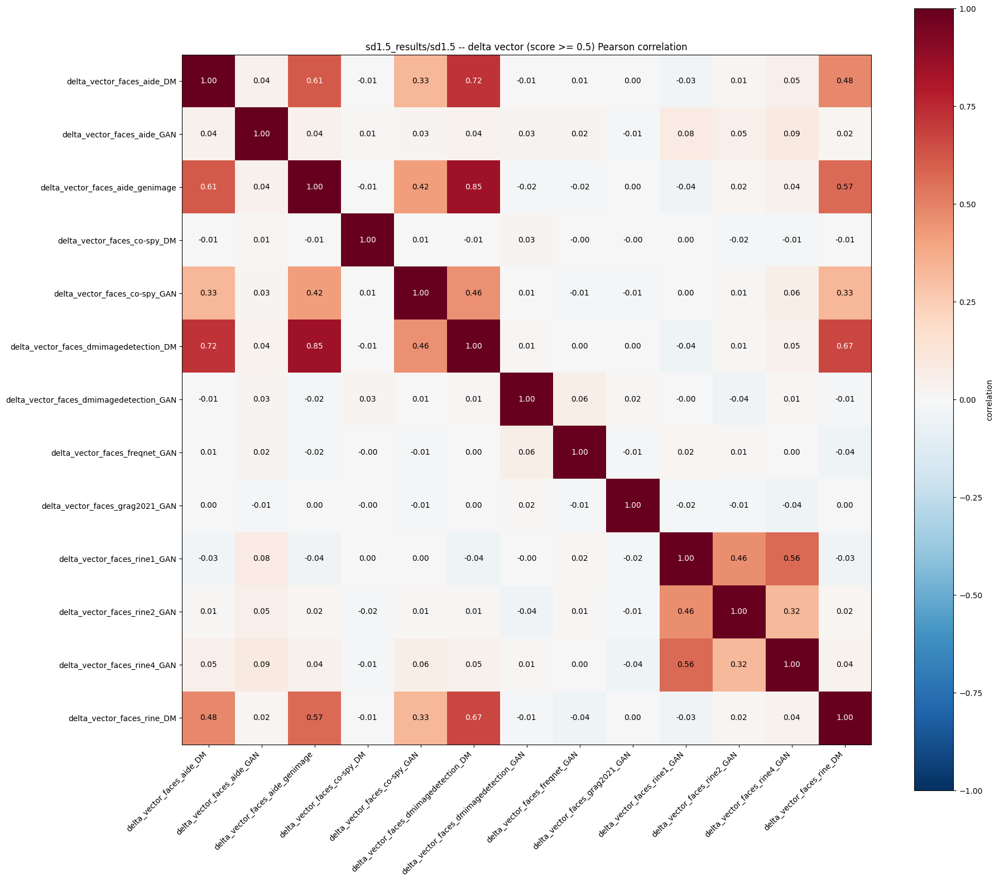

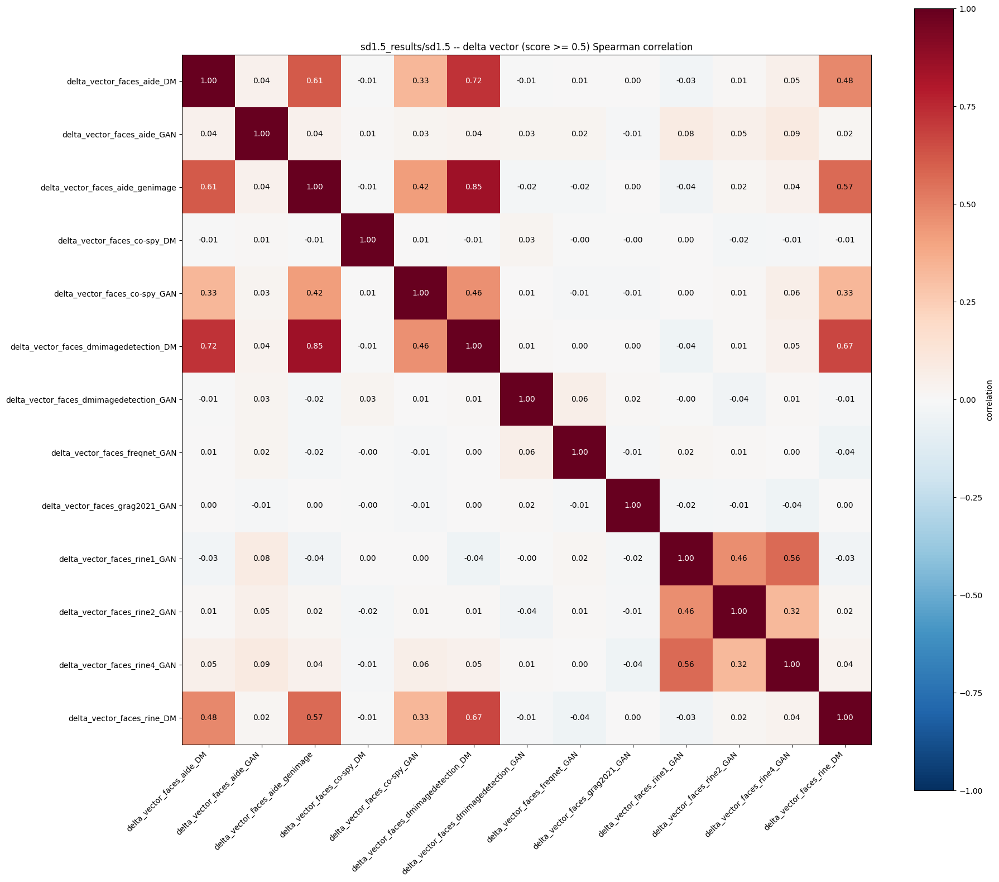

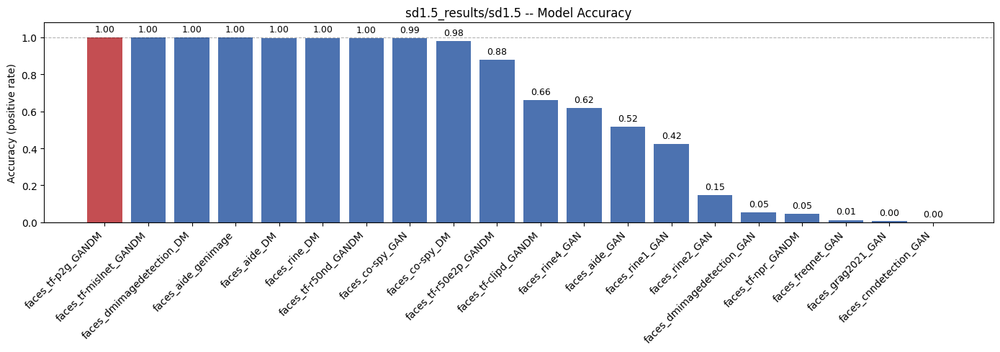

[sd1.5_results/sd1.5] Excluded models with 100% positive rate: faces_tf-p2g_GANDM
[sd1.5_results/sd1.5] Oracle Accuracy: 100.00% (10000 / 10000)
--------------------------------------------------

Processing folder: /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/sd2_results
Found 20 CSV(s) total in /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/sd2_results
  sd2: 20 file(s) -> ['sd2_faces_aide_DM_predictions.csv', 'sd2_faces_aide_GAN_predictions.csv', 'sd2_faces_aide_genimage_predictions.csv', 'sd2_faces_cnndetection_GAN_predictions.csv', 'sd2_faces_co-spy_DM_predictions.csv', 'sd2_faces_co-spy_GAN_predictions.csv', 'sd2_faces_dmimagedetection_DM_predictions.csv', 'sd2_faces_dmimagedetection_GAN_predictions.csv', 'sd2_faces_freqnet_GAN_predictions.csv', 'sd2_faces_grag2021_GAN_predictions.csv', 'sd2_faces_rine1_GAN_predictions.csv', 'sd2_faces_rine2_GAN_predictions.csv', 'sd2_faces_rine4_GAN_predictions.csv', 'sd2_faces_rine_DM_predictions.csv', 'sd2

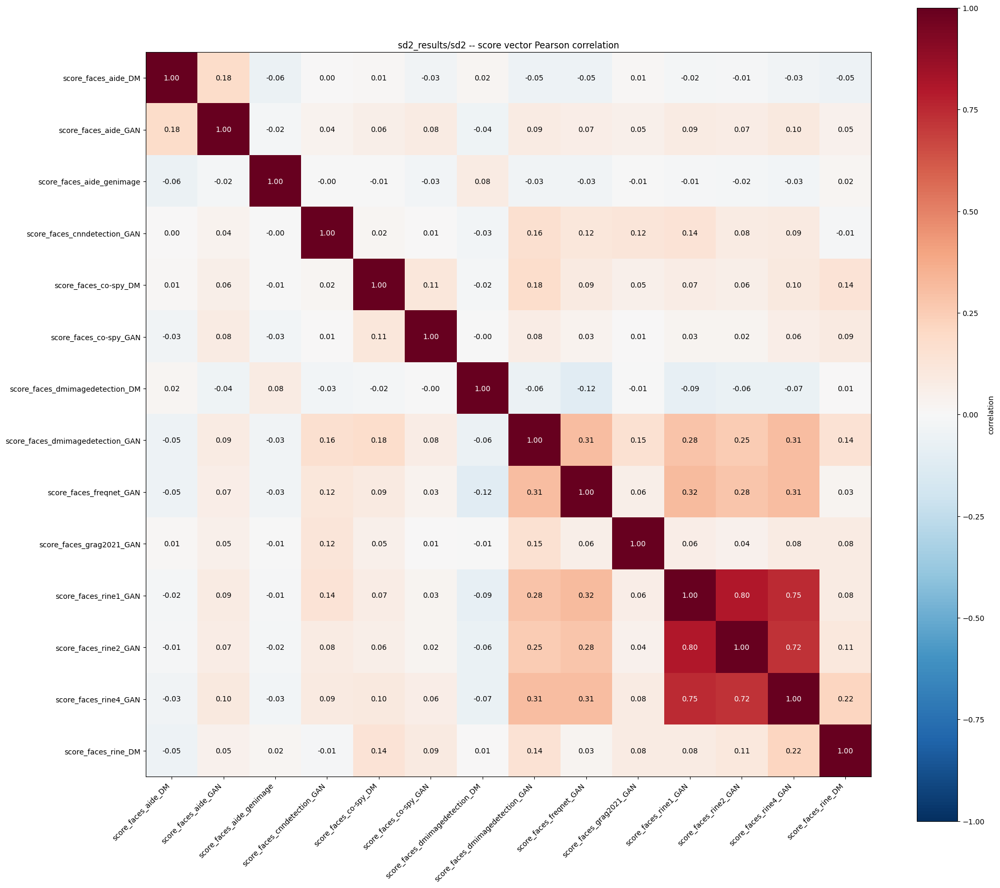

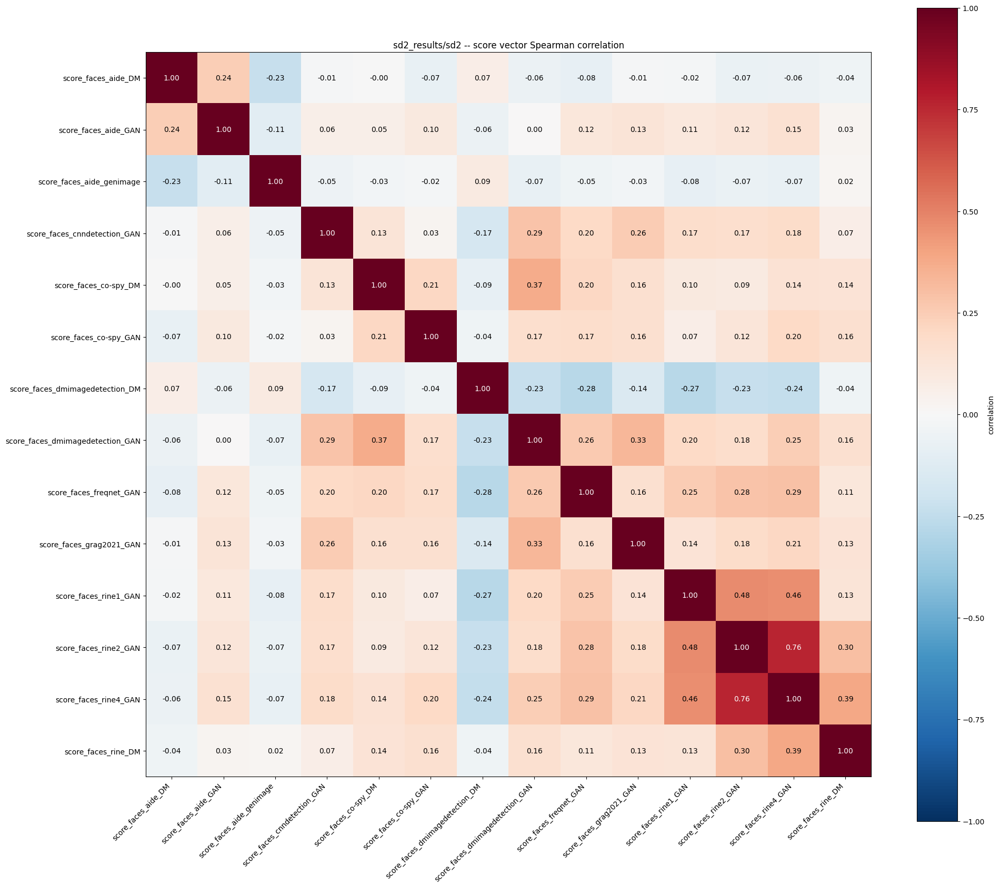

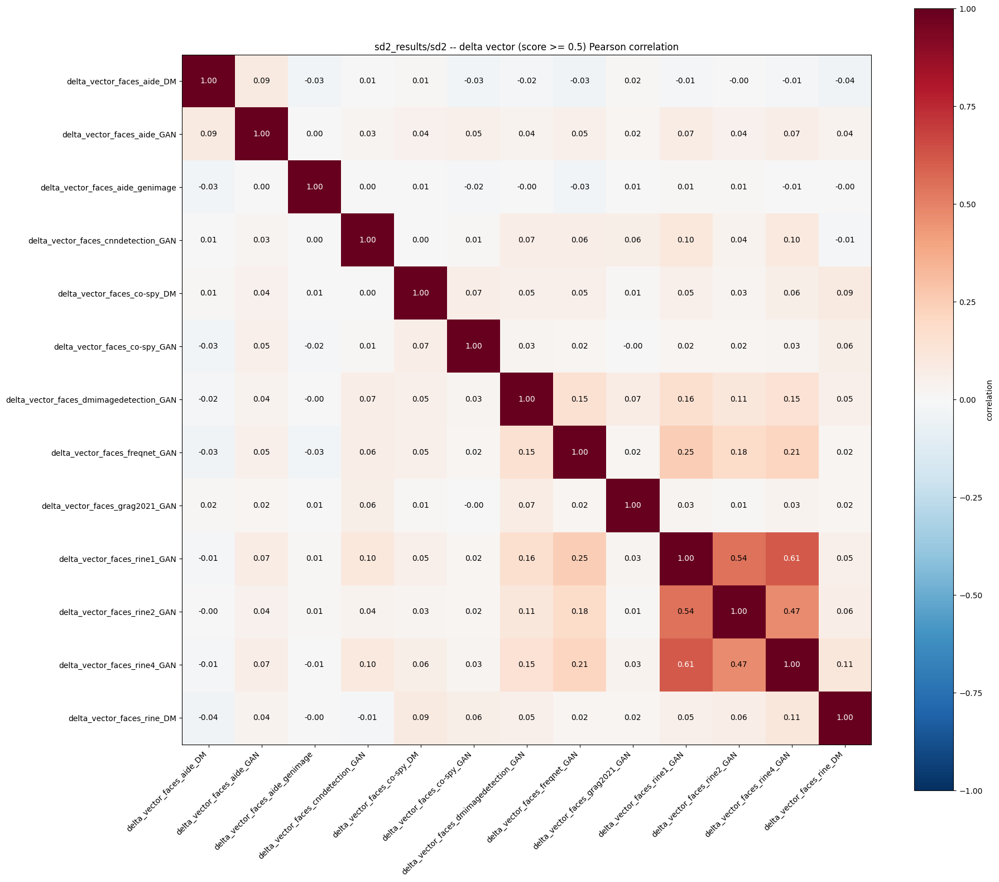

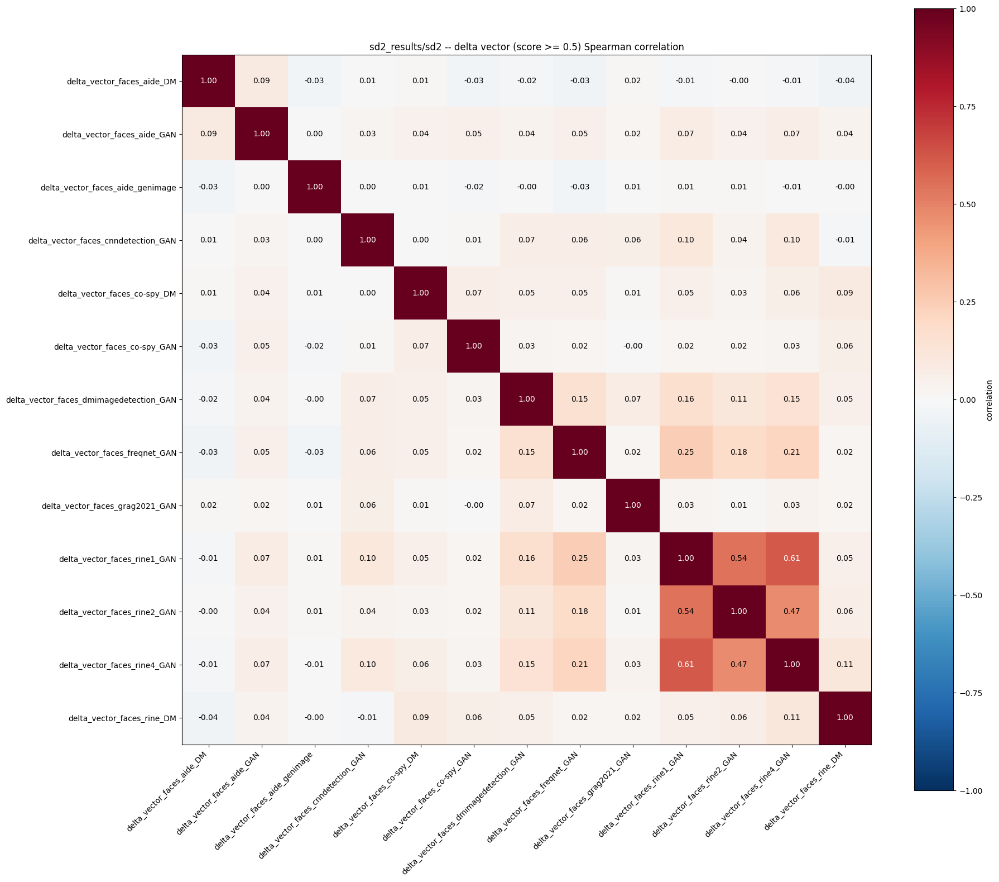

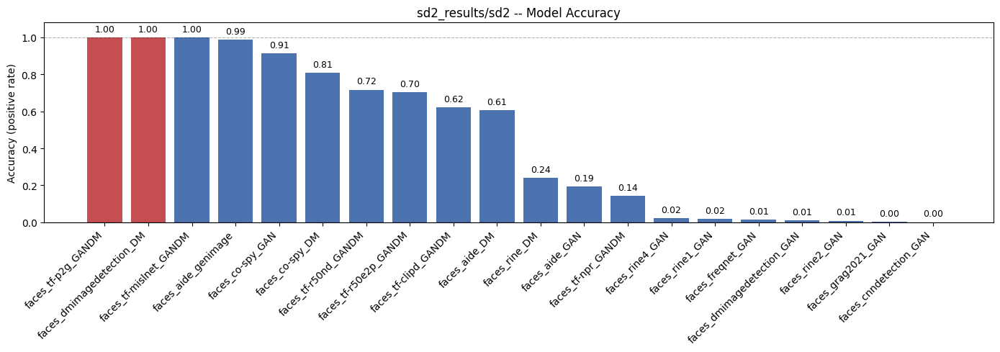

[sd2_results/sd2] Excluded models with 100% positive rate: faces_tf-p2g_GANDM, faces_dmimagedetection_DM
[sd2_results/sd2] Oracle Accuracy: 100.00% (10000 / 10000)
--------------------------------------------------

Processing folder: /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/sdxl_results
Found 20 CSV(s) total in /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/sdxl_results
  sdxl: 20 file(s) -> ['sdxl_faces_aide_DM_predictions.csv', 'sdxl_faces_aide_GAN_predictions.csv', 'sdxl_faces_aide_genimage_predictions.csv', 'sdxl_faces_cnndetection_GAN_predictions.csv', 'sdxl_faces_co-spy_DM_predictions.csv', 'sdxl_faces_co-spy_GAN_predictions.csv', 'sdxl_faces_dmimagedetection_DM_predictions.csv', 'sdxl_faces_dmimagedetection_GAN_predictions.csv', 'sdxl_faces_freqnet_GAN_predictions.csv', 'sdxl_faces_grag2021_GAN_predictions.csv', 'sdxl_faces_rine1_GAN_predictions.csv', 'sdxl_faces_rine2_GAN_predictions.csv', 'sdxl_faces_rine4_GAN_predictions.csv', 'sdxl_

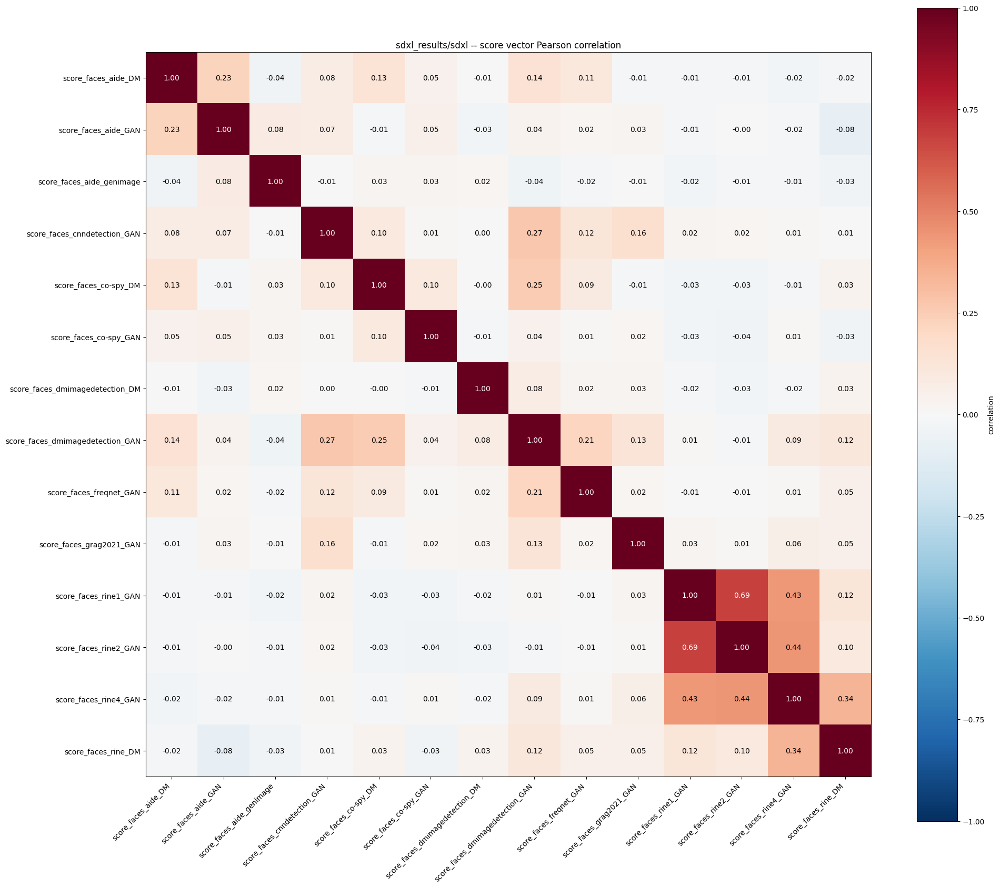

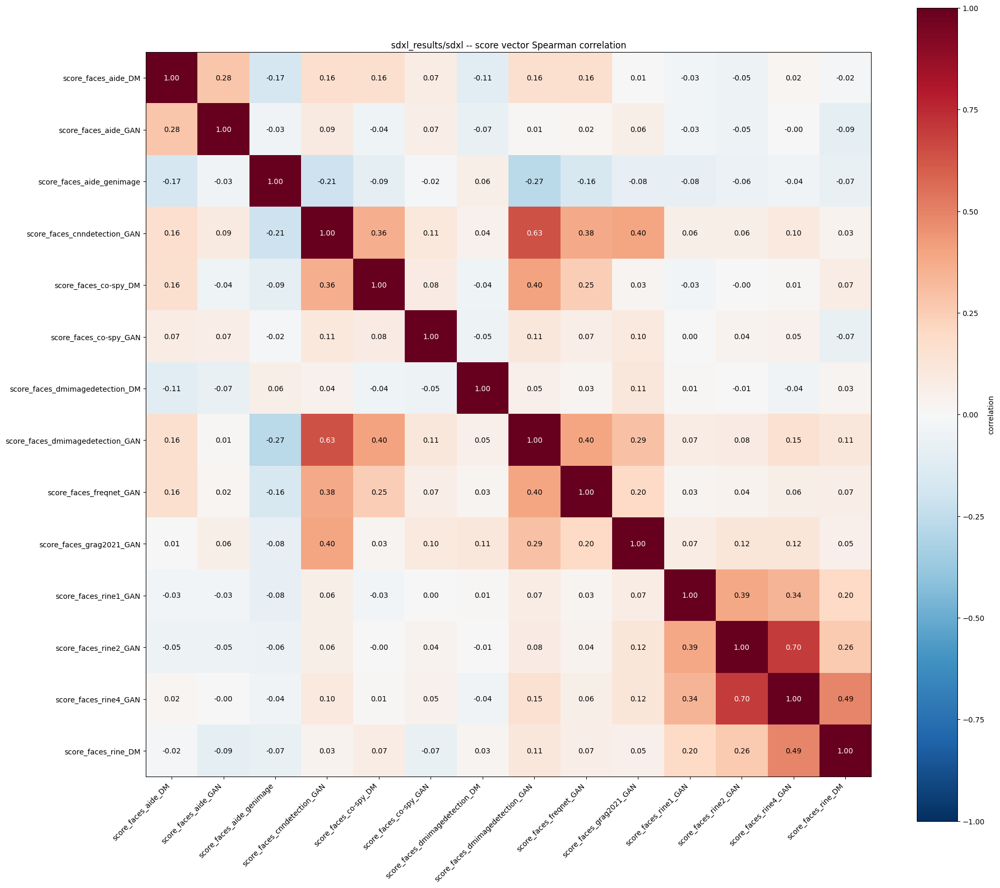

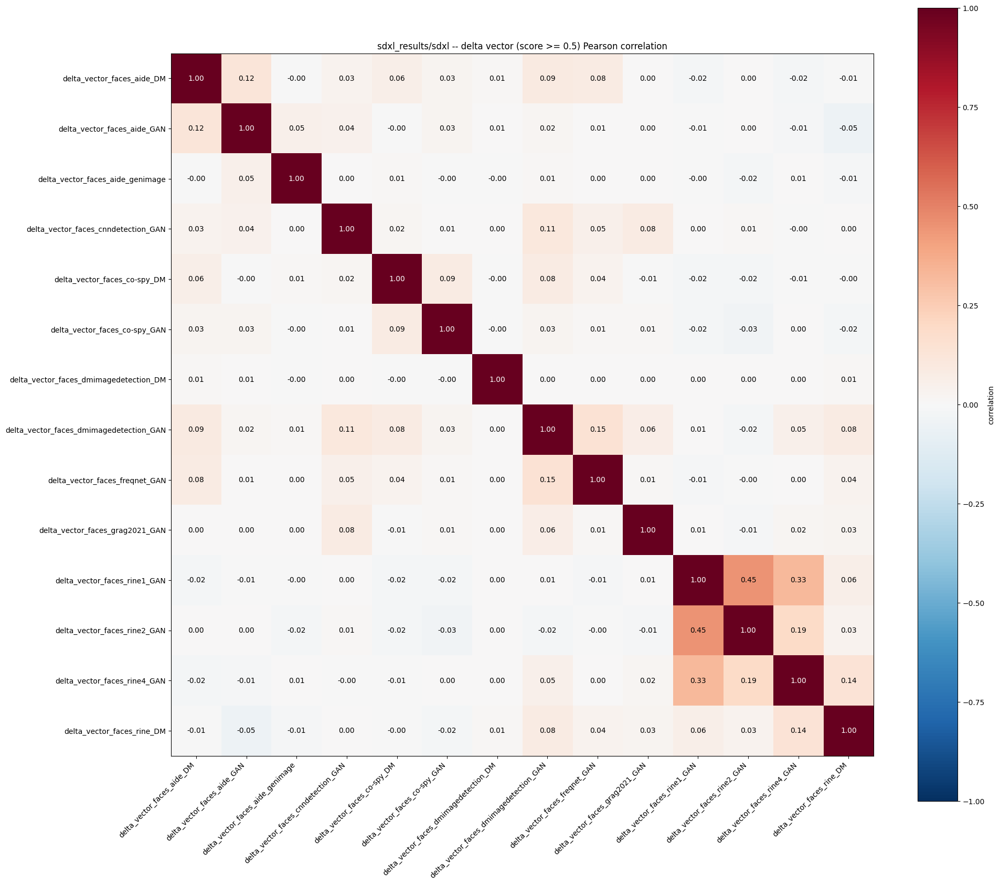

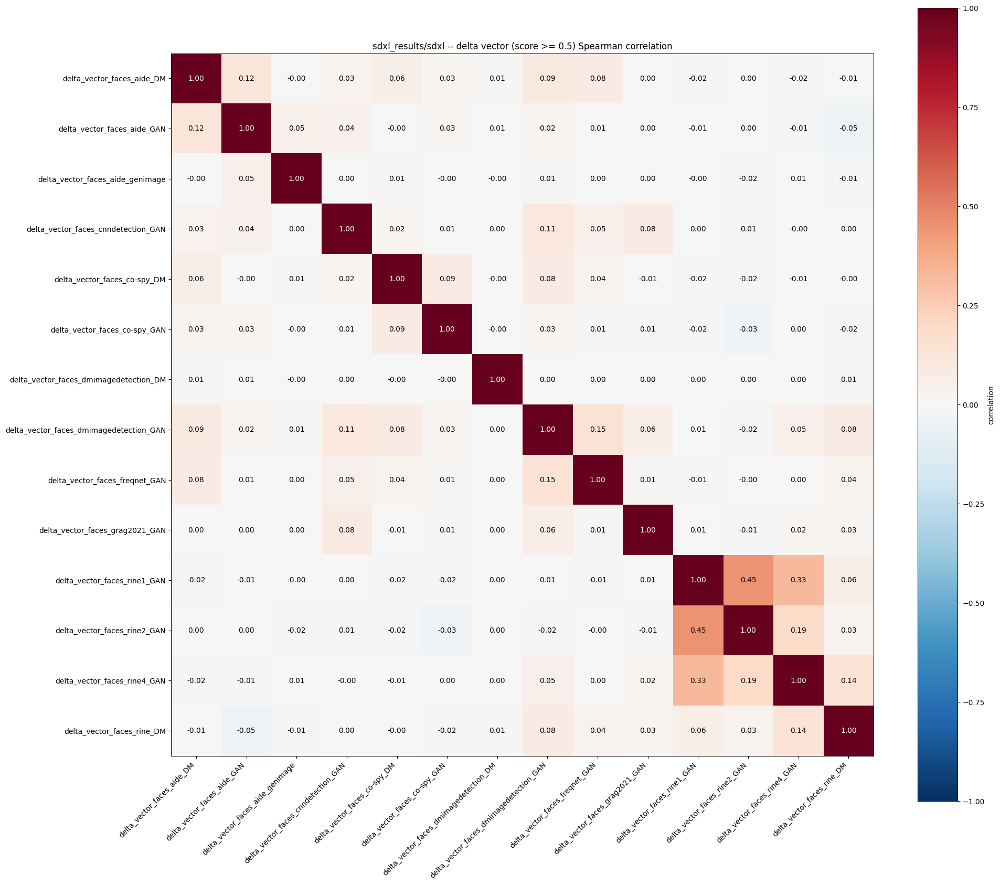

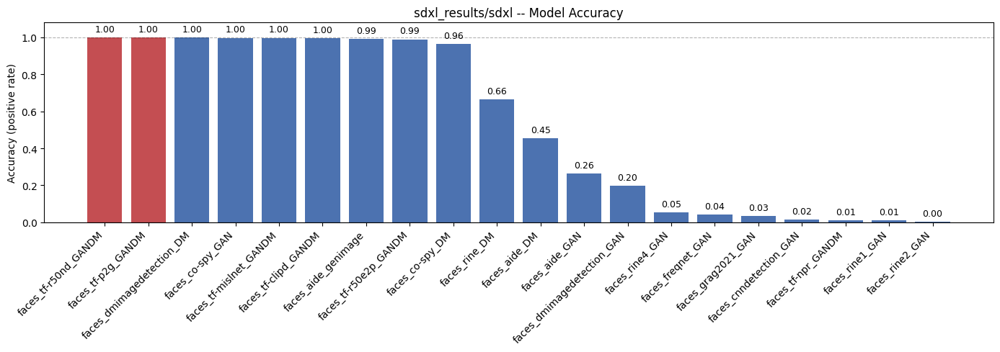

[sdxl_results/sdxl] Excluded models with 100% positive rate: faces_tf-p2g_GANDM, faces_tf-r50nd_GANDM
[sdxl_results/sdxl] Oracle Accuracy: 100.00% (10000 / 10000)
--------------------------------------------------

Processing folder: /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/stylegan23_results
Found 110 CSV(s) total in /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/stylegan23_results
  stylegan2-0.5: 20 file(s) -> ['stylegan2-0.5_faces_aide_DM_predictions.csv', 'stylegan2-0.5_faces_aide_GAN_predictions.csv', 'stylegan2-0.5_faces_aide_genimage_predictions.csv', 'stylegan2-0.5_faces_cnndetection_GAN_predictions.csv', 'stylegan2-0.5_faces_co-spy_DM_predictions.csv', 'stylegan2-0.5_faces_co-spy_GAN_predictions.csv', 'stylegan2-0.5_faces_dmimagedetection_DM_predictions.csv', 'stylegan2-0.5_faces_dmimagedetection_GAN_predictions.csv', 'stylegan2-0.5_faces_freqnet_GAN_predictions.csv', 'stylegan2-0.5_faces_grag2021_GAN_predictions.csv', 'stylegan2-0.5_

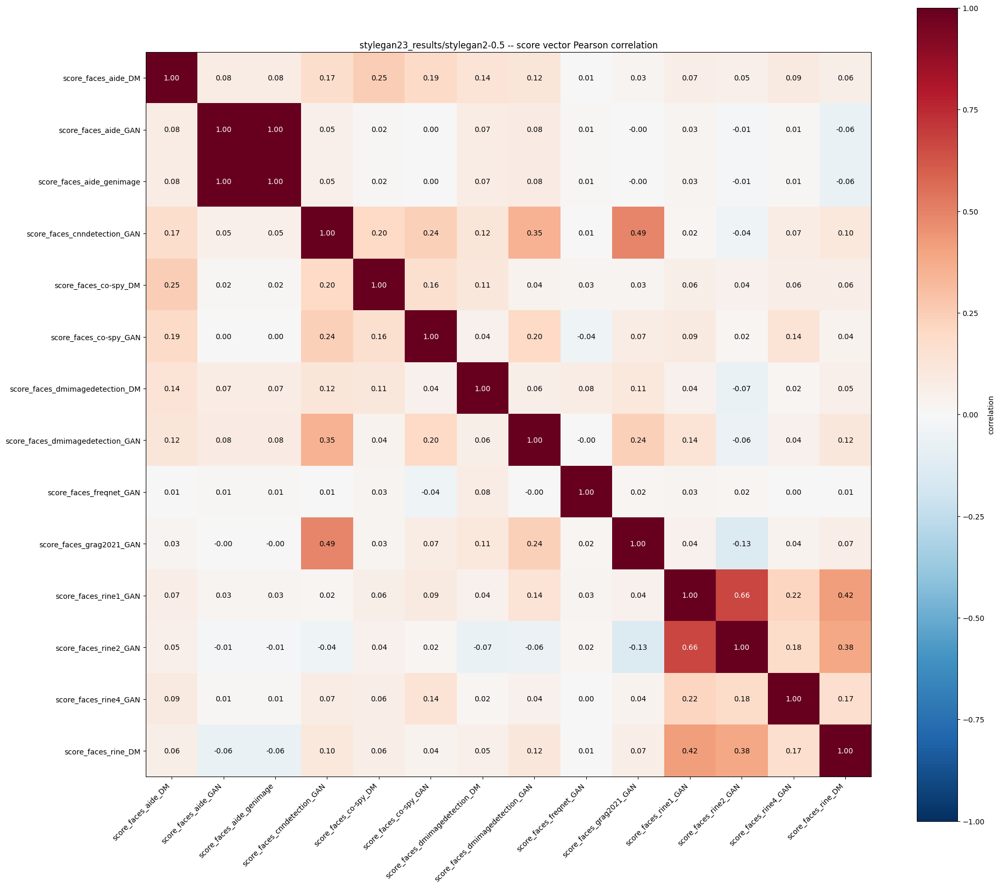

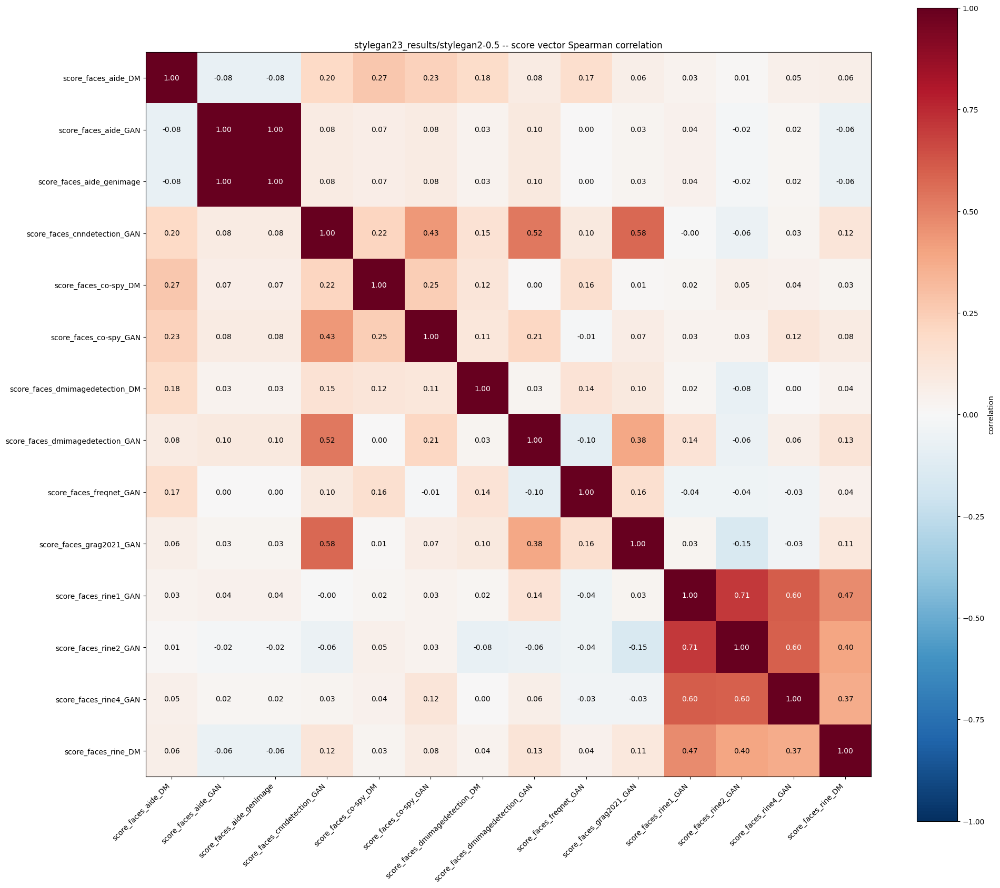

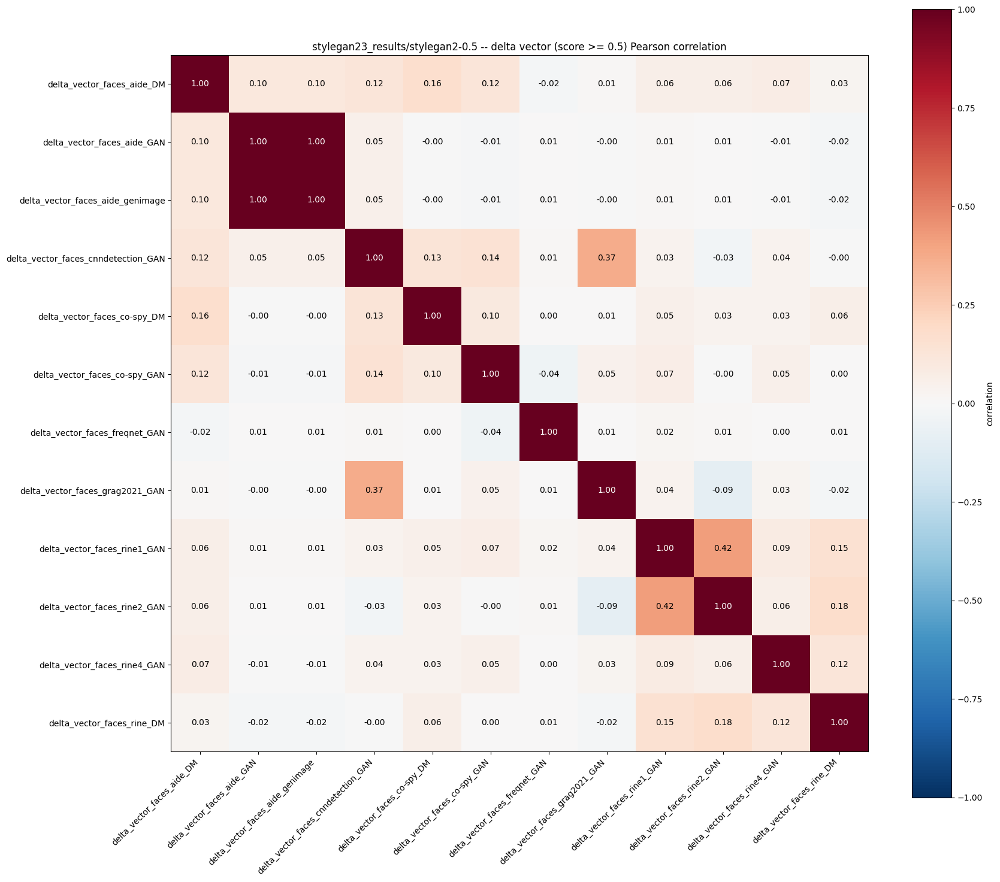

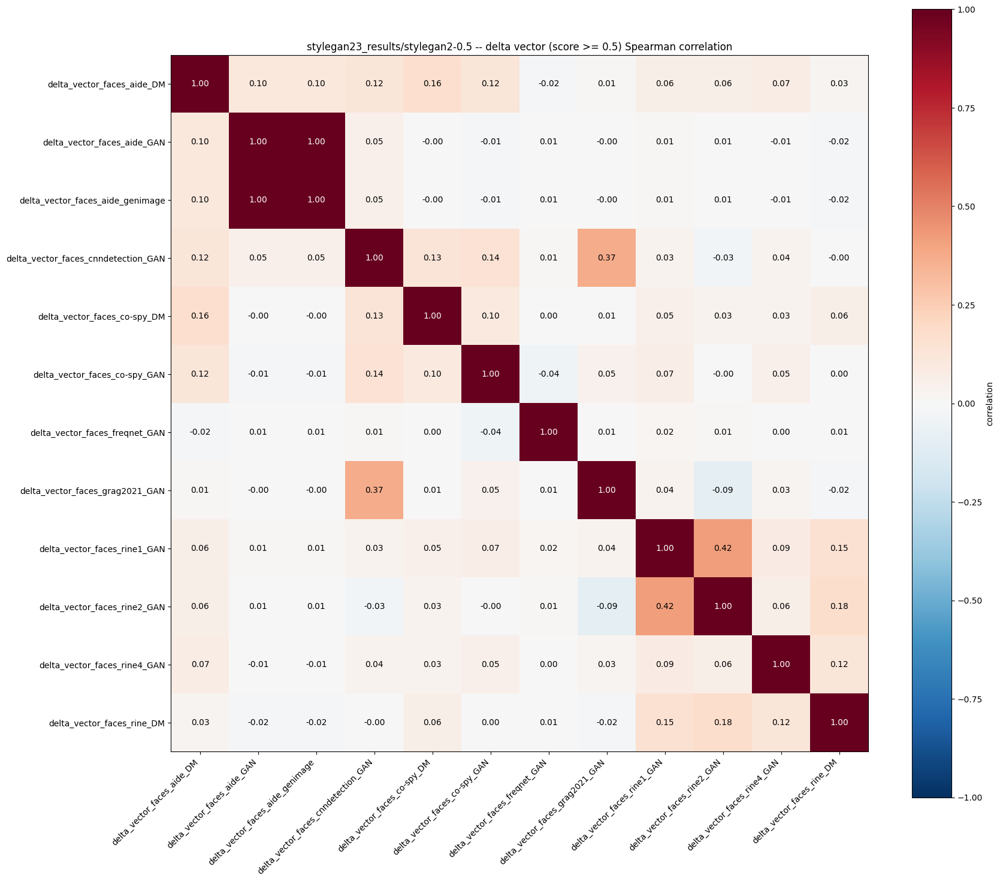

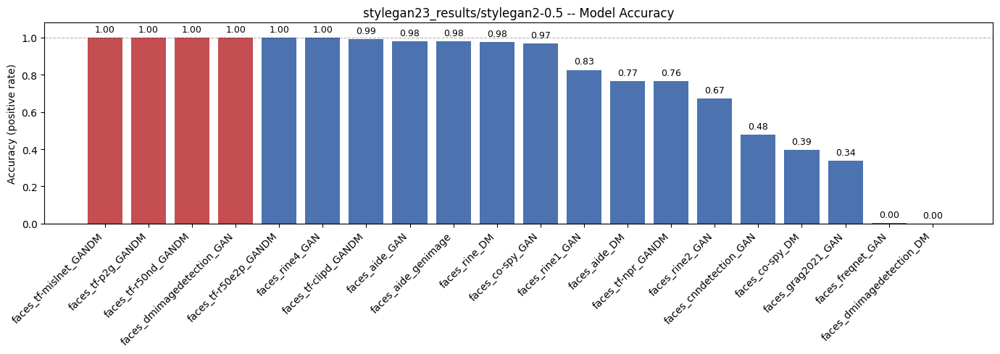


Processing correlations for stylegan23_results/stylegan2-1.0...
NOTE: excluding constant delta_vector column(s) from the delta correlation heatmaps (model predicted the same class for every image, so correlation with other models is undefined):
  - delta_vector_faces_dmimagedetection_DM: always 0 (0% positive rate) -- excluded
  - delta_vector_faces_dmimagedetection_GAN: always 1 (100% positive rate) -- excluded


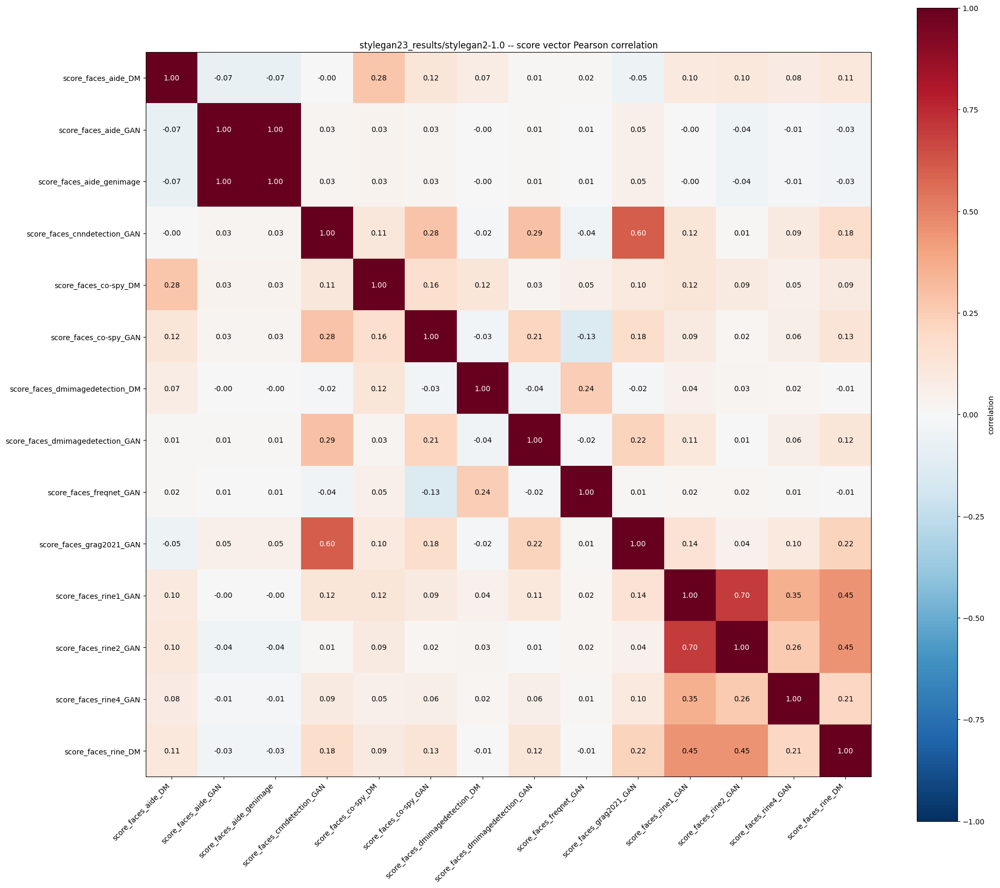

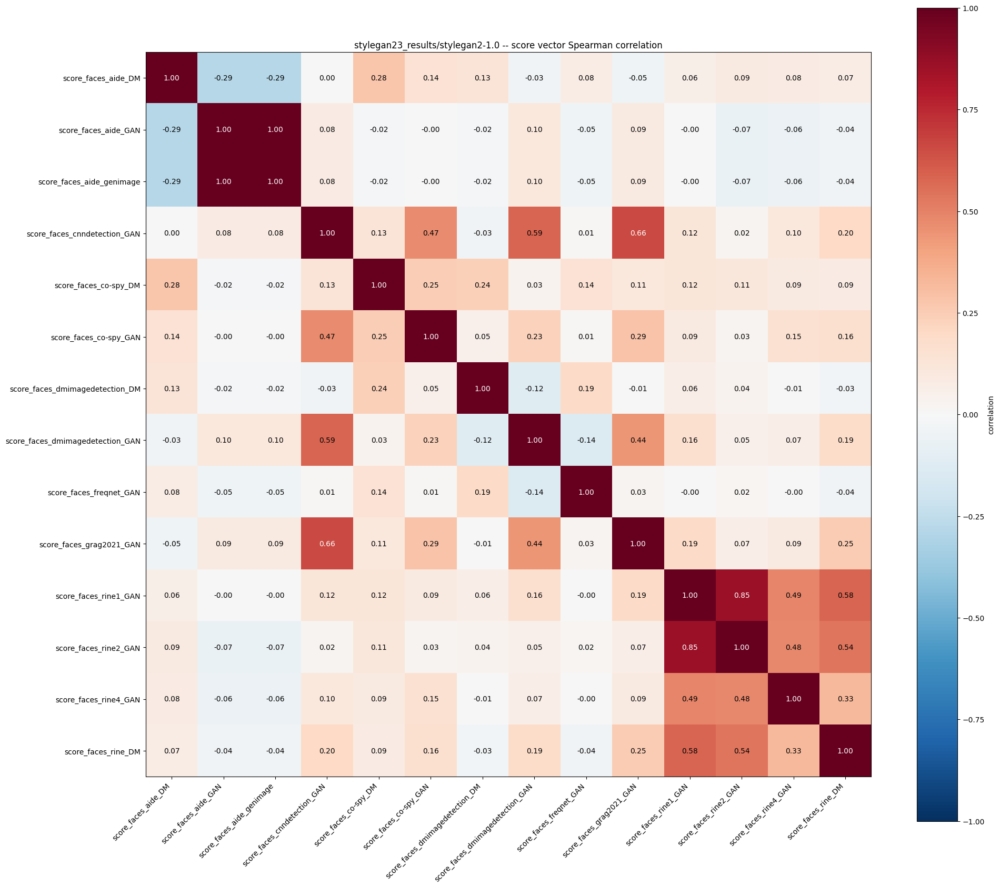

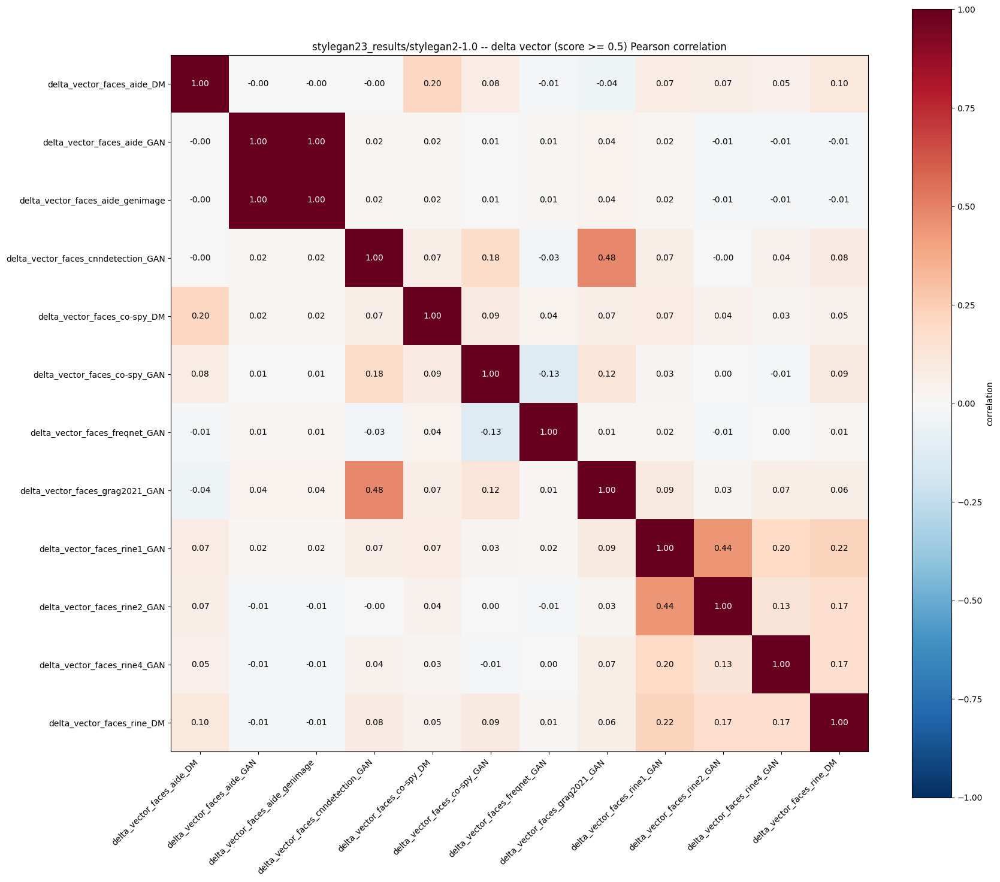

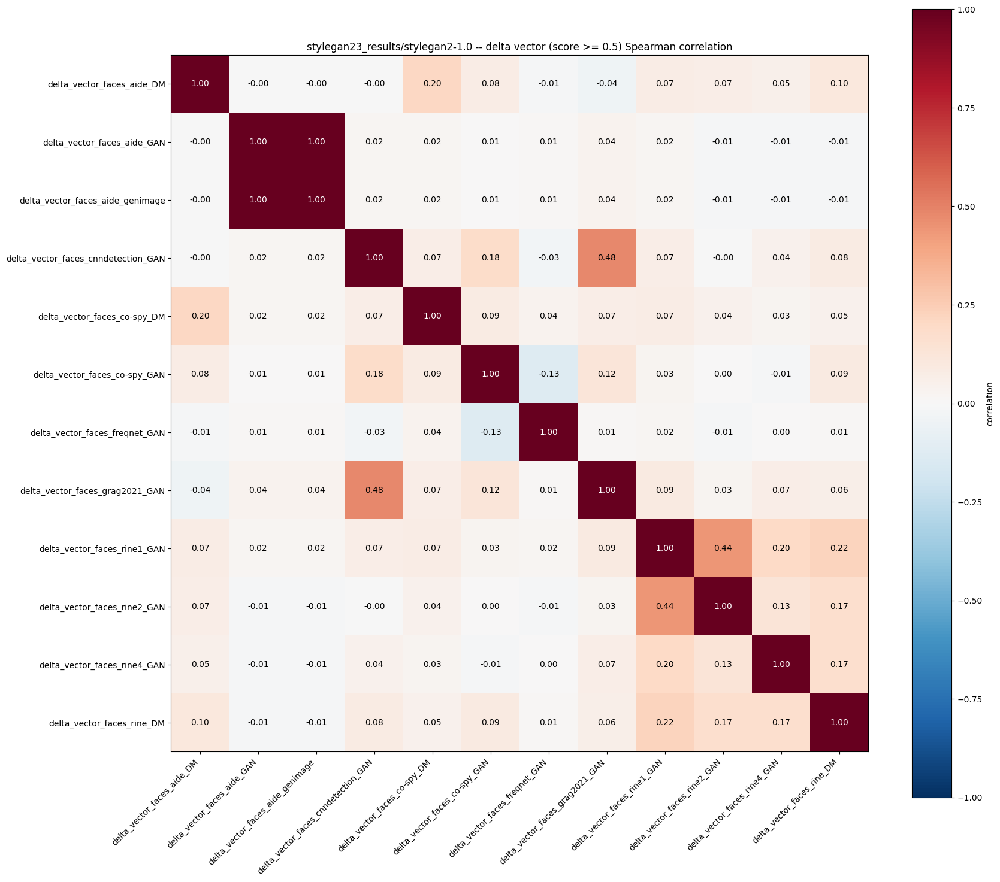

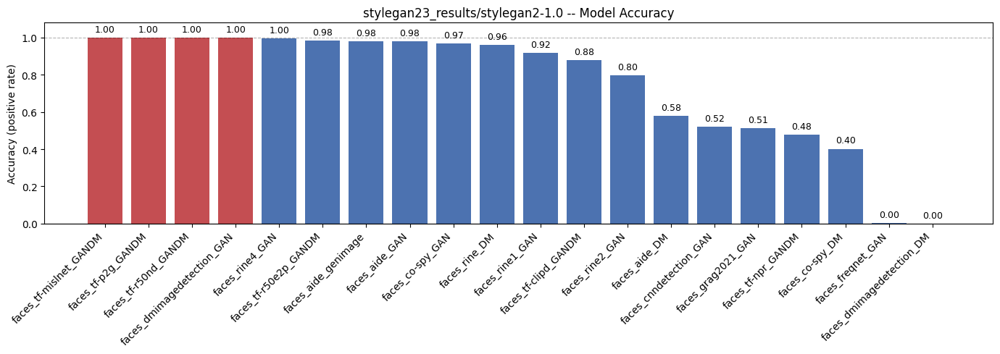


Processing correlations for stylegan23_results/stylegan3-0.5...
NOTE: excluding constant delta_vector column(s) from the delta correlation heatmaps (model predicted the same class for every image, so correlation with other models is undefined):
  - delta_vector_faces_dmimagedetection_DM: always 0 (0% positive rate) -- excluded


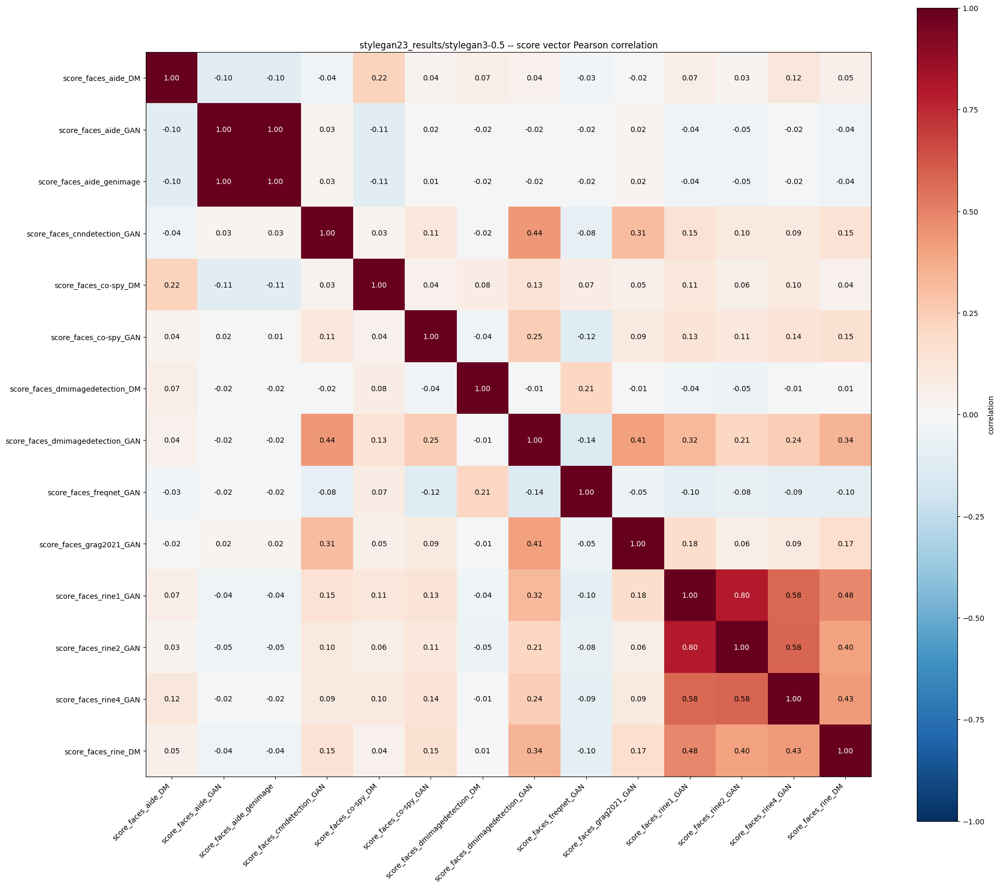

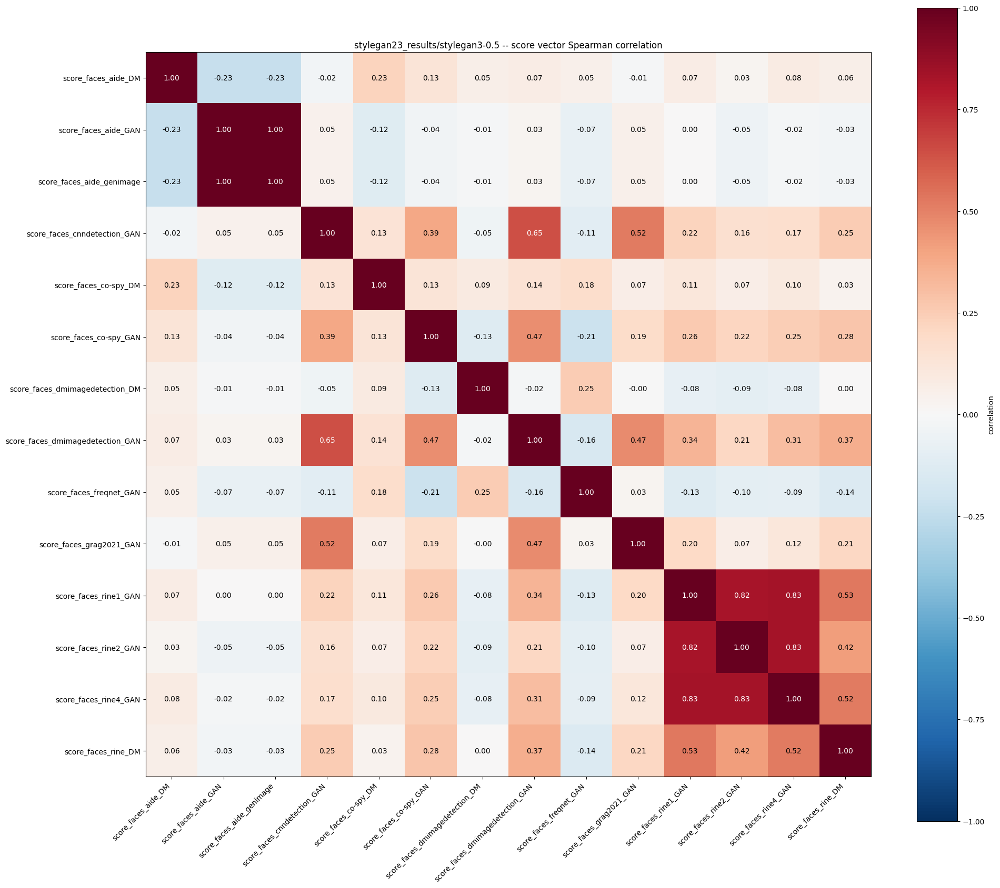

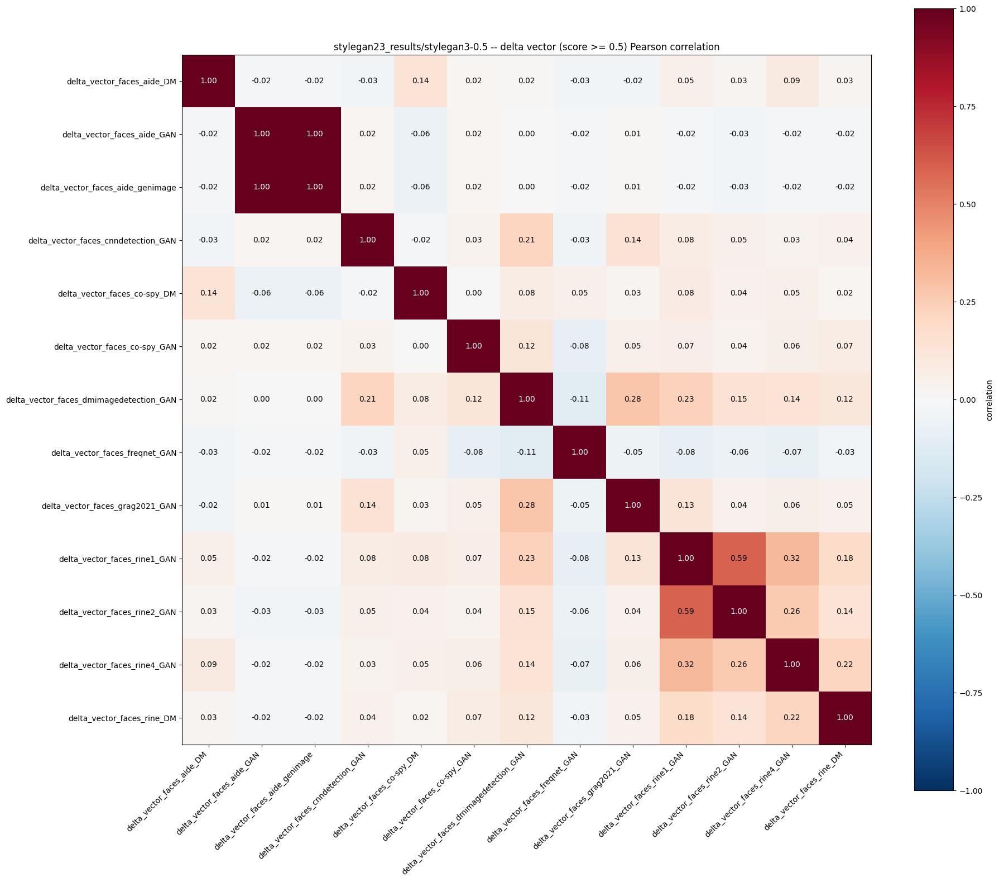

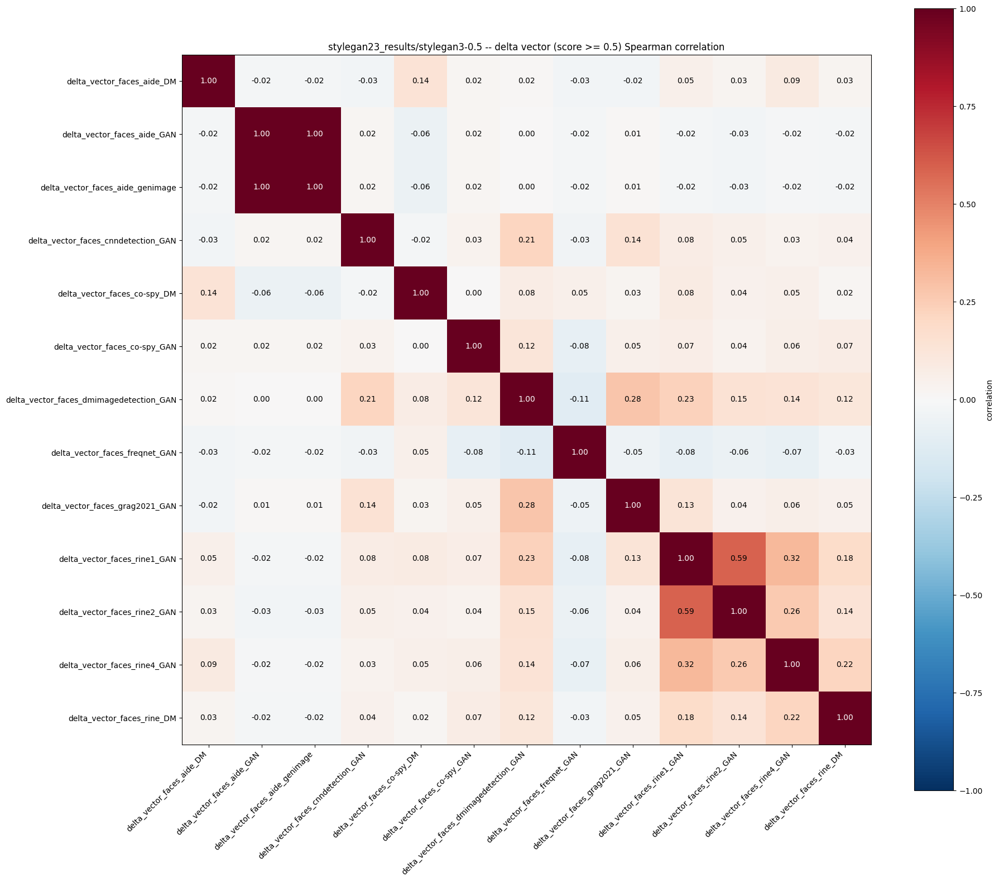

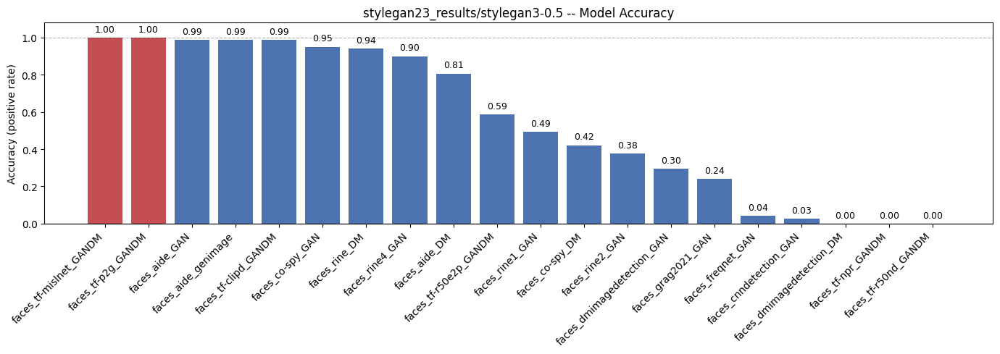


Processing correlations for stylegan23_results/stylegan3-0.7...
NOTE: excluding constant delta_vector column(s) from the delta correlation heatmaps (model predicted the same class for every image, so correlation with other models is undefined):
  - delta_vector_faces_dmimagedetection_DM: always 0 (0% positive rate) -- excluded


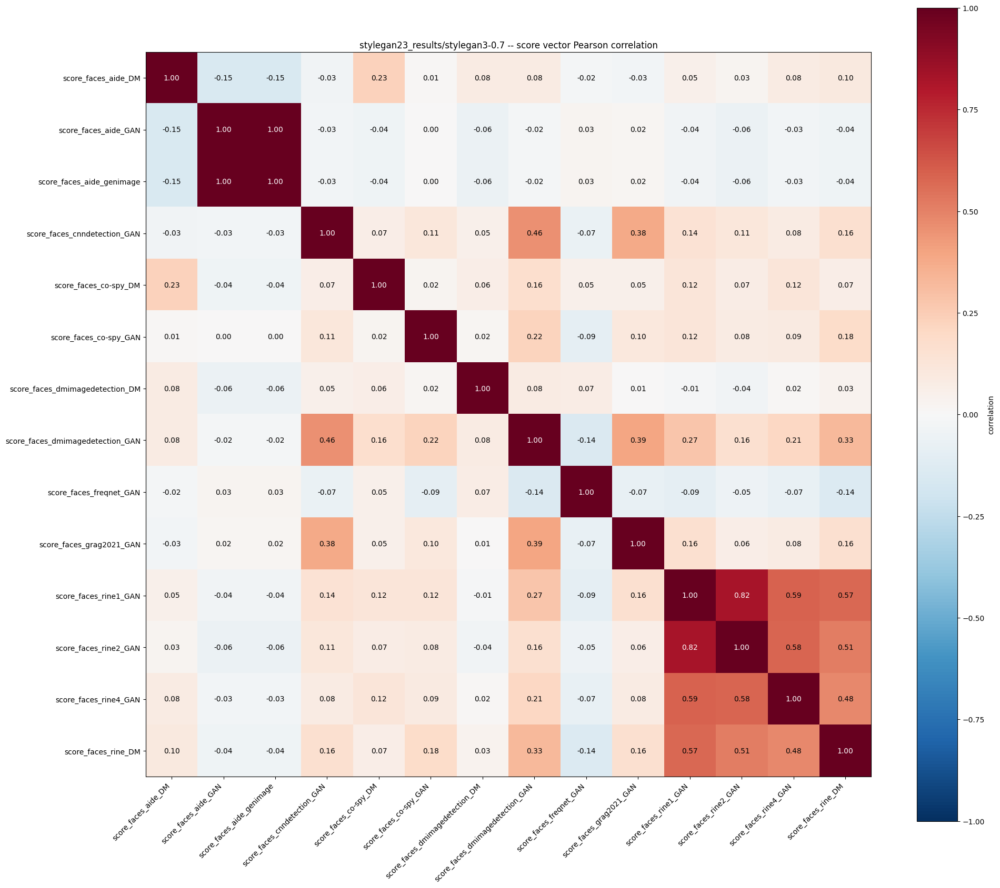

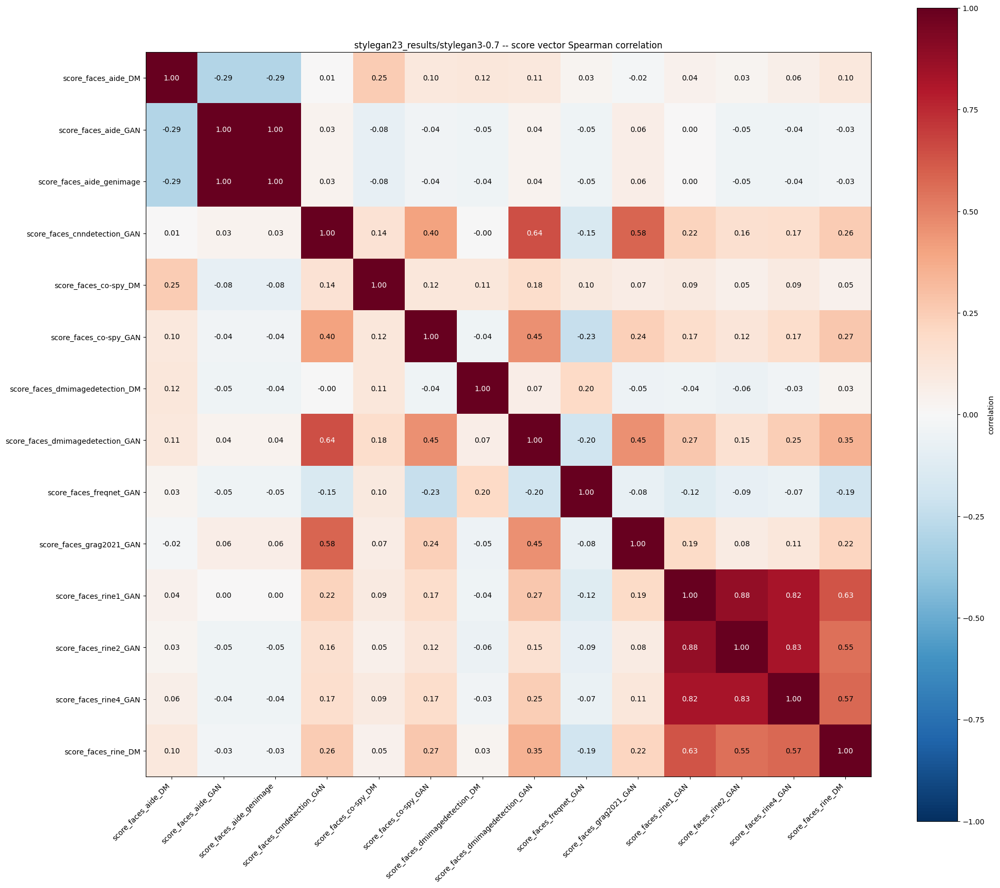

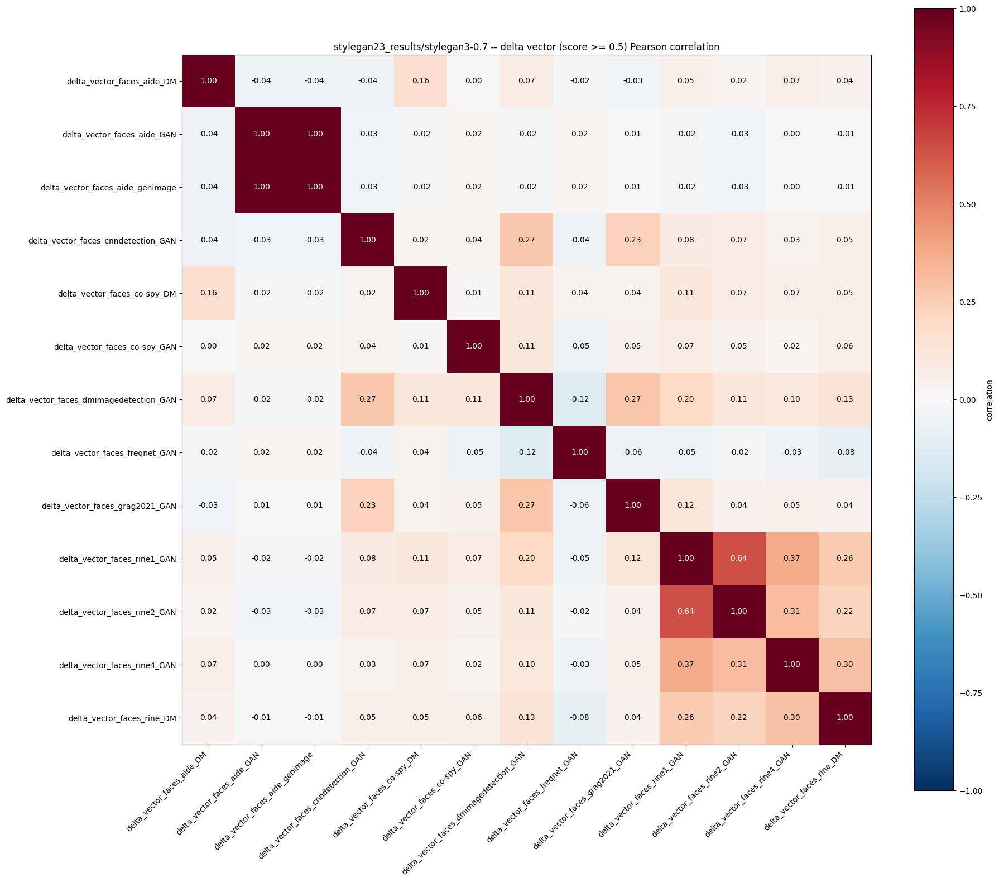

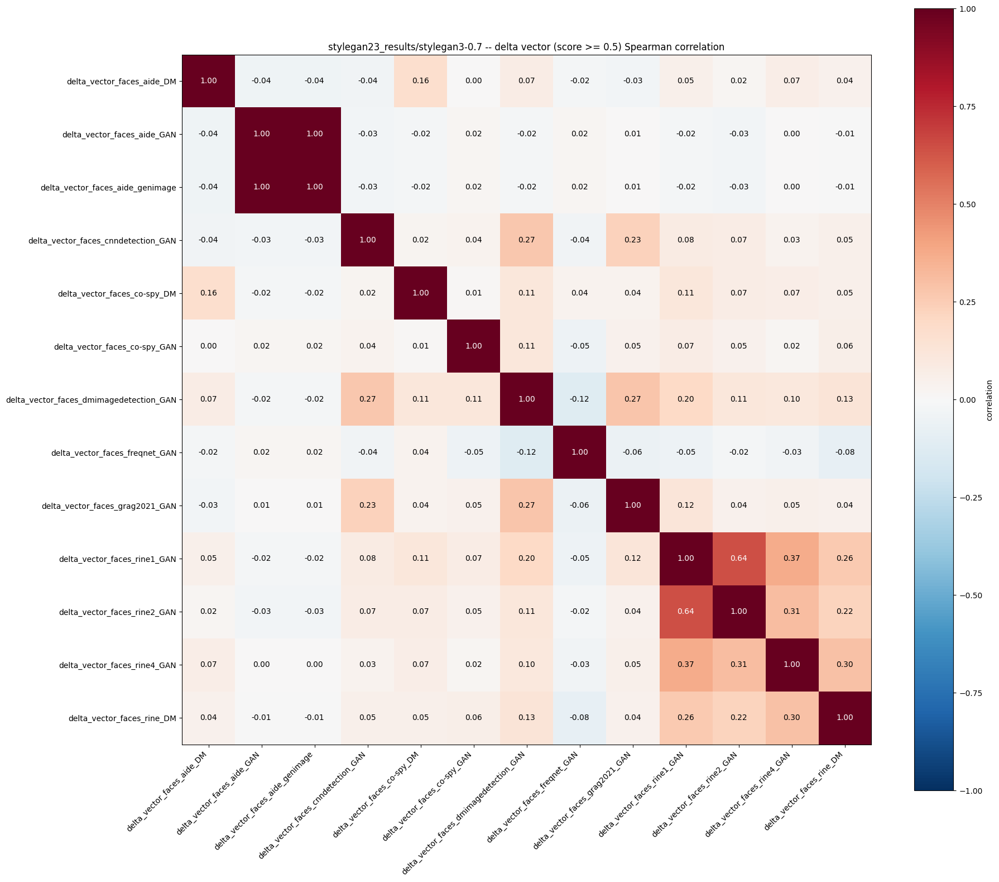

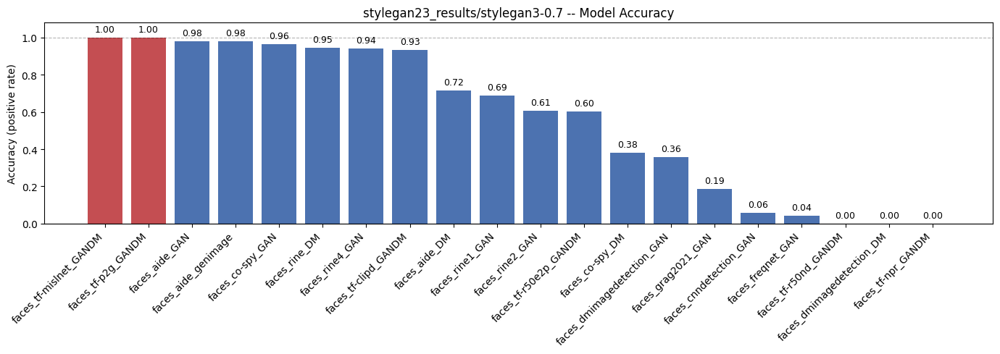

[stylegan23_results/stylegan2-0.5] Excluded models with 100% positive rate: faces_tf-p2g_GANDM, faces_tf-mislnet_GANDM, faces_dmimagedetection_GAN, faces_tf-r50nd_GANDM
[stylegan23_results/stylegan2-0.5] Oracle Accuracy: 100.00% (2599 / 2599)
--------------------------------------------------
[stylegan23_results/stylegan2-1.0] Excluded models with 100% positive rate: faces_tf-p2g_GANDM, faces_tf-mislnet_GANDM, faces_dmimagedetection_GAN, faces_tf-r50nd_GANDM
[stylegan23_results/stylegan2-1.0] Oracle Accuracy: 100.00% (2600 / 2600)
--------------------------------------------------
[stylegan23_results/stylegan3-0.5] Excluded models with 100% positive rate: faces_tf-mislnet_GANDM, faces_tf-p2g_GANDM
[stylegan23_results/stylegan3-0.5] Oracle Accuracy: 100.00% (5000 / 5000)
--------------------------------------------------
[stylegan23_results/stylegan3-0.7] Excluded models with 100% positive rate: faces_tf-mislnet_GANDM, faces_tf-p2g_GANDM
[stylegan23_results/stylegan3-0.7] Oracle Accurac

In [ ]:
PLOTS_OUTPUT_DIR = os.path.join(MAIN_RESULTS_DIR, 'plots')
os.makedirs(PLOTS_OUTPUT_DIR, exist_ok=True)

# Find all subfolders ending in '_results'
result_subfolders = [d for d in glob.glob(os.path.join(MAIN_RESULTS_DIR, '*')) if os.path.isdir(d) and d.endswith('_results')]

if not result_subfolders:
    print(f"No subfolders ending in '_results' found in {MAIN_RESULTS_DIR}")
else:
    print(f"Found {len(result_subfolders)} result subfolders: {[os.path.basename(f) for f in result_subfolders]}")

oracle_accuracies = {}

for drive_csv_dir in result_subfolders:
    print(f"\nProcessing folder: {drive_csv_dir}")
    folder_name = os.path.basename(drive_csv_dir)

    all_csvs = sorted(glob.glob(os.path.join(drive_csv_dir, '*.csv')))

    grouped_csvs = {}
    for path in all_csvs:
        fname = os.path.basename(path)
        # Find the first underscore to determine the generation model prefix
        match = re.match(r'([^_]+)_.*', fname)
        if match:
            group_name = match.group(1).lower() # e.g., 'stylegan2', 'stylegan3'
            if group_name not in grouped_csvs:
                grouped_csvs[group_name] = []
            grouped_csvs[group_name].append(path)
        else:
            # Handle files without an underscore or not matching the pattern
            if 'ungrouped' not in grouped_csvs:
                grouped_csvs['ungrouped'] = []
            grouped_csvs['ungrouped'].append(path)

    print(f'Found {len(all_csvs)} CSV(s) total in {drive_csv_dir}')
    for group_name, csv_list in grouped_csvs.items():
        print(f'  {group_name}: {len(csv_list)} file(s) -> {[os.path.basename(p) for p in csv_list]}')

    # --- Build combined tables ---
    combined_dataframes = {}
    for group_name_key, csv_list_val in grouped_csvs.items():
        group_prefix_for_extractor = f"{group_name_key}_"
        combined_df = build_combined_table(csv_list_val, group_prefix_for_extractor)
        if combined_df is not None:
            if combined_df.empty:
                print(f'WARNING: {group_name_key}_combined is empty (0 rows) due to mismatched filepaths. Skipping.')
                print(f"--- DEBUG: Investigating why {group_name_key} failed to combine ---")
                try:
                    common_index = None
                    for p in csv_list_val:
                        df_tmp = pd.read_csv(p)
                        if 'filepath' in df_tmp.columns:
                            idx = set(df_tmp['filepath'].dropna().values)
                            print(f"  {os.path.basename(p)}: {len(idx)} unique filepaths.")
                            if common_index is None:
                                common_index = idx
                            else:
                                prev_len = len(common_index)
                                common_index = common_index.intersection(idx)
                                print(f"    -> Intersection dropped from {prev_len} to {len(common_index)}")
                                if len(common_index) == 0:
                                    print("    -> ZERO INTERSECTION REACHED. Inspecting sample filepaths...")
                                    print(f"       Sample from current file: {list(idx)[:3]}")
                                    break
                except Exception as e:
                    print(f"  Error during debug: {e}")
            else:
                print(f'{group_name_key}_combined: {combined_df.shape[0]} images x {combined_df.shape[1]} columns')
                # Original instruction to save combined CSVs in the main results folder is removed
                combined_dataframes[group_name_key] = combined_df
        else:
            print(f'No CSVs found for group "{group_name_key}" in {folder_name}, skipping.')

    # --- Apply corrections/transformations ---
    for group_name_key, combined_df_val in combined_dataframes.items():
        # Drop 'patchforensics' related columns
        cols_to_drop = [c for c in combined_df_val.columns if 'patchforensics' in c.lower()]
        if cols_to_drop:
            combined_df_val = combined_df_val.drop(columns=cols_to_drop)
            print(f"Dropped from {group_name_key}_combined in {folder_name}: {cols_to_drop}")
            combined_dataframes[group_name_key] = combined_df_val # Update the dictionary

        # Removed commented-out Grag2021_GAN score flipping and error calculation as per user request.
        # The user requested no score flipping and no need to subtract labels.

    # --- Run correlations and plot heatmaps/bar charts ---
    for group_name_key, combined_df_val in combined_dataframes.items():
        if combined_df_val is not None:
            print(f"\nProcessing correlations for {folder_name}/{group_name_key}...")
            corrs = compute_correlations(combined_df_val)

            # Removed saving correlation CSVs to the main results folder

            # Calculate Spearman correlation for scores directly here (excluding 'tf-' baselines)
            score_cols = [c for c in combined_df_val.columns if c.startswith('score_') and not re.search(r'(^|_)tf[-_]', c.lower())]
            score_spearman = combined_df_val[score_cols].corr(method='spearman')

            # Save plots to the plots output directory, prefixed by subfolder name
            plot_corr_heatmap(corrs['score_pearson'], f'{folder_name}/{group_name_key} -- score vector Pearson correlation', os.path.join(PLOTS_OUTPUT_DIR, f'{folder_name}_{group_name_key}_score_correlation_pearson.png'))
            plot_corr_heatmap(score_spearman, f'{folder_name}/{group_name_key} -- score vector Spearman correlation', os.path.join(PLOTS_OUTPUT_DIR, f'{folder_name}_{group_name_key}_score_correlation_spearman.png'))
            plot_corr_heatmap(corrs['delta_pearson'], f'{folder_name}/{group_name_key} -- delta vector (score >= 0.5) Pearson correlation', os.path.join(PLOTS_OUTPUT_DIR, f'{folder_name}_{group_name_key}_delta_correlation_pearson.png'))
            plot_corr_heatmap(corrs['delta_spearman'], f'{folder_name}/{group_name_key} -- delta vector (score >= 0.5) Spearman correlation', os.path.join(PLOTS_OUTPUT_DIR, f'{folder_name}_{group_name_key}_delta_correlation_spearman.png'))

            # Benchmark line can be customized if needed per group/folder
            benchmark = None # Default to no benchmark line for new groups/folders
            plot_accuracy_bar(combined_df_val, f'{folder_name}/{group_name_key}', f'{folder_name}/{group_name_key} -- Model Accuracy', os.path.join(PLOTS_OUTPUT_DIR, f'{folder_name}_{group_name_key}_accuracy_rate.png'), benchmark_line=benchmark)
        else:
            print(f'No {group_name_key} CSVs found for {folder_name}, skipping correlations.')

    # --- Compute oracle accuracy ---
    for group_name_key, combined_df_val in combined_dataframes.items():
        accuracy = compute_oracle_accuracy(combined_df_val, f'{folder_name}/{group_name_key}')
        if accuracy is not None:
            oracle_accuracies[f'{folder_name}/{group_name_key}'] = accuracy


In [ ]:
# ============================================================
# AUROC pipeline (real-vs-fake, per model, per generator group)
# ============================================================
# Reads each model's score column directly from its own CSV (NOT via the
# inner-joined `combined_dataframes` tables used above for the correlation
# heatmaps). This matters: the inner join restricts every model in a group
# to the intersection of images all models share, which can shrink a model's
# usable image count below the full set. For AUROC we want each model's
# AUROC computed against its OWN full image set -- all ~20K FFHQ real
# images and all ~10K images of the fake subset in question -- not an
# intersection with other models.
#
# Model names are matched CASE-INSENSITIVELY (e.g. "cnndetection_GAN" and
# "CNNDetection_GAN" are treated as the SAME model), since the same model
# shows up with inconsistent capitalization across different CSV filenames.
# The first-seen original casing is kept as the display name for tables/plots.

import numpy as np
from sklearn.metrics import roc_auc_score
import os
import glob
import re
import pandas as pd

raw_scores_by_key = {}     # {group_key: {model_key_lower: pd.Series(score, index=filepath)}}
model_display_names = {}   # {model_key_lower: original-cased name, first one seen}

for drive_csv_dir in result_subfolders:
    folder_name = os.path.basename(drive_csv_dir)
    all_csvs = sorted(glob.glob(os.path.join(drive_csv_dir, '*.csv')))

    grouped_csvs = {}
    for path in all_csvs:
        fname = os.path.basename(path)
        match = re.match(r'([^_]+)_.*', fname)
        group_name = match.group(1).lower() if match else 'ungrouped'

        # Ignore generic stylegan, stylegan2, and stylegan3 groups
        if group_name in ['stylegan', 'stylegan2', 'stylegan3']:
            continue

        grouped_csvs.setdefault(group_name, []).append(path)

    for group_name_key, csv_list_val in grouped_csvs.items():
        group_prefix = f"{group_name_key}_"
        per_model_scores = {}
        seen_models = {}  # {model_key_lower: source filename}
        for path in csv_list_val:
            fname = os.path.basename(path)
            if 'patchforensics' in fname.lower():
                continue
            try:
                df = pd.read_csv(path)
            except Exception as e:
                print(f"ERROR reading {fname}: {e}. Skipping.")
                continue
            if 'filepath' not in df.columns or 'score' not in df.columns:
                print(f"WARNING: {fname} missing filepath/score column. Skipping.")
                continue
            model = extract_model_name(path, group_prefix)
            model_key = model.lower()
            if model_key in seen_models:
                print(f'WARNING: duplicate model "{model}" (case-insensitive match with '
                      f'"{model_display_names.get(model_key, model_key)}") in '
                      f'{folder_name}/{group_name_key} -- skipping {fname} '
                      f'(already used by {seen_models[model_key]})')
                continue
            seen_models[model_key] = fname
            model_display_names.setdefault(model_key, model)
            per_model_scores[model_key] = df.set_index('filepath')['score'].sort_index()
        raw_scores_by_key[f'{folder_name}/{group_name_key}'] = per_model_scores

print(f"Rebuilt raw (non-joined) per-model scores for {len(raw_scores_by_key)} groups "
      "(model names matched case-insensitively):")
for k, v in raw_scores_by_key.items():
    sizes = {model_display_names[mk]: len(s) for mk, s in v.items()}
    print(f"  {k}: {len(v)} models -- image counts: {sizes}")

# Identify the real-image (FFHQ) group -- everything else is a fake-image group.
ffhq_keys = [k for k in raw_scores_by_key if 'ffhq' in k.lower()]
if len(ffhq_keys) != 1:
    raise ValueError(f"Expected exactly one FFHQ (real-image) group, found: {ffhq_keys}")
ffhq_key = ffhq_keys[0]
ffhq_scores = raw_scores_by_key[ffhq_key]
print(f"\nUsing '{ffhq_key}' as the real-image (label=0) reference for AUROC --")
print("each model's full FFHQ score vector, not intersected with other models.")

Rebuilt raw (non-joined) per-model scores for 12 groups (model names matched case-insensitively):
  sd3_results/sd3: 20 models -- image counts: {'faces_aide_DM': 10000, 'faces_aide_GAN': 10000, 'faces_aide_genimage': 10000, 'faces_cnndetection_GAN': 10000, 'faces_co-spy_DM': 10000, 'faces_co-spy_GAN': 10000, 'faces_dmimagedetection_DM': 10000, 'faces_dmimagedetection_GAN': 10000, 'faces_freqnet_GAN': 10000, 'faces_grag2021_GAN': 10000, 'faces_rine1_GAN': 10000, 'faces_rine2_GAN': 10000, 'faces_rine4_GAN': 10000, 'faces_rine_DM': 10000, 'faces_tf-clipd_GANDM': 10000, 'faces_tf-mislnet_GANDM': 10000, 'faces_tf-npr_GANDM': 10000, 'faces_tf-p2g_GANDM': 10000, 'faces_tf-r50e2p_GANDM': 10000, 'faces_tf-r50nd_GANDM': 10000}
  ffhq_results/ffhq: 20 models -- image counts: {'faces_aide_DM': 20000, 'faces_aide_GAN': 20000, 'faces_aide_genimage': 20000, 'faces_cnndetection_GAN': 20000, 'faces_co-spy_DM': 20000, 'faces_co-spy_GAN': 20000, 'faces_dmimagedetection_DM': 20000, 'faces_dmimagedetection

In [ ]:
# ------------------------------------------------------------
# Baseline models: models whose name contains a "tf-"/"tf_" token (the
# TrueFake benchmark baselines -- tf-clipd, tf-mislnet, tf-npr, tf-r50nd,
# tf-r50e2p). NOTE: because of how the group prefix is stripped, these come
# through as e.g. "faces_tf-clipd_GANDM" rather than literally starting with
# "tf" -- this checks for a "tf-"/"tf_" token anywhere in the name so the
# actual TrueFake baselines are still caught correctly. The check lowercases
# internally, so it's case-insensitive regardless of input casing.
def is_baseline_model(model_name):
    return re.search(r'(^|_)tf[-_]', model_name.lower()) is not None

# ------------------------------------------------------------
# AUROC per model per fake-image group: pairs the group's full fake (label=1)
# score vector with the model's full FFHQ real (label=0) score vector --
# i.e. all available FFHQ images (~20K) vs. all available images of the
# fake subset in question (~10K), each read straight from that model's own
# CSV (see raw_scores_by_key above), not reduced by any cross-model join.
#
# Models are matched via the case-insensitive key already built into
# raw_scores_by_key/model_display_names above, and results are reported
# under the display name (first-seen original casing) -- so e.g.
# "cnndetection_GAN" and "CNNDetection_GAN" are counted and analyzed as ONE
# model, not two.
#
# KNOWN DATA GAP (as of this run): none of the 'tf-' baseline models have any
# predictions on FFHQ (real images) anywhere in Drive, and they only have
# fake-image predictions for the sd2_faces / sdxl_faces groups. So baseline
# AUROC cannot currently be computed for ANY group -- this is expected and
# will resolve itself once baseline-vs-FFHQ predictions are added.
auroc_results = {}          # {group_key: {display_name: auroc}}
auroc_n_counts = {}         # {group_key: {display_name: (n_real, n_fake)}}
missing_ffhq_pairing = {}   # {group_key: [display names skipped]}

for key, per_model_scores in raw_scores_by_key.items():
    if key == ffhq_key:
        continue
    per_model_auroc = {}
    per_model_n = {}
    skipped = []
    for model_key, fake_series in per_model_scores.items():
        display_name = model_display_names[model_key]

        # Prepend 'faces_' to model_key if not already present for FFHQ lookup
        ffhq_lookup_key = model_key
        if 'faces_' not in ffhq_lookup_key:
            ffhq_lookup_key = 'faces_' + ffhq_lookup_key

        if ffhq_lookup_key not in ffhq_scores:
            skipped.append(display_name)
            continue
        real_scores = ffhq_scores[ffhq_lookup_key].values
        fake_vals = fake_series.values
        y_true = np.concatenate([np.zeros(len(real_scores)), np.ones(len(fake_vals))])
        y_score = np.concatenate([real_scores, fake_vals])
        try:
            per_model_auroc[display_name] = roc_auc_score(y_true, y_score)
            per_model_n[display_name] = (len(real_scores), len(fake_vals))
        except ValueError as e:
            print(f"  Could not compute AUROC for {key}/{display_name}: {e}")
    auroc_results[key] = per_model_auroc
    auroc_n_counts[key] = per_model_n
    if skipped:
        missing_ffhq_pairing[key] = skipped

print(f"Computed AUROC for {len(auroc_results)} generator groups.\n")
print("Image counts used per model (n_real FFHQ images, n_fake images) -- confirms")
print("the FULL available set is used for each model, not an intersection:")
for key, n_map in auroc_n_counts.items():
    for model, (n_real, n_fake) in n_map.items():
        print(f"  {key}/{model}: n_real={n_real}, n_fake={n_fake}")

if missing_ffhq_pairing:
    print("\nNOTE: the following models have no matching FFHQ (real-image) predictions,")
    print("so their AUROC could not be computed for these groups (this currently includes")
    print("ALL 'tf-' baselines -- see the note in this cell for why):")
    for key, models in missing_ffhq_pairing.items():
        print(f"  {key}: {models}")

# ------------------------------------------------------------
# Table with every AUROC number: rows = models, columns = generator groups.
auroc_table = pd.DataFrame(auroc_results).sort_index()
auroc_table.index.name = 'model'

def highlight_max(s):
    '''
    Highlights the maximum value in a Series in bold.
    '''
    # Ensure that NaN values are not considered for highlighting
    s_numeric = s.dropna()
    if s_numeric.empty:
        return ['' for _ in s] # Return empty styles if no numeric values

    is_max = s == s_numeric.max()
    return ['font-weight: bold' if v else '' for v in is_max]

display(auroc_table.style.format('{:.4f}', na_rep='-').apply(highlight_max, axis=0))

auroc_table.round(4).to_csv(os.path.join(PLOTS_OUTPUT_DIR, 'auroc_table.csv'))
print(f"\nSaved full AUROC table to {os.path.join(PLOTS_OUTPUT_DIR, 'auroc_table.csv')}")

Computed AUROC for 11 generator groups.

Image counts used per model (n_real FFHQ images, n_fake images) -- confirms
the FULL available set is used for each model, not an intersection:
  sd3_results/sd3/faces_aide_DM: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_aide_GAN: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_aide_genimage: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_cnndetection_GAN: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_co-spy_DM: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_co-spy_GAN: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_dmimagedetection_DM: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_dmimagedetection_GAN: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_freqnet_GAN: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_grag2021_GAN: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_rine1_GAN: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_rine2_GAN: n_real=20000, n_fake=10000
  sd3_results/sd3/faces_rine4_GAN: n

,sd3_results/sd3,flux_results/flux,stylegan1_results/stylegan-0.5,stylegan1_results/stylegan-0.7,sd1.5_results/sd1.5,sd2_results/sd2,sdxl_results/sdxl,stylegan23_results/stylegan2-0.5,stylegan23_results/stylegan2-1.0,stylegan23_results/stylegan3-0.5,stylegan23_results/stylegan3-0.7
model,,,,,,,,,,,
faces_aide_DM,0.6653,0.6469,0.7542,0.7124,0.8526,0.5453,0.4373,0.6652,0.5309,0.6814,0.6257
faces_aide_GAN,0.6812,0.5166,0.9759,0.9714,0.7649,0.5315,0.5387,0.9860,0.9874,0.9900,0.9883
faces_aide_genimage,0.7724,0.8763,0.7257,0.7324,0.9012,0.8772,0.8942,0.7903,0.8313,0.8153,0.8331
faces_cnndetection_GAN,0.9507,0.6383,0.9989,0.9991,0.4679,0.4887,0.7676,0.9917,0.9922,0.9468,0.9297
faces_co-spy_DM,0.8154,0.9837,0.7142,0.7164,0.9780,0.9002,0.9705,0.7244,0.7036,0.7412,0.7037
faces_co-spy_GAN,0.8729,0.8868,0.6231,0.6430,0.8155,0.6526,0.8827,0.7882,0.7664,0.6912,0.7199
faces_dmimagedetection_DM,1.0000,1.0000,0.5157,0.5081,1.0000,1.0000,1.0000,0.2919,0.4253,0.3127,0.3371
faces_dmimagedetection_GAN,0.8811,0.8126,1.0000,1.0000,0.9000,0.6323,0.8260,1.0000,1.0000,0.9778,0.9771
faces_freqnet_GAN,0.9755,0.7115,0.5545,0.5296,0.4946,0.4687,0.5591,0.4658,0.4559,0.5397,0.5220



Saved full AUROC table to /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/plots/auroc_table.csv


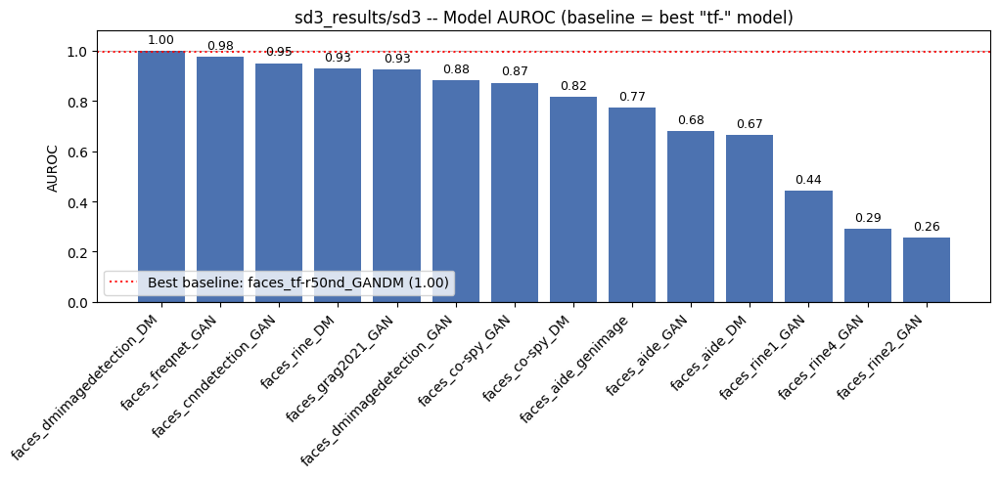

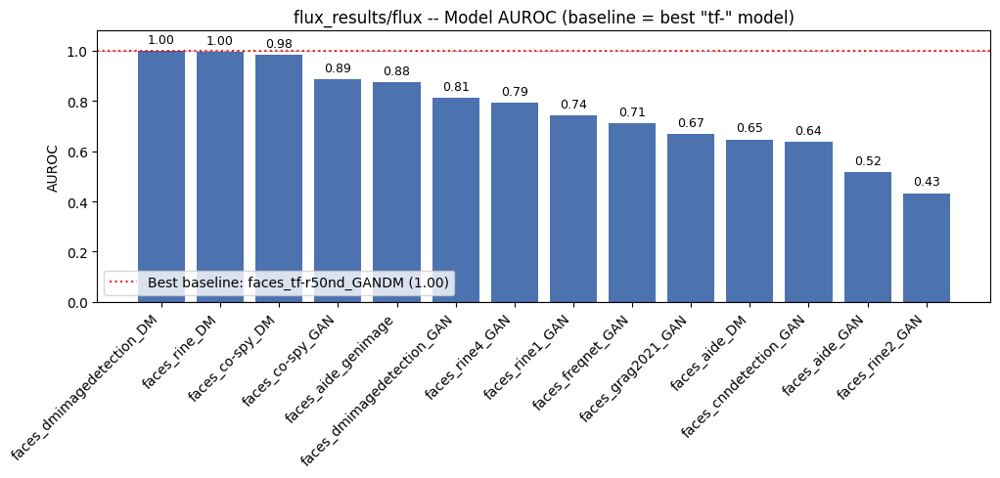

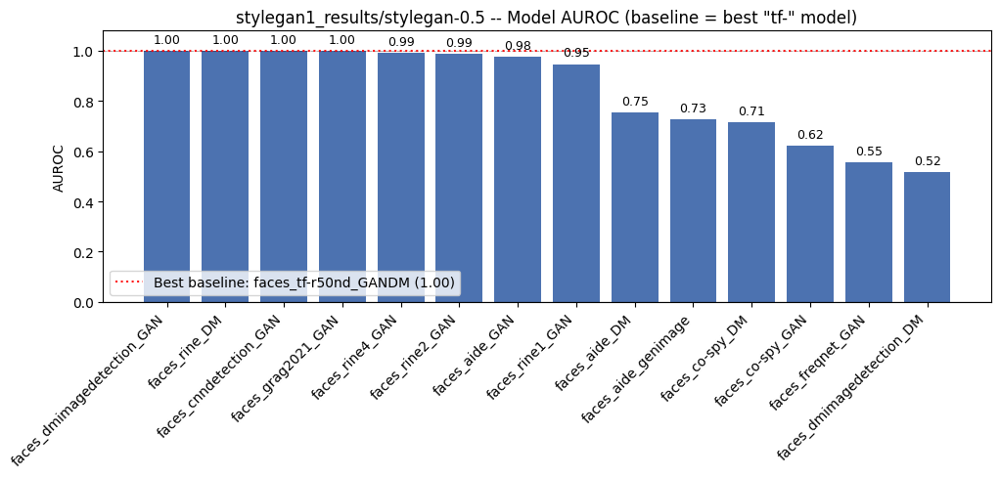

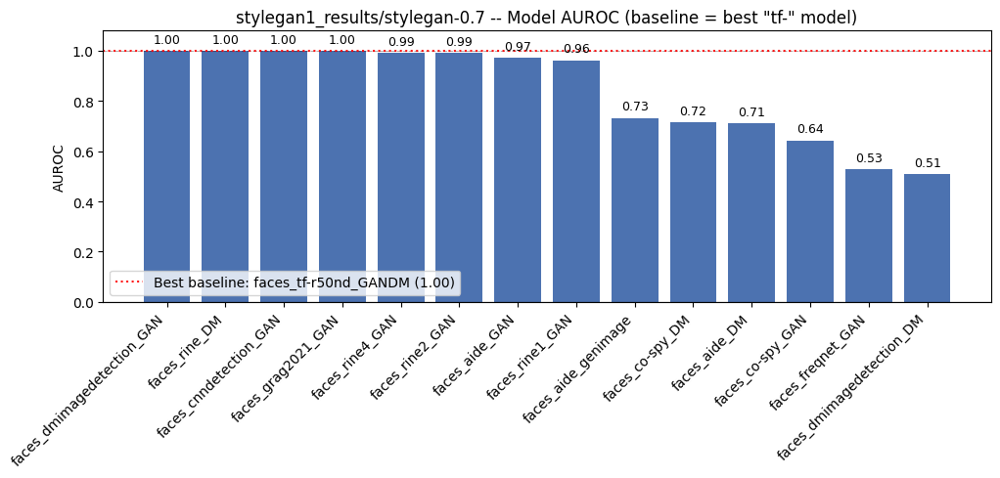

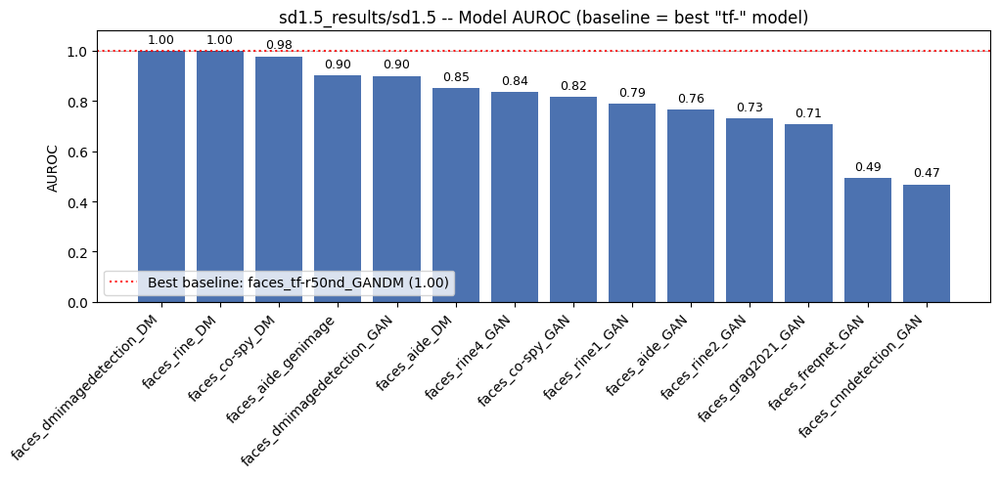

...

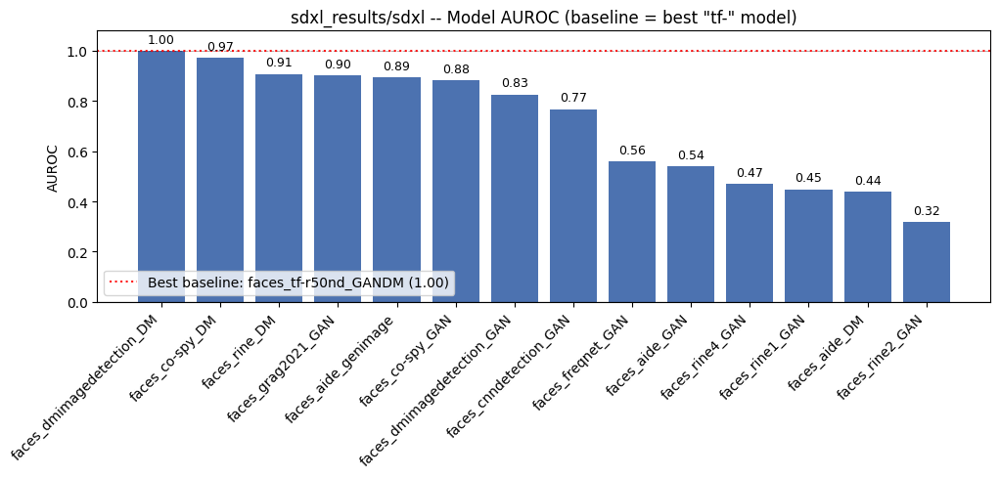

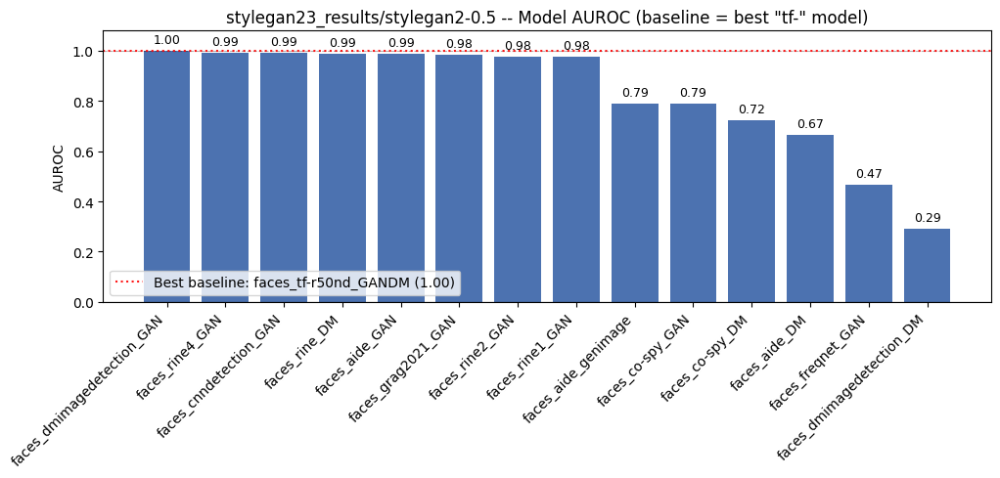

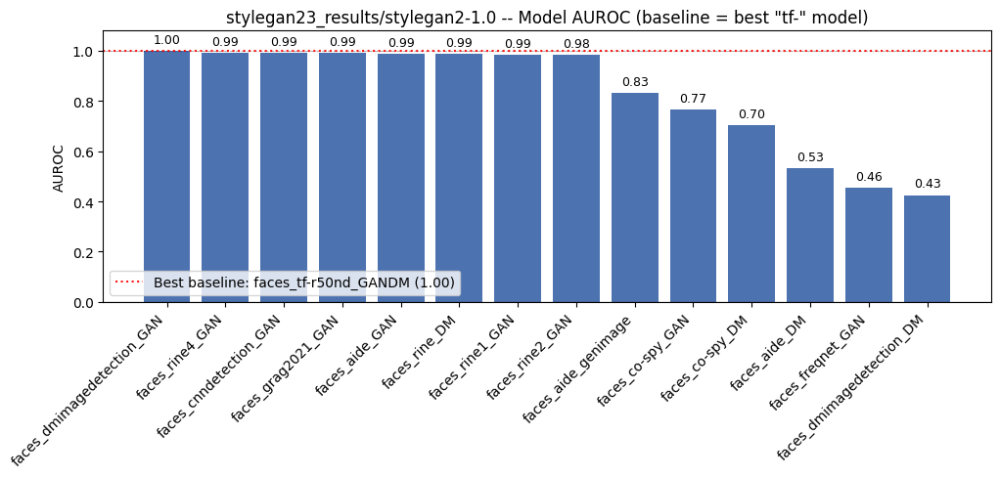

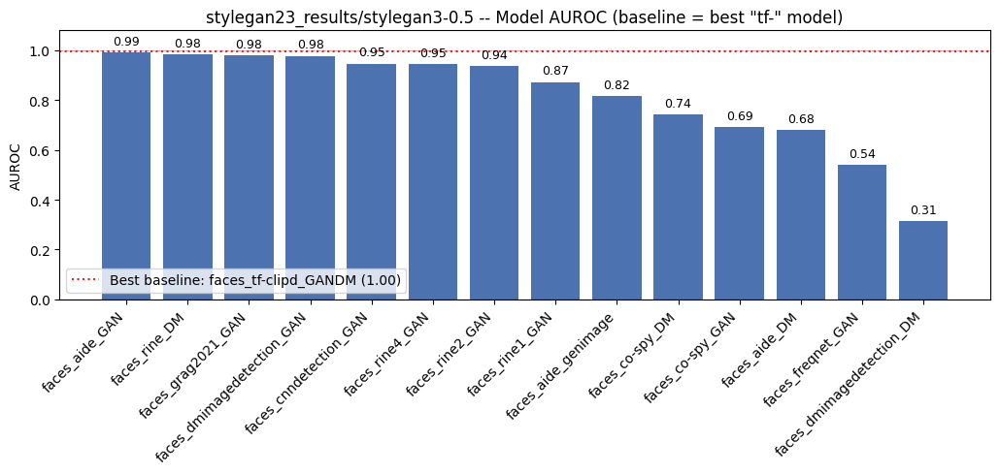

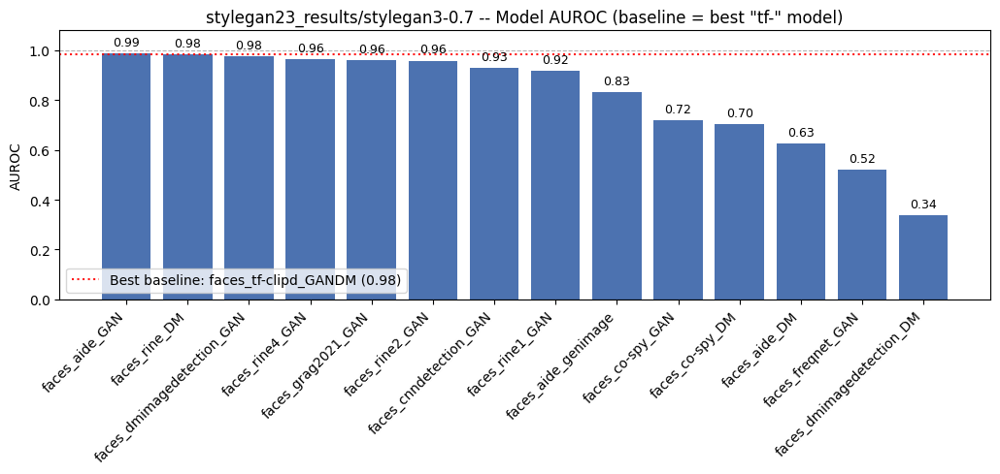

In [ ]:
# ------------------------------------------------------------
# Plot: one bar per non-baseline model's AUROC; the single highest AUROC
# among baseline ("tf-") models is drawn as a red dotted horizontal line
# instead of a bar -- skipped, with a printed note, if no baseline AUROC
# exists yet for that group (currently true for every group -- see the
# note in the previous cell).
def plot_auroc_bar(group_key, per_model_auroc, title, filename):
    baseline_scores = {m: a for m, a in per_model_auroc.items() if is_baseline_model(m)}
    nonbaseline_scores = {m: a for m, a in per_model_auroc.items() if not is_baseline_model(m)}

    if not nonbaseline_scores:
        print(f"[{group_key}] No non-baseline models with AUROC -- skipping plot.")
        return

    items = sorted(nonbaseline_scores.items(), key=lambda kv: kv[1], reverse=True)
    labels = [m for m, _ in items]
    values = [a for _, a in items]

    fig, ax = plt.subplots(figsize=(0.6 * len(labels) + 2, 5))
    bars = ax.bar(labels, values, color='#4c72b0')
    ax.set_ylim(0, 1.08)
    ax.set_ylabel('AUROC')
    ax.set_title(title)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axhline(1, color='black', linewidth=0.8, linestyle='--', alpha=0.3)

    if baseline_scores:
        best_name = max(baseline_scores, key=baseline_scores.get)
        best_auroc = baseline_scores[best_name]
        ax.axhline(best_auroc, color='red', linestyle=':', linewidth=1.5, alpha=0.9,
                   label=f'Best baseline: {best_name} ({best_auroc:.2f})')
        ax.legend(loc='lower left')
    else:
        print(f"[{group_key}] No baseline ('tf-') AUROC available yet -- no red line drawn.")

    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f'{value:.2f}',
                ha='center', va='bottom', fontsize=9)

    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

for key, per_model_auroc in auroc_results.items():
    plot_auroc_bar(
        key, per_model_auroc,
        f'{key} -- Model AUROC (baseline = best "tf-" model)',
        os.path.join(PLOTS_OUTPUT_DIR, f'{key.replace("/", "_")}_auroc.png')
    )

## Oracle Accuracy Summary

In [ ]:
import pandas as pd

# Convert the dictionary to a pandas Series, then to a DataFrame for display
oracle_summary_df = pd.DataFrame.from_dict(oracle_accuracies, orient='index', columns=['Oracle Accuracy'])
oracle_summary_df.index.name = 'Folder/Group'
oracle_summary_df = oracle_summary_df.sort_index()

display(oracle_summary_df.style.format({'Oracle Accuracy': '{:.2%}'}))

,Oracle Accuracy
Folder/Group,
sd1.5_results/sd1.5,100.00%
sd2_results/sd2,100.00%
sd3_results/sd3,100.00%
sdxl_results/sdxl,100.00%
stylegan1_results/stylegan,100.00%
stylegan1_results/stylegan-0.5,100.00%
stylegan1_results/stylegan-0.7,100.00%
stylegan23_results/stylegan2-0.5,100.00%
stylegan23_results/stylegan2-1.0,100.00%


Generating ROC and Violin plots for 20 detectors...


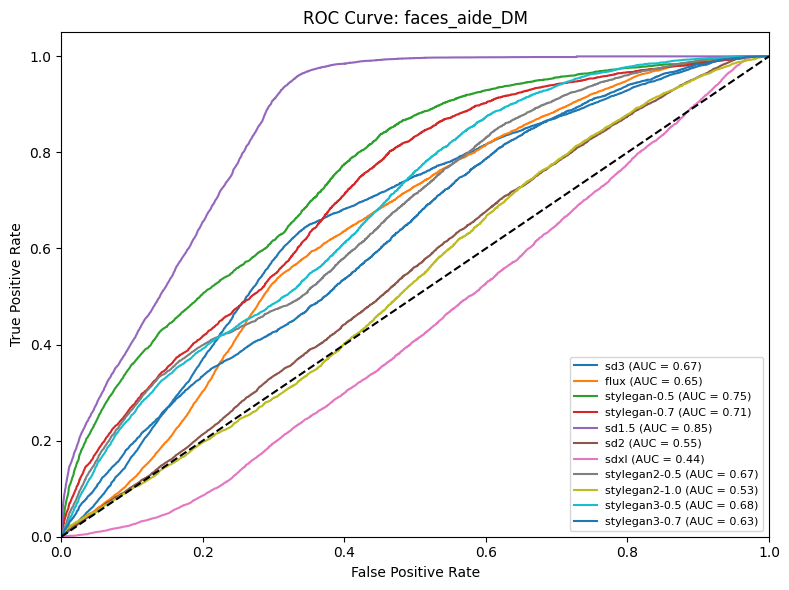

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


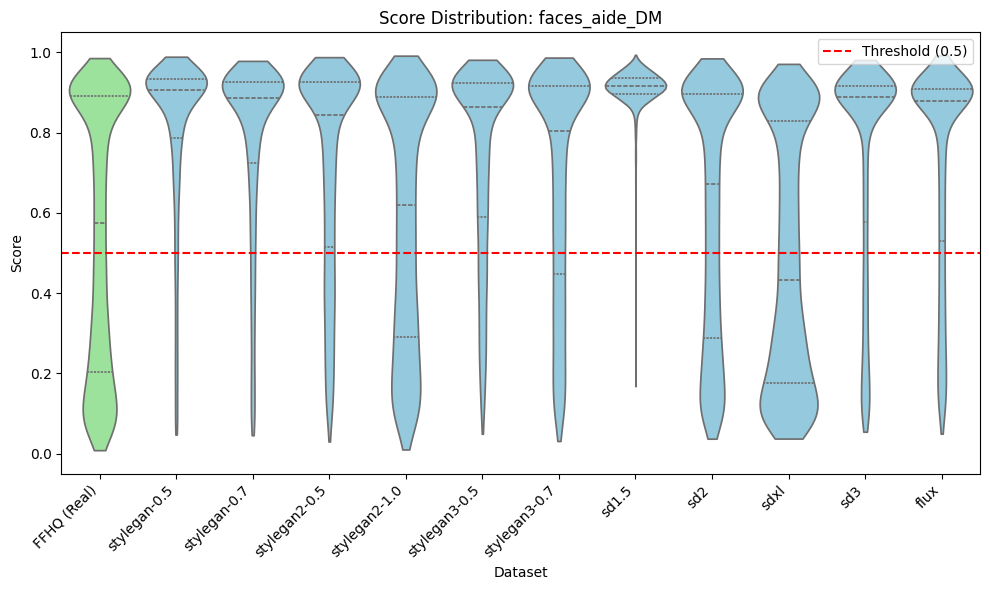

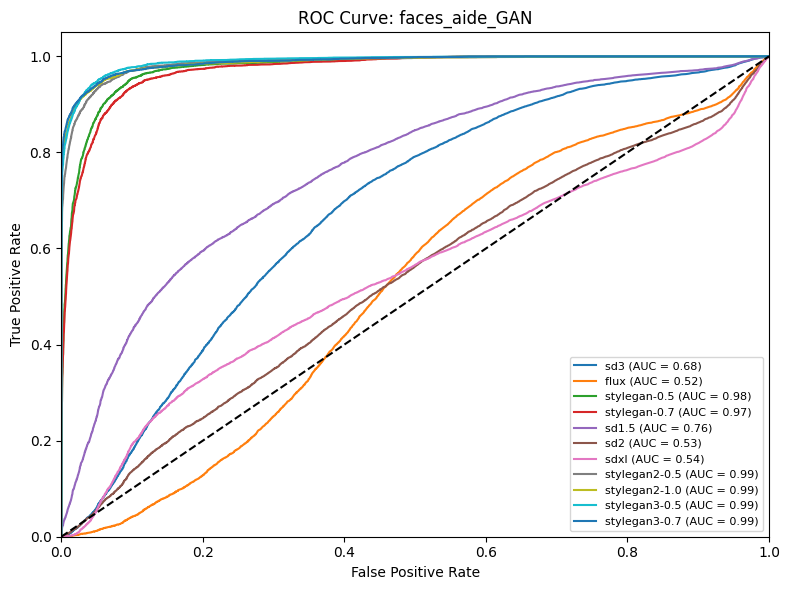

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


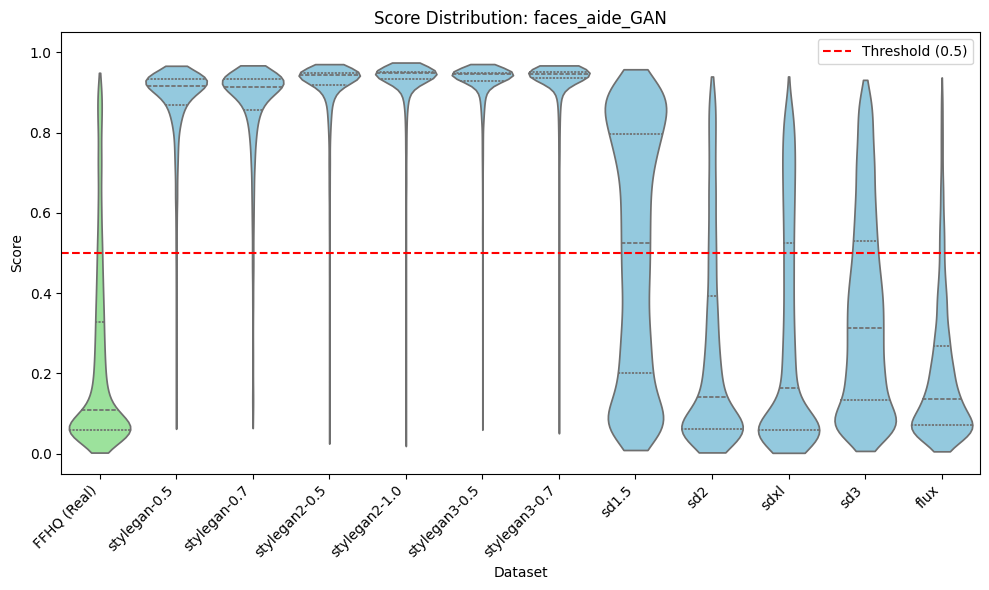

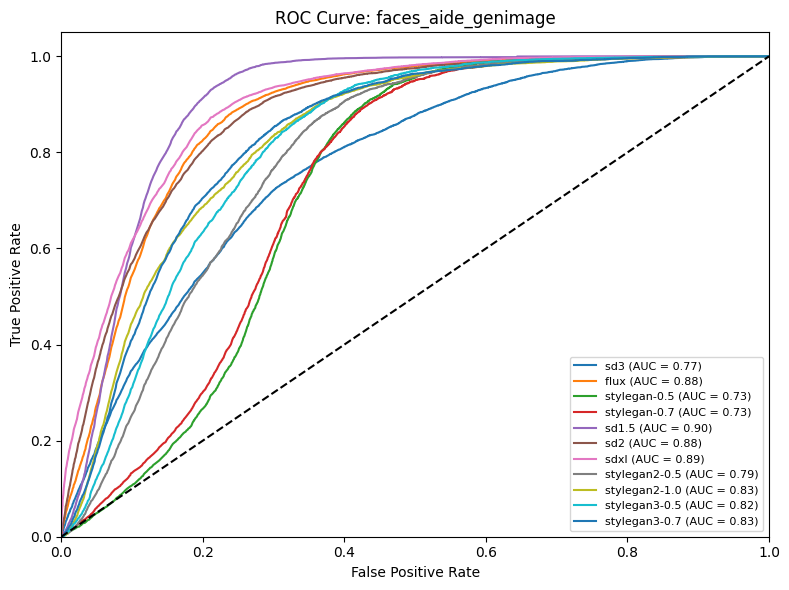

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


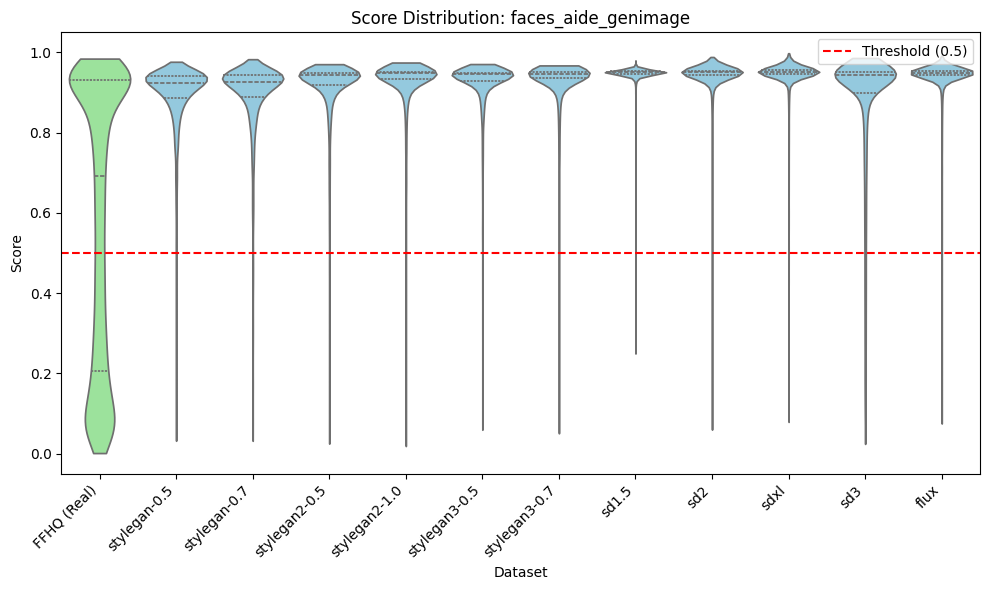

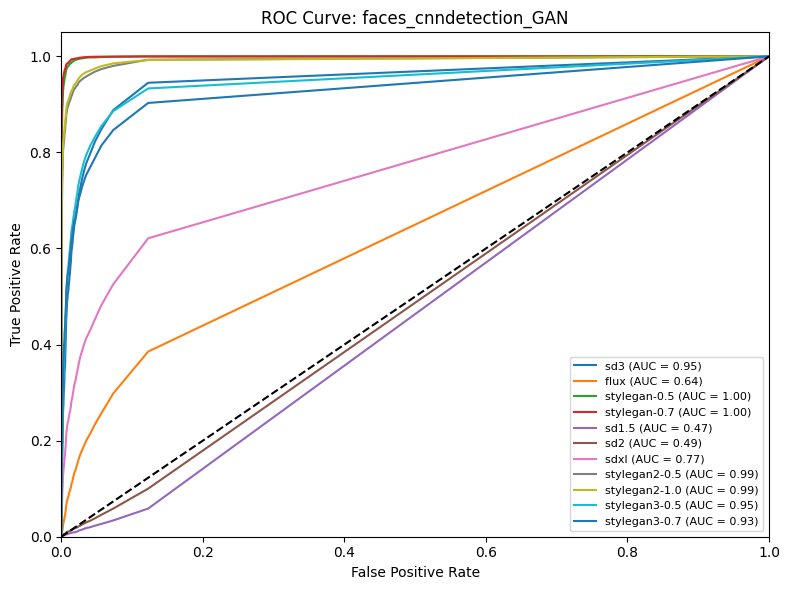

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


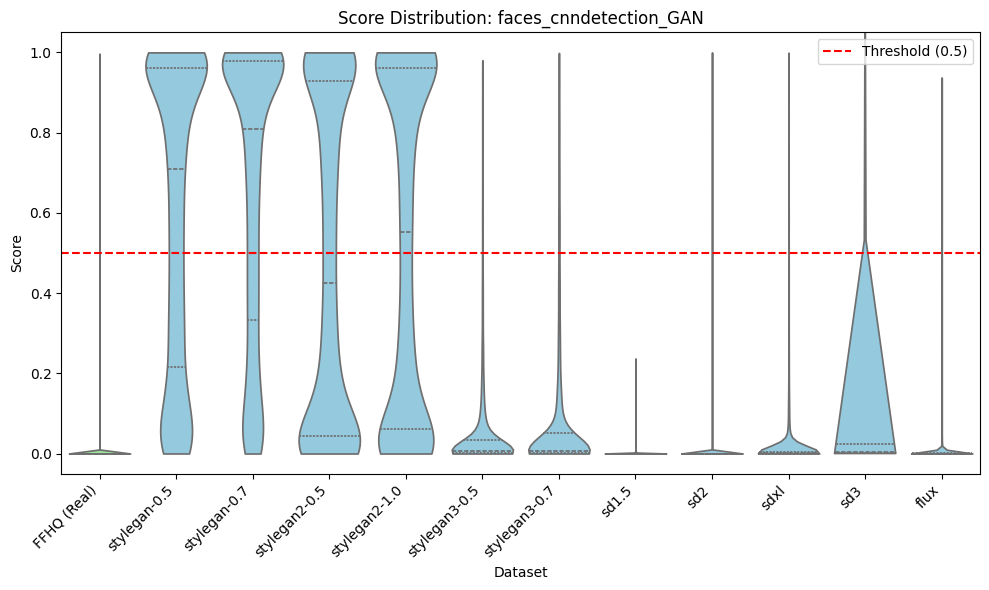

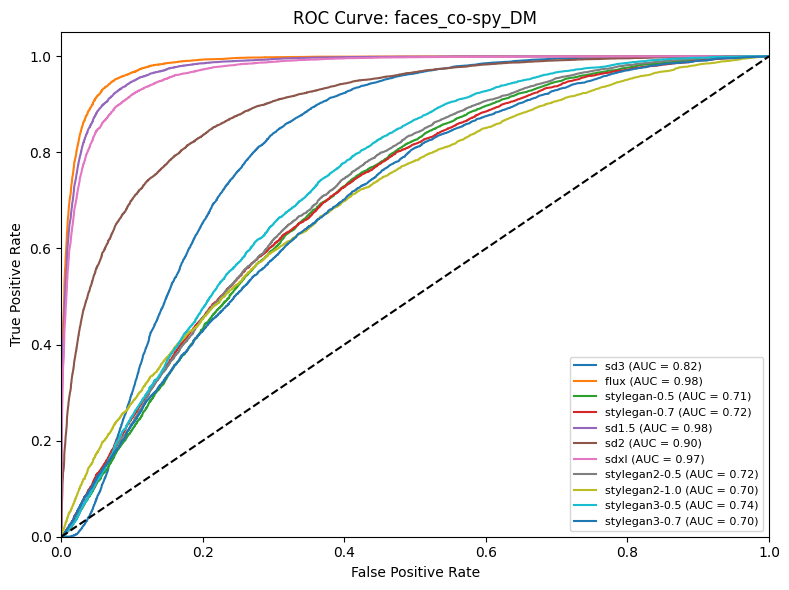

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


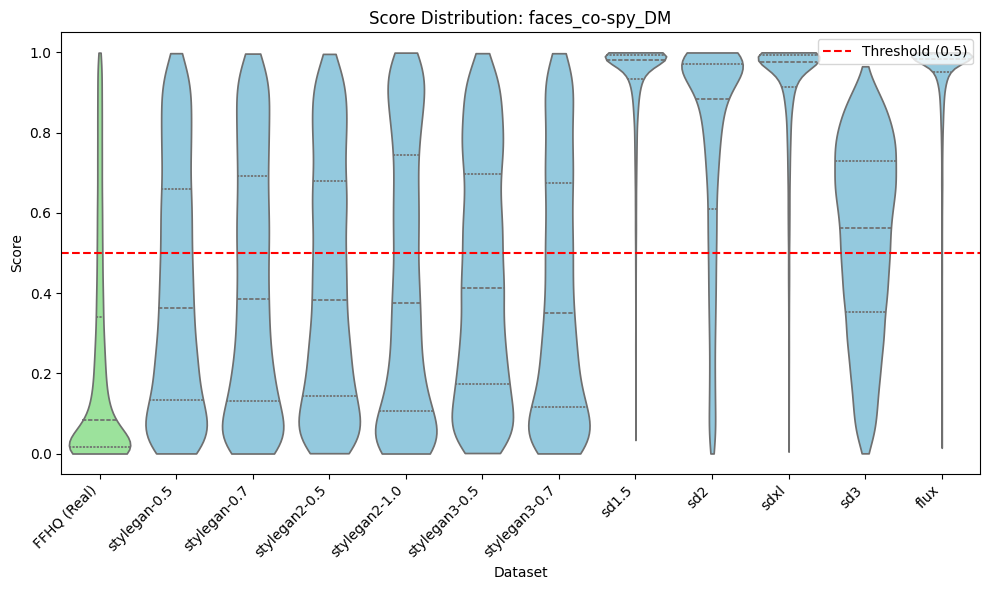

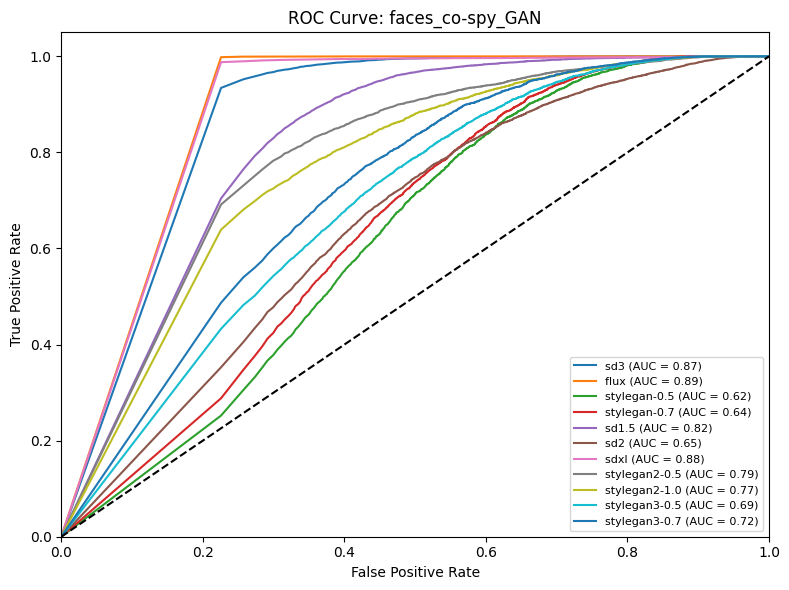

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


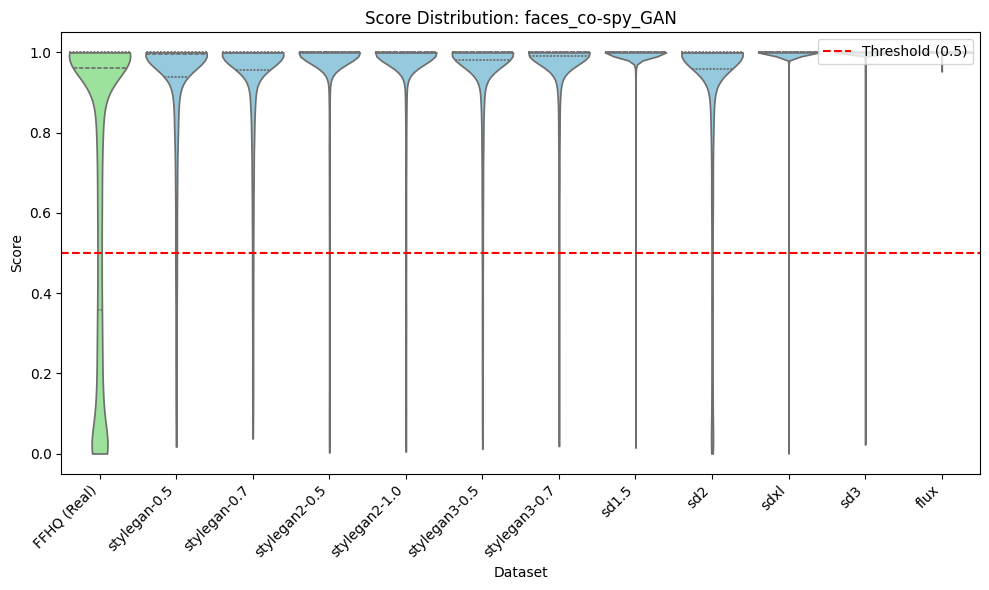

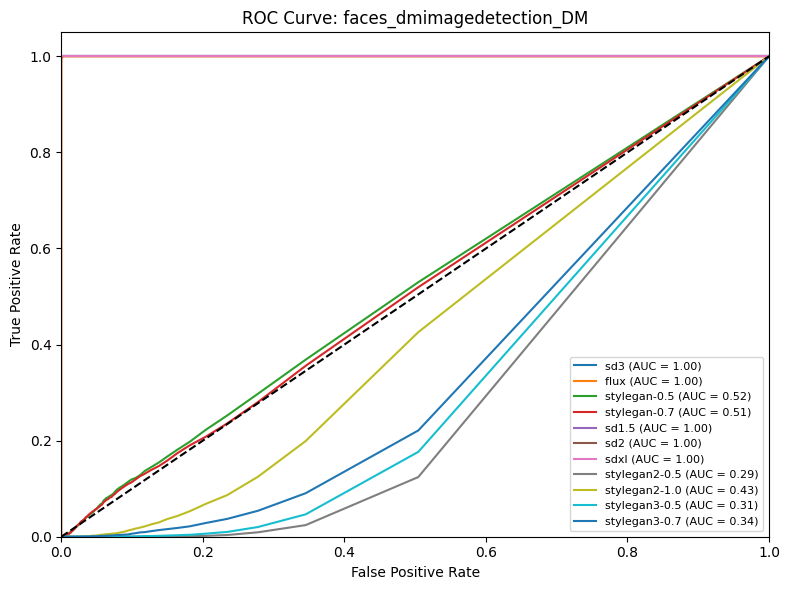

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


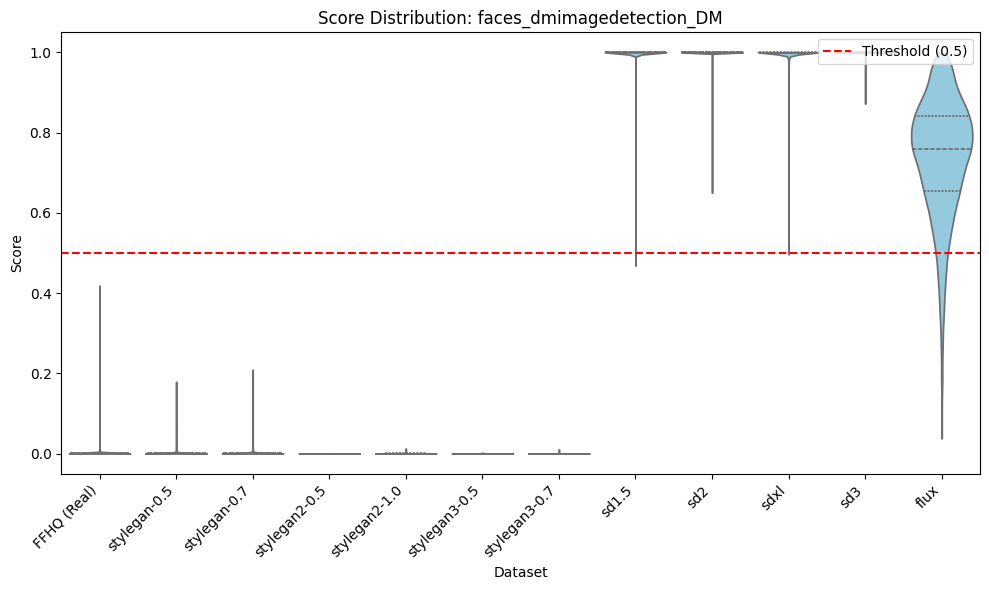

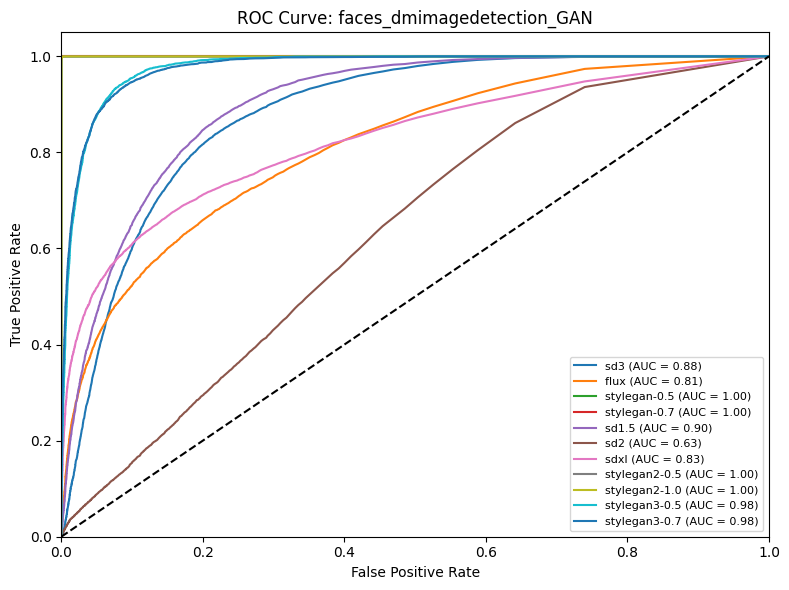

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


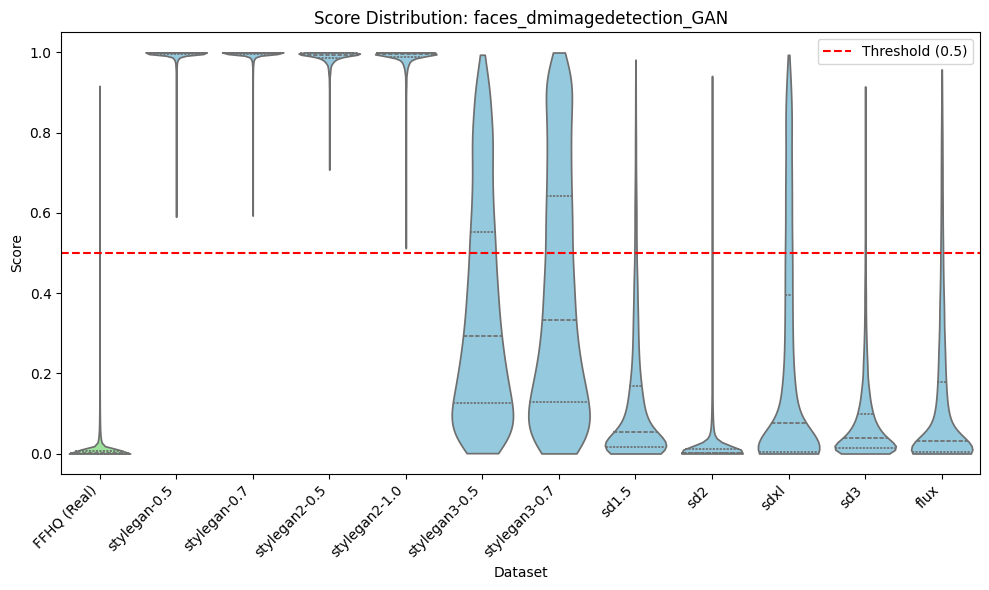

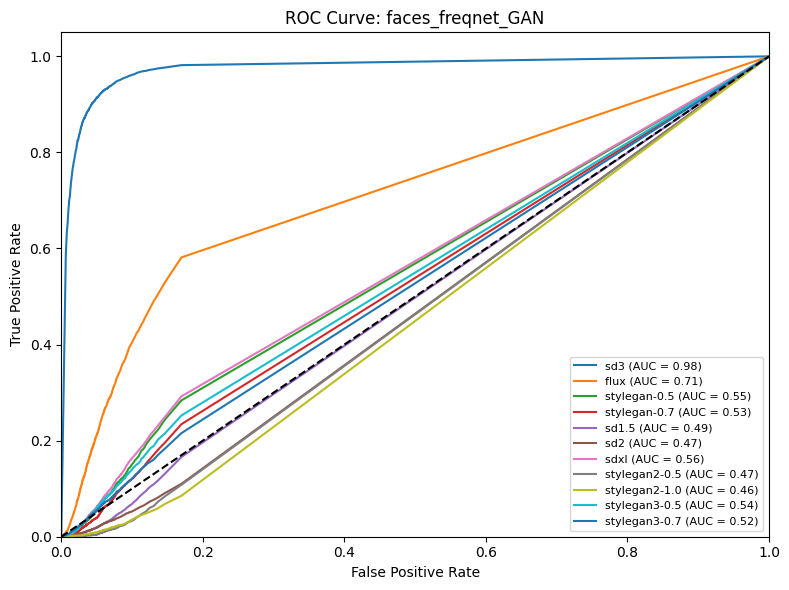

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


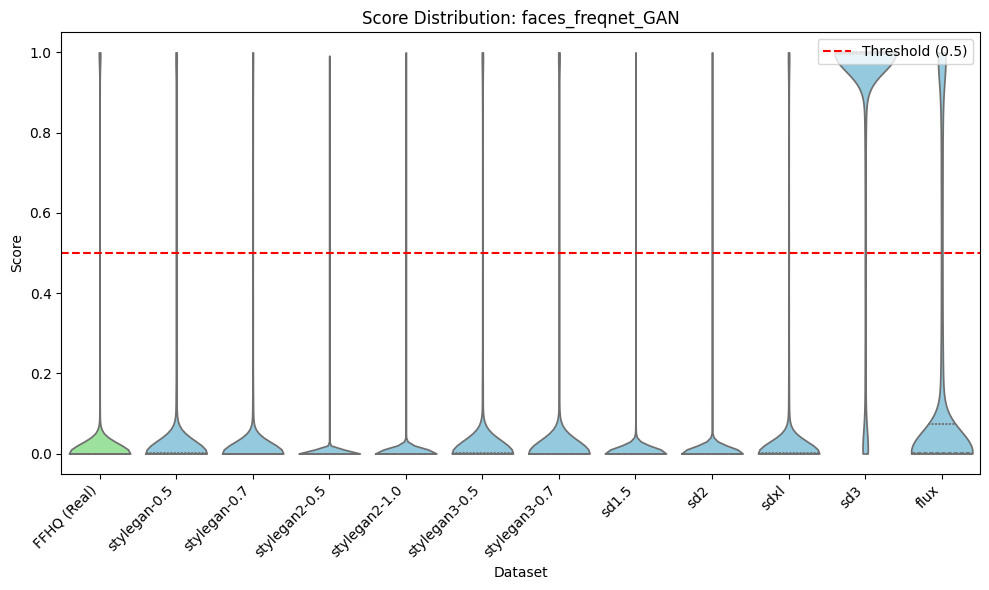

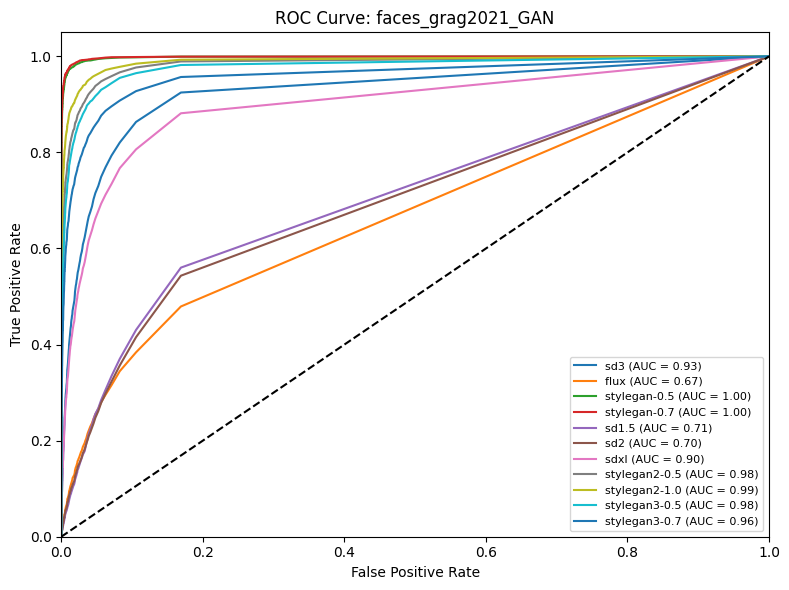

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


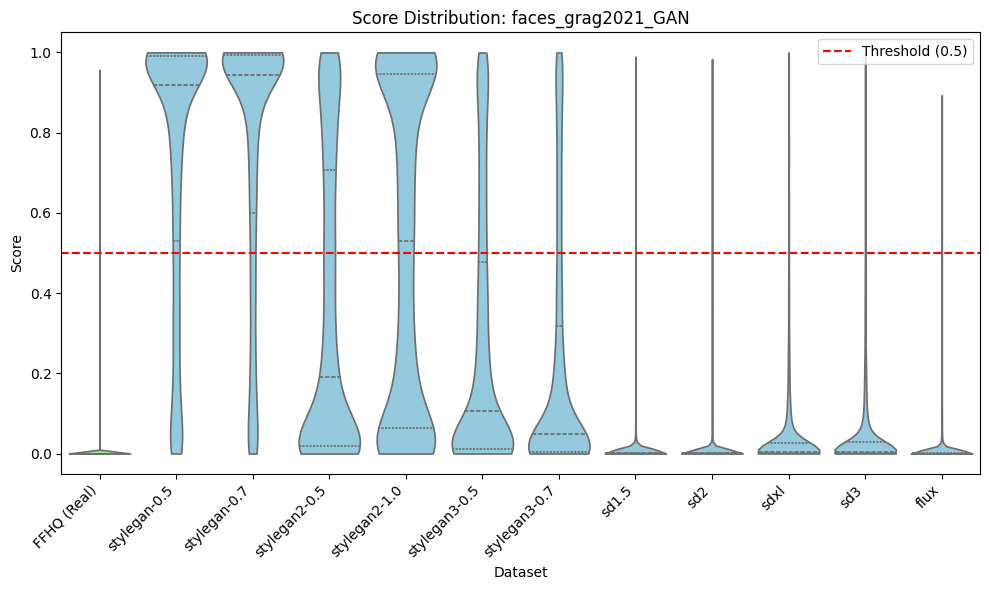

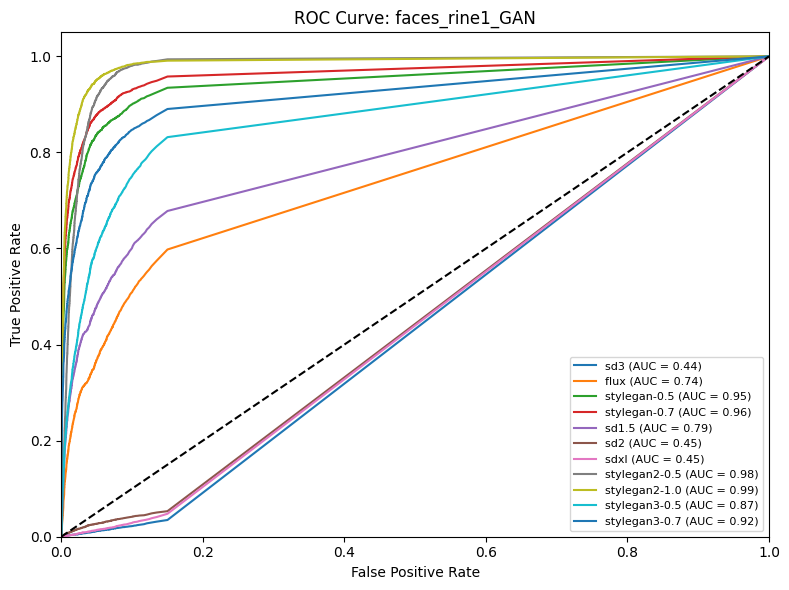

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


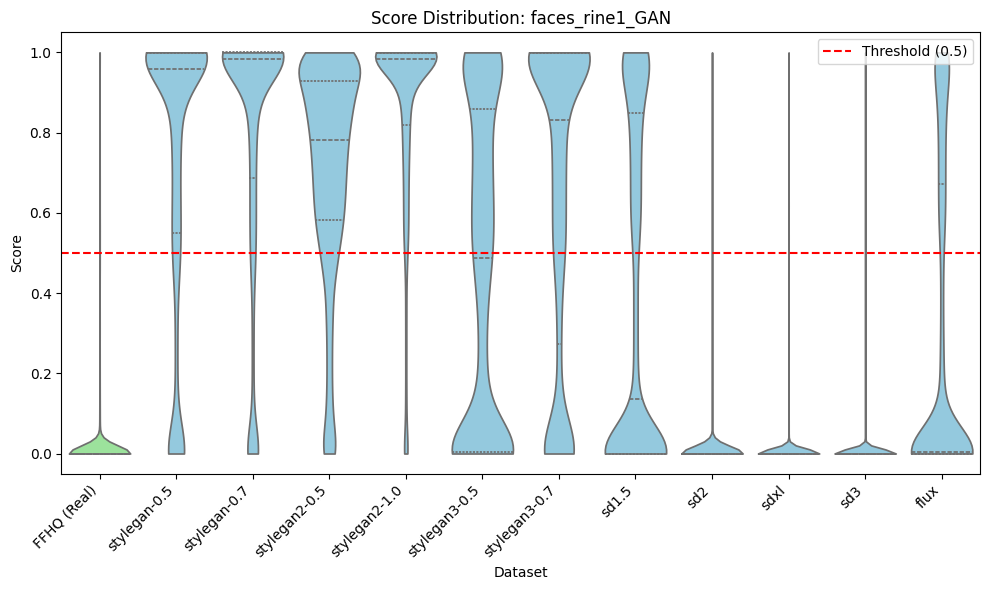

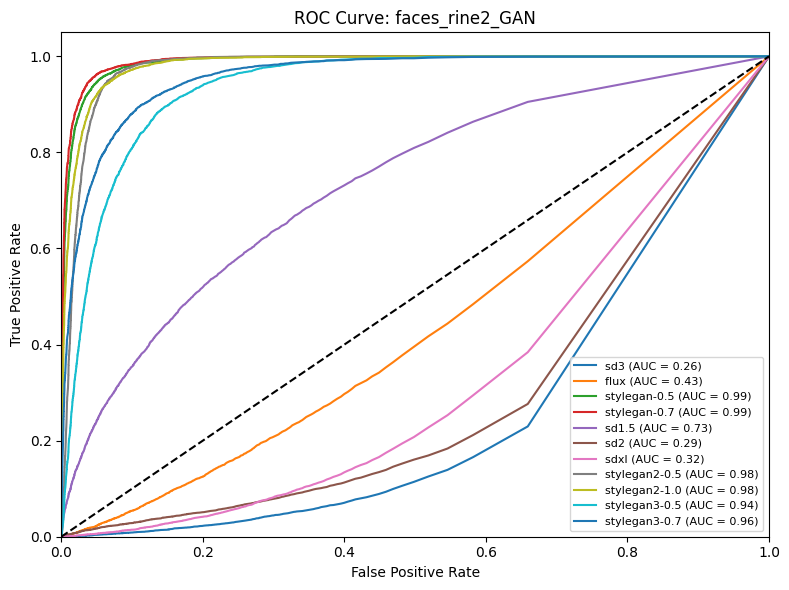

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


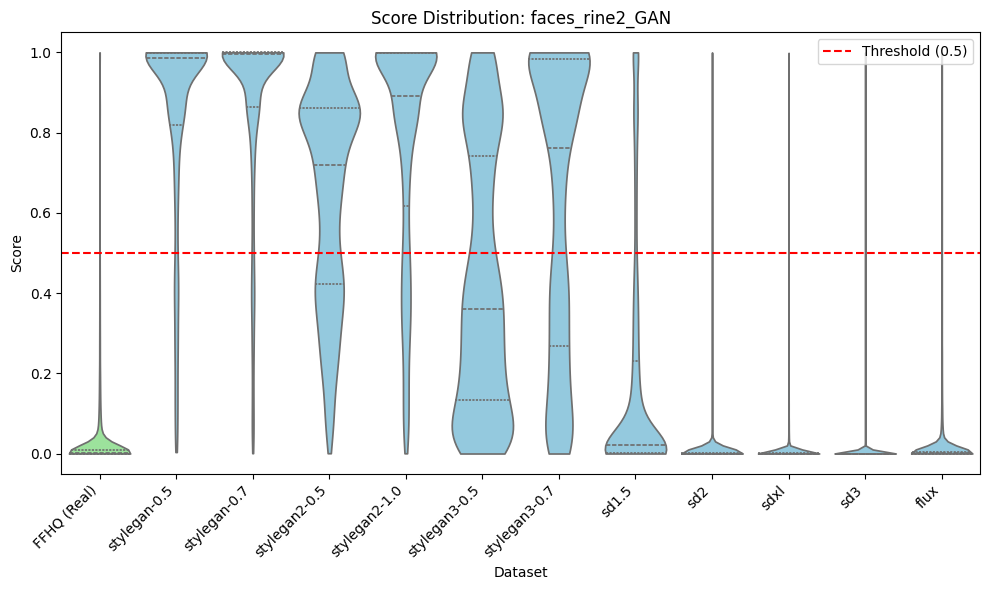

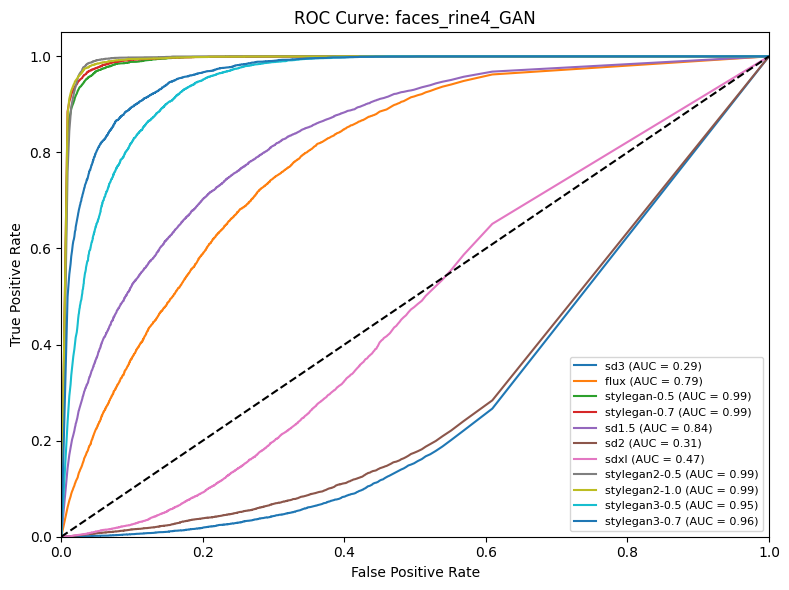

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


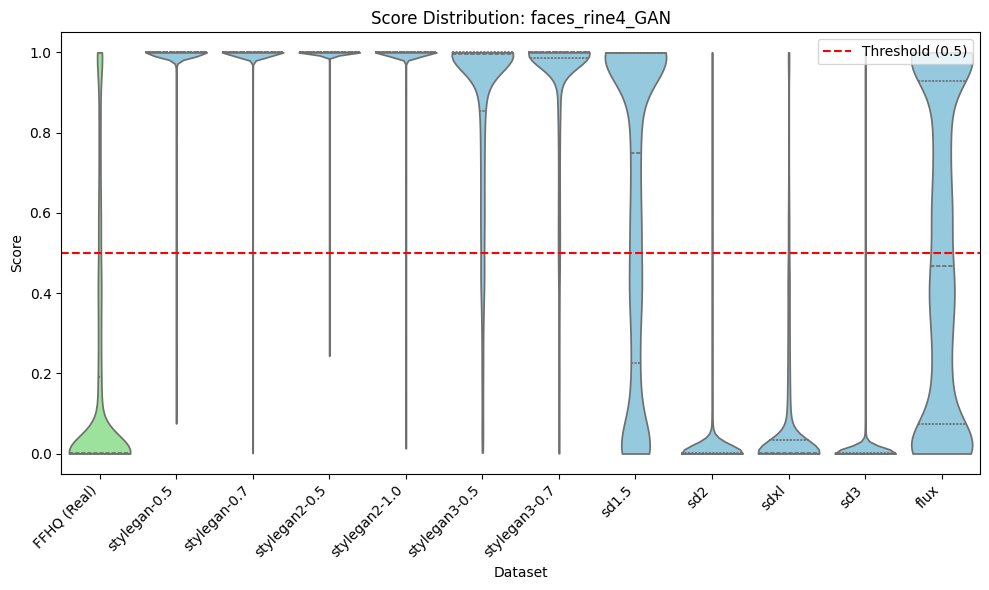

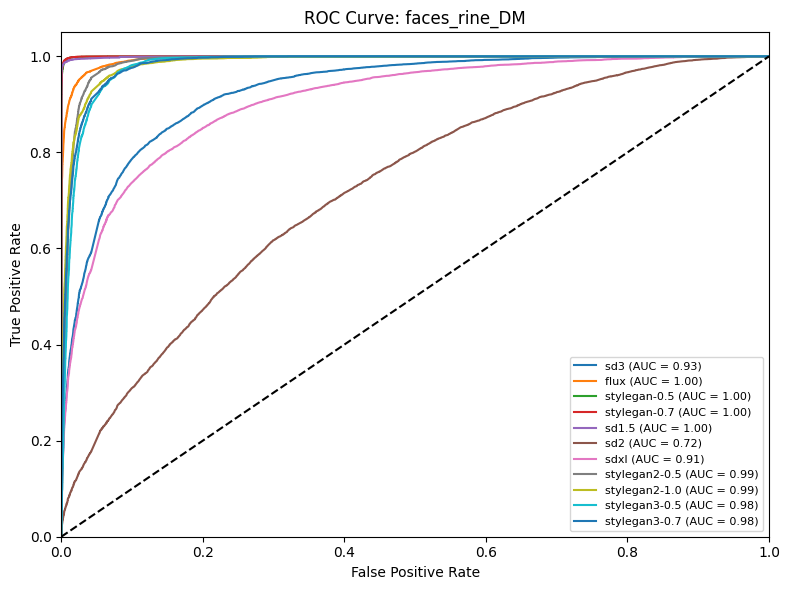

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


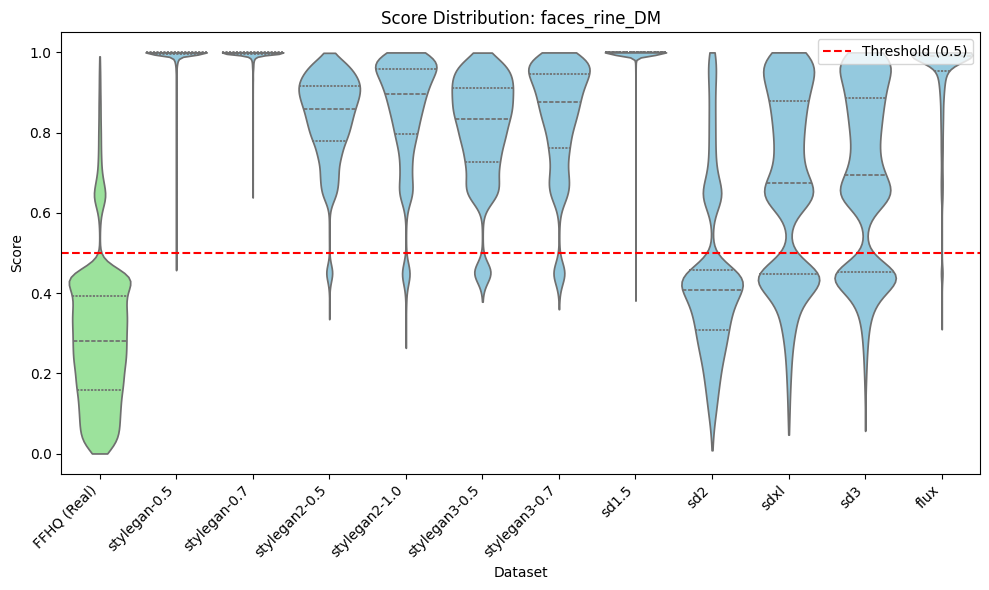

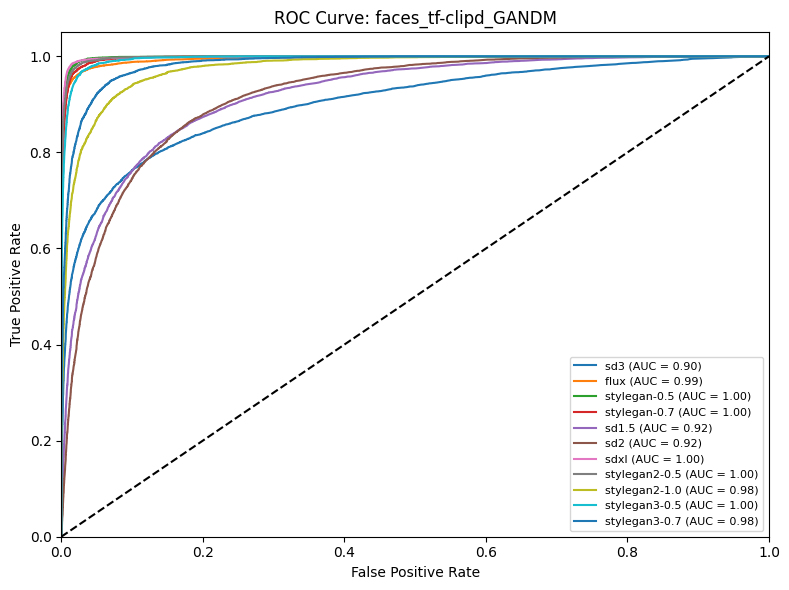

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


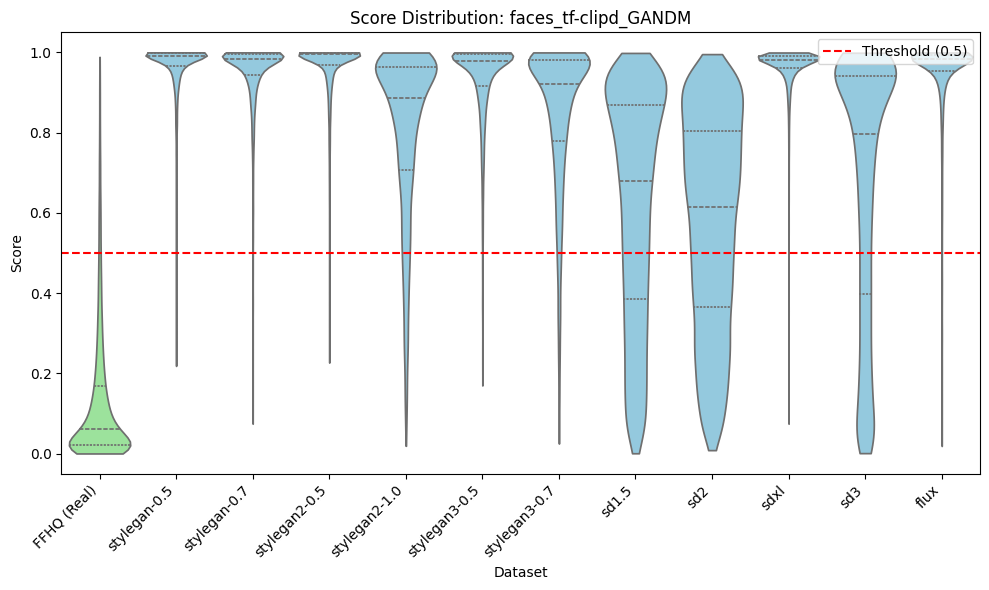

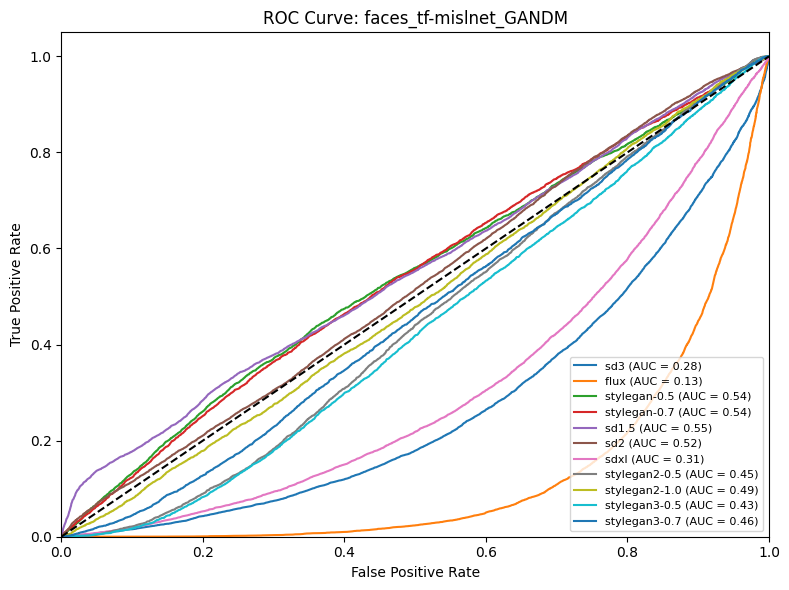

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


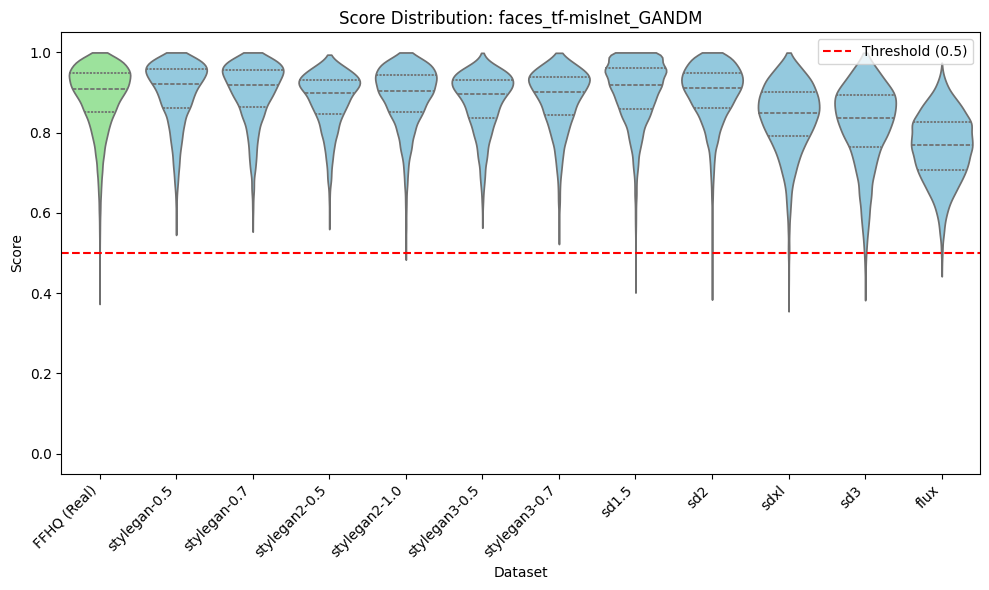

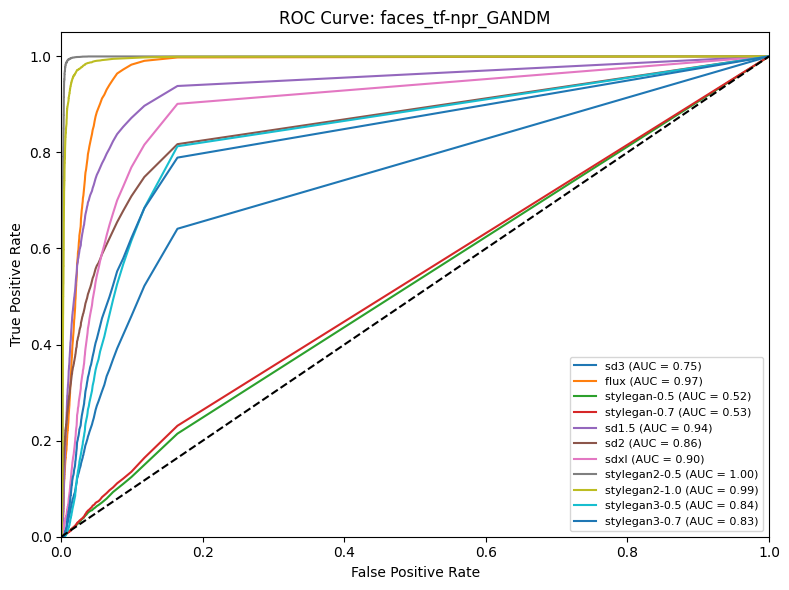

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


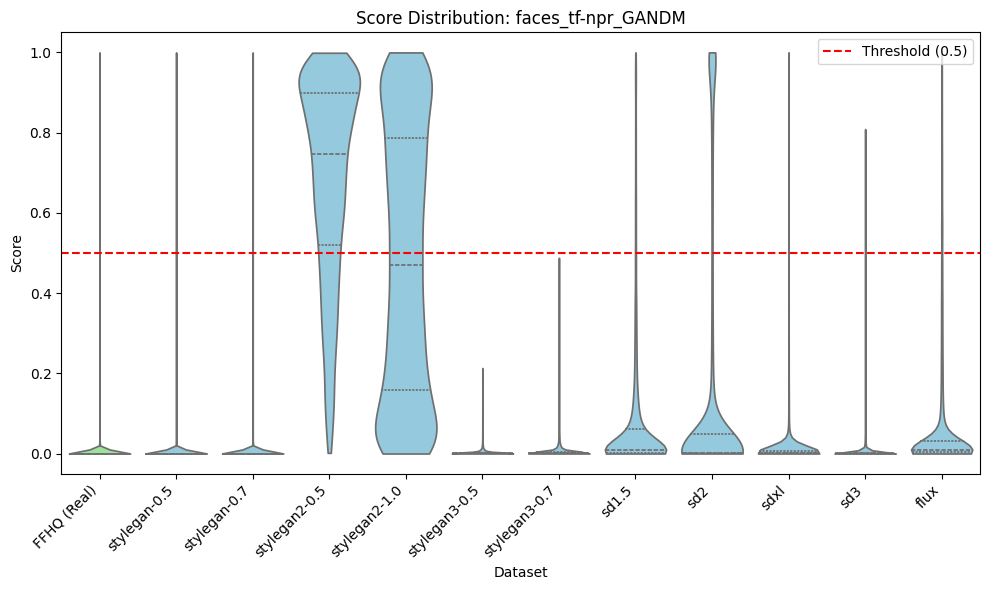

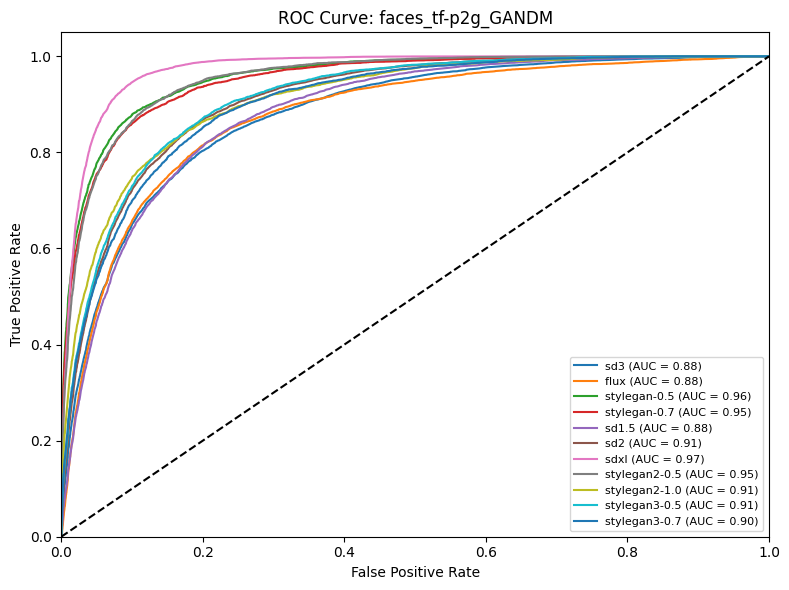

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


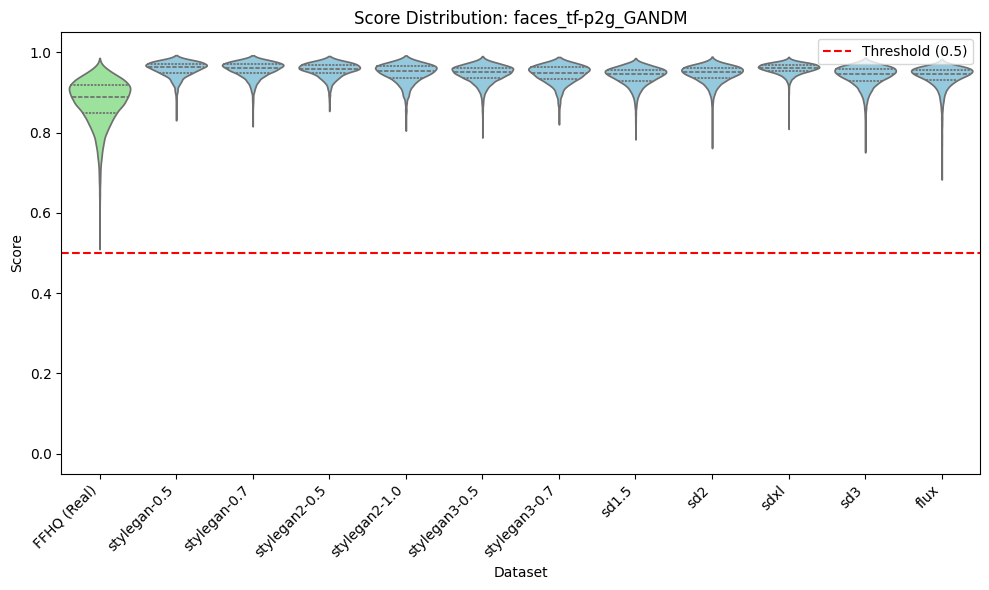

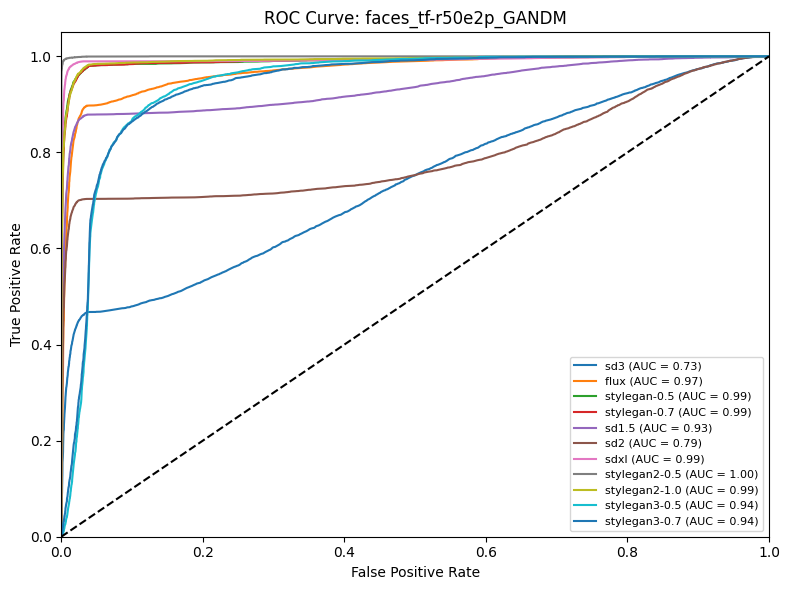

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


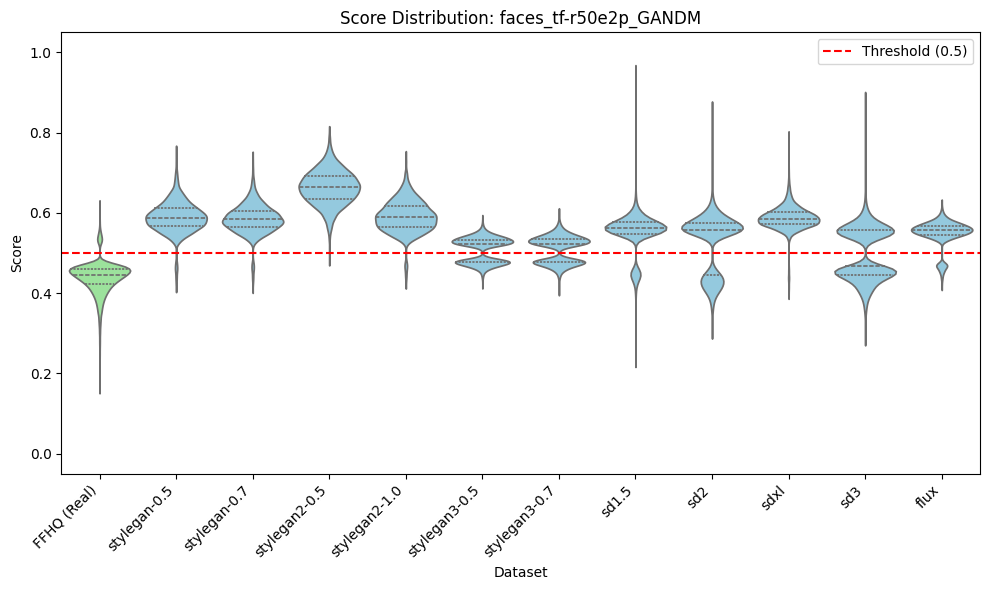

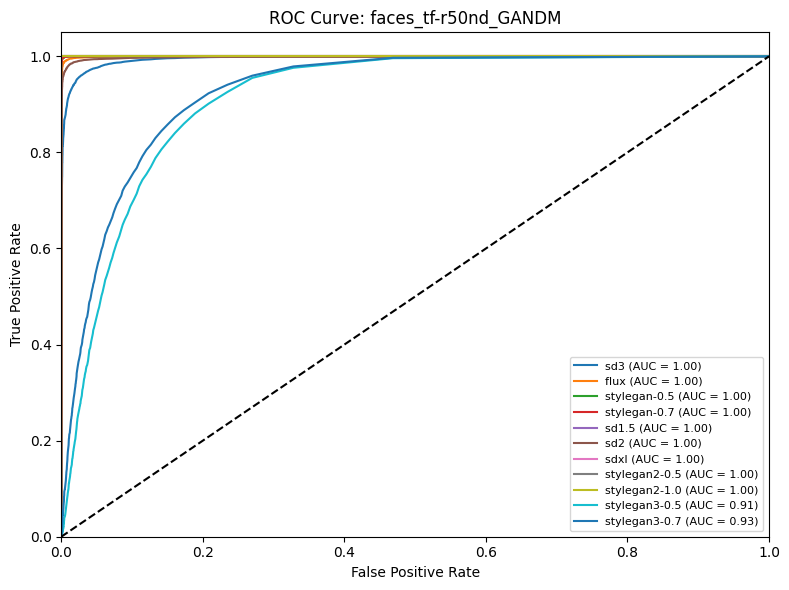

/tmp/ipykernel_435/960428432.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)


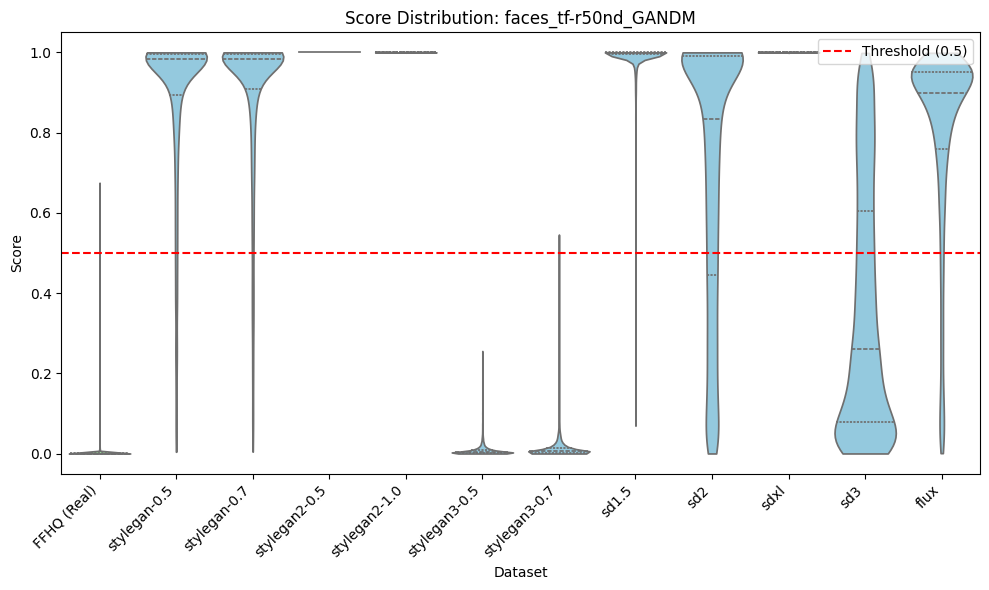


--- FNR Results for fake subsets ---

stylegan2-0.5:
  faces_aide_DM: 0.2347
  faces_aide_GAN: 0.0196
  faces_aide_genimage: 0.0196
  faces_cnndetection_GAN: 0.5225
  faces_co-spy_DM: 0.6052
  faces_co-spy_GAN: 0.0304
  faces_dmimagedetection_DM: 1.0000
  faces_dmimagedetection_GAN: 0.0000
  faces_freqnet_GAN: 0.9981
  faces_grag2021_GAN: 0.6629
  faces_rine1_GAN: 0.1739
  faces_rine2_GAN: 0.3294
  faces_rine4_GAN: 0.0015
  faces_rine_DM: 0.0231
  faces_tf-clipd_GANDM: 0.0069
  faces_tf-mislnet_GANDM: 0.0000
  faces_tf-npr_GANDM: 0.2355
  faces_tf-p2g_GANDM: 0.0000
  faces_tf-r50e2p_GANDM: 0.0008
  faces_tf-r50nd_GANDM: 0.0000

stylegan2-1.0:
  faces_aide_DM: 0.4204
  faces_aide_GAN: 0.0192
  faces_aide_genimage: 0.0192
  faces_cnndetection_GAN: 0.4781
  faces_co-spy_DM: 0.5985
  faces_co-spy_GAN: 0.0331
  faces_dmimagedetection_DM: 1.0000
  faces_dmimagedetection_GAN: 0.0000
  faces_freqnet_GAN: 0.9962
  faces_grag2021_GAN: 0.4858
  faces_rine1_GAN: 0.0823
  faces_rine2_GAN: 0.2031
 

In [ ]:
import seaborn as sns
from sklearn.metrics import roc_curve, auc
import os

if 'PLOTS_OUTPUT_DIR' not in globals():
    #MAIN_RESULTS_DIR = '/content/drive/MyDrive/Gupta Lab Group 4/Results/' your results directory UNCOMMENT THIS AND WRITE THE
    PLOTS_OUTPUT_DIR = os.path.join(MAIN_RESULTS_DIR, 'plots')
    os.makedirs(PLOTS_OUTPUT_DIR, exist_ok=True)

ROC_DIR = os.path.join(PLOTS_OUTPUT_DIR, 'roc_curves')
VIOLIN_DIR = os.path.join(PLOTS_OUTPUT_DIR, 'violin_plots')
os.makedirs(ROC_DIR, exist_ok=True)
os.makedirs(VIOLIN_DIR, exist_ok=True)

# Group data by model (detector)
detector_data = {} # display_name -> {group_key -> scores_array}

if 'raw_scores_by_key' in globals():
    for group_key, per_model_scores in raw_scores_by_key.items():
        for model_key, scores_series in per_model_scores.items():
            display_name = model_display_names[model_key]
            if display_name not in detector_data:
                detector_data[display_name] = {}
            detector_data[display_name][group_key] = scores_series.values

print(f"Generating ROC and Violin plots for {len(detector_data)} detectors...")

for detector, group_scores in detector_data.items():
    # Find the original model_key to retrieve matching FFHQ scores
    base_key = next((mk for mk, dn in model_display_names.items() if dn == detector), None)
    if not base_key:
        continue

    ffhq_lookup_key = base_key if 'faces_' in base_key else 'faces_' + base_key

    if 'ffhq_scores' not in globals() or ffhq_lookup_key not in ffhq_scores:
        print(f"Skipping plots for {detector} - no FFHQ (real) scores available.")
        continue

    real_scores = ffhq_scores[ffhq_lookup_key].values

    # ==========================================
    # 1. ROC Curves
    # ==========================================
    plt.figure(figsize=(8, 6))
    plotted_any = False

    for group_key, scores in group_scores.items():
        if group_key == ffhq_key:
            continue

        y_true = np.concatenate([np.zeros(len(real_scores)), np.ones(len(scores))])
        y_score = np.concatenate([real_scores, scores])

        try:
            fpr, tpr, _ = roc_curve(y_true, y_score)
            roc_auc = auc(fpr, tpr)
            dataset_name = group_key.split('/')[-1]
            plt.plot(fpr, tpr, label=f'{dataset_name} (AUC = {roc_auc:.2f})')
            plotted_any = True
        except Exception as e:
            pass

    if plotted_any:
        plt.plot([0, 1], [0, 1], color='black', linestyle='--')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'ROC Curve: {detector}')
        plt.legend(loc="lower right", fontsize=8)
        plt.tight_layout()
        plt.savefig(os.path.join(ROC_DIR, f'{detector}_roc.png'), dpi=150)
        plt.show()
    else:
        plt.close()

    # ==========================================
    # 2. Violin Plots
    # ==========================================
    plot_data = []

    # Add Real (FFHQ) data first
    plot_data.append(pd.DataFrame({'Score': real_scores, 'Dataset': 'FFHQ (Real)'}))

    # Add all Fake datasets
    for group_key, scores in group_scores.items():
        if group_key == ffhq_key:
            continue
        dataset_name = group_key.split('/')[-1]
        plot_data.append(pd.DataFrame({'Score': scores, 'Dataset': dataset_name}))

    if plot_data:
        df_plot = pd.concat(plot_data, ignore_index=True)
        plt.figure(figsize=(10, 6))

        # Create custom palette to color FFHQ differently
        unique_datasets = df_plot['Dataset'].unique()
        custom_palette = {ds: 'skyblue' for ds in unique_datasets}
        custom_palette['FFHQ (Real)'] = 'lightgreen'

        label_order = ["FFHQ (Real)", "stylegan-0.5", "stylegan-0.7", "stylegan2-0.5", "stylegan2-1.0", "stylegan3-0.5", "stylegan3-0.7", "sd1.5", "sd2", "sdxl", "sd3", "flux"]
        # Changed inner="quartile" to inner="box" to remove quartile lines but keep median marker
        sns.violinplot(x='Dataset', y='Score', order=label_order, data=df_plot, inner="quart", density_norm="width", cut=0, palette=custom_palette)
        plt.axhline(0.5, color='red', linestyle='--', label='Threshold (0.5)')
        plt.xticks(rotation=45, ha='right')
        plt.title(f'Score Distribution: {detector}')
        plt.ylim(-0.05, 1.05)
        plt.legend(loc='upper right')
        plt.tight_layout()
        plt.savefig(os.path.join(VIOLIN_DIR, f'{detector}_violin.png'), dpi=150)
        plt.show()

# --- FNR Calculation ---
print("\n--- FNR Results for fake subsets ---")
fnr_results = {}
if 'combined_dataframes' in globals():
    for group_name_key, combined_df_val in combined_dataframes.items():
        fnr_vals = compute_fnr(combined_df_val, group_name_key)
        if fnr_vals:
            fnr_results[group_name_key] = fnr_vals

    for group, vals in fnr_results.items():
        print(f"\n{group}:")
        for model, fnr in vals.items():
            print(f"  {model}: {fnr:.4f}")

# --- Calibrated Scores ---
print("\n--- Calibrated Scores ---")
if 'model_display_names' in globals() and 'ffhq_scores' in globals() and 'result_subfolders' in globals():
    CALIBRATED_OUT_DIR = os.path.join(MAIN_RESULTS_DIR, 'calibrated')
    os.makedirs(CALIBRATED_OUT_DIR, exist_ok=True)

    for drive_csv_dir in result_subfolders:
        folder_name = os.path.basename(drive_csv_dir)
        out_subfolder = os.path.join(CALIBRATED_OUT_DIR, folder_name)
        os.makedirs(out_subfolder, exist_ok=True)

        all_csvs = sorted(glob.glob(os.path.join(drive_csv_dir, '*.csv')))

        for path in all_csvs:
            # Skip files that are already calibrated
            if path.endswith('_calibrated.csv'):
                continue

            fname = os.path.basename(path)
            if 'patchforensics' in fname.lower():
                continue

            match = re.match(r'([^_]+)_.*', fname)
            group_name = match.group(1).lower() if match else 'ungrouped'

            # Skip generic stylegan groups as per user instructions in earlier cells
            if group_name in ['stylegan', 'stylegan2', 'stylegan3']:
                continue

            group_prefix = f"{group_name}_"
            model = extract_model_name(path, group_prefix)
            model_key = model.lower()

            ffhq_lookup_key = model_key if 'faces_' in model_key else 'faces_' + model_key
            if ffhq_lookup_key not in ffhq_scores:
                continue

            sorted_ffhq = np.sort(ffhq_scores[ffhq_lookup_key].values)

            try:
                df = pd.read_csv(path)
            except Exception as e:
                print(f"Error reading {fname}: {e}")
                continue

            if 'score' not in df.columns:
                continue

            scores = df['score'].values
            # The calibrated score is the count of FFHQ scores >= the given score
            indices = np.searchsorted(sorted_ffhq, scores, side='left')
            # calib_scores = len(sorted_ffhq) - indices

            # Calibrated score should be p-value to be statistically based
            calib_scores = (indices + 1 ) / (len(sorted_ffhq) + 1)

            df['calibrated_score'] = calib_scores

            new_fname = fname.replace('.csv', '_calibrated.csv')
            new_path = os.path.join(out_subfolder, new_fname)
            df.to_csv(new_path, index=False)

    print(f"Calculated and saved calibrated scores to {CALIBRATED_OUT_DIR} replicating the folder structure.")
else:
    print("Variables required for calibrated scores are missing.")

In [ ]:
# ============================================================
# Ensemble methods on CALIBRATED scores
# ============================================================
# Builds ensembles from the calibrated_score columns produced by the
# calibration cell above, then reports each ensemble's own AUROC (real FFHQ
# vs fake group) alongside precision/recall/F1 at a 0.5 hard-prediction
# threshold, and the individual models' best AUROC for reference.
#
# Methods included: simple_average, weighted_auroc, weighted_accuracy, majority_vote.
ENSEMBLE_METHODS = ['simple_average', 'weighted_auroc', 'weighted_accuracy', 'majority_vote']
VOTE_THRESHOLD = 0.5   # calibrated-score cutoff used for majority voting
HARD_THRESHOLD = 0.5   # cutoff applied to each ensemble's continuous score for P/R/F1

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

def extract_model_name_calibrated(path, group_prefix):
    """Same convention as extract_model_name, but also strips the trailing
    '_calibrated' suffix added by the calibration cell."""
    fname = os.path.basename(path)
    stem = fname[:-4] if fname.lower().endswith('.csv') else fname
    if stem.lower().startswith(group_prefix.lower()):
        stem = stem[len(group_prefix):]
    stem = re.sub(r'_calibrated$', '', stem, flags=re.IGNORECASE)
    return re.sub(r'_?predictions$', '', stem, flags=re.IGNORECASE)

def is_baseline_model(model_name):
    """Same convention as the AUROC cell: models with a 'tf-'/'tf_' token
    anywhere in the name (case-insensitive) are TrueFake baselines, and use
    a different filepath/shard set than the regular detectors -- they get
    excluded from any cross-model inner join."""
    return re.search(r'(^|_)tf[-_]', model_name.lower()) is not None

def load_calibrated_group_table(csv_paths, group_prefix):
    """Inner-joins every non-baseline model's calibrated_score column in a
    group onto a single filepath-indexed table (calib_<model> columns).
    'tf-' baseline files are skipped here -- they use a different
    filepath/shard convention and would zero out the intersection."""
    frames, seen = [], {}
    for path in csv_paths:
        fname = os.path.basename(path)
        try:
            df = pd.read_csv(path)
        except Exception as e:
            print(f"ERROR reading {fname}: {e}")
            continue
        if 'filepath' not in df.columns or 'calibrated_score' not in df.columns:
            continue
        model = extract_model_name_calibrated(path, group_prefix)
        model_key = model.lower()
        if is_baseline_model(model_key):
            continue  # <-- skip tf- baselines, different filepath set
        if model_key in seen:
            continue
        seen[model_key] = fname
        d = df.set_index('filepath').sort_index()
        sub = pd.DataFrame(index=d.index)
        sub[f'calib_{model_key}'] = d['calibrated_score']
        frames.append(sub)
    if not frames:
        return None
    return pd.concat(frames, axis=1, join='inner').sort_index()

# --- Rebuild calibrated tables for every folder/group from disk ---
calibrated_tables = {}   # {folder/group: DataFrame of calib_<model> columns}

for drive_csv_dir in result_subfolders:
    folder_name = os.path.basename(drive_csv_dir)
    calib_folder = os.path.join(CALIBRATED_OUT_DIR, folder_name)
    if not os.path.isdir(calib_folder):
        continue
    all_calib_csvs = sorted(glob.glob(os.path.join(calib_folder, '*_calibrated.csv')))

    grouped = {}
    for path in all_calib_csvs:
        fname = os.path.basename(path)
        match = re.match(r'([^_]+)_.*', fname)
        group_name = match.group(1).lower() if match else 'ungrouped'
        grouped.setdefault(group_name, []).append(path)

    for group_name_key, csv_list in grouped.items():
        table = load_calibrated_group_table(csv_list, f'{group_name_key}_')
        if table is not None and not table.empty:
            calibrated_tables[f'{folder_name}/{group_name_key}'] = table

print(f"Loaded calibrated tables for {len(calibrated_tables)} folder/group combos:")
for k, v in calibrated_tables.items():
    print(f"  {k}: {v.shape[0]} images x {v.shape[1]} models")

# --- Identify the FFHQ (real) calibrated table ---
calib_ffhq_keys = [k for k in calibrated_tables if 'ffhq' in k.lower()]
if len(calib_ffhq_keys) != 1:
    raise ValueError(f"Expected exactly one FFHQ calibrated table, found: {calib_ffhq_keys}")
calib_ffhq_key = calib_ffhq_keys[0]
calib_ffhq_table = calibrated_tables[calib_ffhq_key]

def match_ffhq_col(model_col):
    """Same 'prepend faces_' fallback used in the AUROC cell -- FFHQ's own
    calibrated columns may be named 'calib_faces_<model>'."""
    if model_col in calib_ffhq_table.columns:
        return model_col
    alt = model_col.replace('calib_', 'calib_faces_', 1)
    if alt in calib_ffhq_table.columns:
        return alt
    return None

def get_accuracy_weights(group_key):
    """Pulls each model's thresholded accuracy on its own fake group (fraction
    of images scored >= 0.5 as 'fake' -- same value plotted in
    plot_accuracy_bar). Prefers all_combined_dataframes (per-folder, if you
    added the one-line fix to the main loop); falls back to whatever
    combined_dataframes currently holds (only the last folder processed)
    otherwise. Returns {model_name_lower: accuracy}."""
    folder_group = group_key.split('/')
    if len(folder_group) != 2:
        return {}
    folder_name, group_name_key = folder_group

    if 'all_combined_dataframes' in globals() and folder_name in all_combined_dataframes:
        combined_df = all_combined_dataframes[folder_name].get(group_name_key)
    else:
        combined_df = globals().get('combined_dataframes', {}).get(group_name_key)

    if combined_df is None:
        return {}
    delta_cols = [c for c in combined_df.columns if c.startswith('delta_vector_')]
    return {c.replace('delta_vector_', '').lower(): combined_df[c].mean() for c in delta_cols}

def compute_metrics(y_true, y_score, threshold=HARD_THRESHOLD):
    """AUROC (continuous) plus precision/recall/F1 (hard predictions at
    `threshold`). zero_division=0 avoids crashes/warnings when a group has
    no predicted positives or no predicted negatives."""
    auroc = roc_auc_score(y_true, y_score)
    y_pred = (y_score >= threshold).astype(int)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return auroc, precision, recall, f1

# --- Build ensembles per fake group ---
ensemble_results = {}   # {group_key: {method_metric: value}}

for key, fake_table in calibrated_tables.items():
    if key == calib_ffhq_key:
        continue

    usable_cols, ffhq_cols = [], []
    for c in fake_table.columns:
        ffhq_c = match_ffhq_col(c)
        if ffhq_c is not None:
            usable_cols.append(c)
            ffhq_cols.append(ffhq_c)

    if len(usable_cols) < 2:
        print(f"[{key}] fewer than 2 models with matching FFHQ calibrated scores -- skipping.")
        continue

    fake_scores = fake_table[usable_cols]
    real_scores = calib_ffhq_table[ffhq_cols].copy()
    real_scores.columns = usable_cols  # align names for the math below

    method_results = {}

    # --- Simple Averaging ---
    if 'simple_average' in ENSEMBLE_METHODS:
        fake_ens = fake_scores.mean(axis=1)
        real_ens = real_scores.mean(axis=1)
        y_true = np.concatenate([np.zeros(len(real_ens)), np.ones(len(fake_ens))])
        y_score = np.concatenate([real_ens.values, fake_ens.values])
        auroc, prec, rec, f1 = compute_metrics(y_true, y_score)
        method_results['simple_average_auroc'] = auroc
        method_results['simple_average_precision'] = prec
        method_results['simple_average_recall'] = rec
        method_results['simple_average_f1'] = f1

    # --- AUROC-Weighted (weights from raw-score AUROC computed earlier) ---
    if 'weighted_auroc' in ENSEMBLE_METHODS:
        per_model_auroc = auroc_results.get(key, {})
        weights = {}
        for c in usable_cols:
            model_name = c.replace('calib_', '')
            w = next((a for m, a in per_model_auroc.items() if m.lower() == model_name), None)
            weights[c] = w if w is not None else 0.5
        w = pd.Series(weights)
        w = w / w.sum()
        fake_ens = (fake_scores * w).sum(axis=1)
        real_ens = (real_scores * w).sum(axis=1)
        y_true = np.concatenate([np.zeros(len(real_ens)), np.ones(len(fake_ens))])
        y_score = np.concatenate([real_ens.values, fake_ens.values])
        auroc, prec, rec, f1 = compute_metrics(y_true, y_score)
        method_results['weighted_auroc_auroc'] = auroc
        method_results['weighted_auroc_precision'] = prec
        method_results['weighted_auroc_recall'] = rec
        method_results['weighted_auroc_f1'] = f1

    # --- Accuracy-Weighted (weights from thresholded accuracy, not AUROC) ---
    if 'weighted_accuracy' in ENSEMBLE_METHODS:
        acc_weights_raw = get_accuracy_weights(key)
        weights = {}
        for c in usable_cols:
            model_name = c.replace('calib_', '')
            w = acc_weights_raw.get(model_name, None)
            weights[c] = w if w is not None else 0.5
        w = pd.Series(weights)
        if w.sum() == 0:
            print(f"[{key}] all accuracy weights are 0 -- skipping weighted_accuracy.")
        else:
            w = w / w.sum()
            fake_ens = (fake_scores * w).sum(axis=1)
            real_ens = (real_scores * w).sum(axis=1)
            y_true = np.concatenate([np.zeros(len(real_ens)), np.ones(len(fake_ens))])
            y_score = np.concatenate([real_ens.values, fake_ens.values])
            auroc, prec, rec, f1 = compute_metrics(y_true, y_score)
            method_results['weighted_accuracy_auroc'] = auroc
            method_results['weighted_accuracy_precision'] = prec
            method_results['weighted_accuracy_recall'] = rec
            method_results['weighted_accuracy_f1'] = f1

    # --- Majority Voting ---
    if 'majority_vote' in ENSEMBLE_METHODS:
        fake_votes = (fake_scores >= VOTE_THRESHOLD).mean(axis=1)  # fraction voting "fake"
        real_votes = (real_scores >= VOTE_THRESHOLD).mean(axis=1)
        y_true = np.concatenate([np.zeros(len(real_votes)), np.ones(len(fake_votes))])
        y_score = np.concatenate([real_votes.values, fake_votes.values])
        # majority_vote's hard threshold is "over half the models voted fake",
        # i.e. y_score > 0.5 -- kept distinct from HARD_THRESHOLD since this
        # score is already a vote fraction, not a calibrated score.
        auroc, prec, rec, f1 = compute_metrics(y_true, y_score, threshold=0.5)
        method_results['majority_vote_auroc'] = auroc
        method_results['majority_vote_precision'] = prec
        method_results['majority_vote_recall'] = rec
        method_results['majority_vote_f1'] = f1
        method_results['majority_vote_accuracy'] = ((fake_votes > 0.5).astype(int) == 1).mean()

    ensemble_results[key] = method_results
    print(f"[{key}] ({len(usable_cols)} models) -> " +
          ", ".join(f"{m}: {v:.4f}" for m, v in method_results.items()))

# --- Summary: ensembles vs. best individual model, per group ---
summary_rows = []
for key, methods in ensemble_results.items():
    row = dict(methods)
    group_aurocs = auroc_results.get(key, {})
    row['best_individual_auroc'] = max(group_aurocs.values()) if group_aurocs else np.nan
    row['group'] = key
    summary_rows.append(row)

ensemble_summary_df = pd.DataFrame(summary_rows).set_index('group').sort_index()

# Reorder columns so each method's auroc/precision/recall/f1 stay grouped together
preferred_order = []
for method in ENSEMBLE_METHODS:
    for metric in ['auroc', 'precision', 'recall', 'f1']:
        col = f'{method}_{metric}'
        if col in ensemble_summary_df.columns:
            preferred_order.append(col)
    if method == 'majority_vote' and 'majority_vote_accuracy' in ensemble_summary_df.columns:
        preferred_order.append('majority_vote_accuracy')
preferred_order.append('best_individual_auroc')
ensemble_summary_df = ensemble_summary_df[[c for c in preferred_order if c in ensemble_summary_df.columns]]

display(ensemble_summary_df.style.format('{:.4f}', na_rep='-'))

ensemble_summary_df.round(4).to_csv(os.path.join(PLOTS_OUTPUT_DIR, 'ensemble_metrics_summary.csv'))
print(f"\nSaved ensemble metrics summary to {os.path.join(PLOTS_OUTPUT_DIR, 'ensemble_metrics_summary.csv')}")

Loaded calibrated tables for 12 folder/group combos:
  sd3_results/sd3: 10000 images x 14 models
  ffhq_results/ffhq: 20000 images x 14 models
  flux_results/flux: 10000 images x 14 models
  stylegan1_results/stylegan-0.5: 5000 images x 14 models
  stylegan1_results/stylegan-0.7: 5000 images x 14 models
  sd1.5_results/sd1.5: 10000 images x 14 models
  sd2_results/sd2: 10000 images x 14 models
  sdxl_results/sdxl: 10000 images x 14 models
  stylegan23_results/stylegan2-0.5: 4999 images x 14 models
  stylegan23_results/stylegan2-1.0: 5000 images x 14 models
  stylegan23_results/stylegan3-0.5: 5000 images x 14 models
  stylegan23_results/stylegan3-0.7: 5000 images x 14 models
[sd3_results/sd3] (14 models) -> simple_average_auroc: 0.9757, simple_average_precision: 0.7347, simple_average_recall: 0.9956, simple_average_f1: 0.8455, weighted_auroc_auroc: 0.9958, weighted_auroc_precision: 0.7691, weighted_auroc_recall: 0.9998, weighted_auroc_f1: 0.8694, weighted_accuracy_auroc: 0.9757, weighte

,simple_average_auroc,simple_average_precision,simple_average_recall,simple_average_f1,weighted_auroc_auroc,weighted_auroc_precision,weighted_auroc_recall,weighted_auroc_f1,weighted_accuracy_auroc,weighted_accuracy_precision,weighted_accuracy_recall,weighted_accuracy_f1,majority_vote_auroc,majority_vote_precision,majority_vote_recall,majority_vote_f1,majority_vote_accuracy,best_individual_auroc
group,,,,,,,,,,,,,,,,,,
flux_results/flux,0.9587,0.7247,0.9463,0.8208,0.9781,0.7198,0.9965,0.8358,0.9587,0.7247,0.9463,0.8208,0.9394,0.5960,0.9838,0.7423,0.9435,1.0000
sd1.5_results/sd1.5,0.9782,0.7339,0.9915,0.8435,0.9882,0.6893,0.9999,0.8160,0.9782,0.7339,0.9915,0.8435,0.9669,0.5997,0.9989,0.7494,0.9909,1.0000
sd2_results/sd2,0.7572,0.5256,0.3983,0.4532,0.8930,0.6837,0.8168,0.7444,0.7572,0.5256,0.3983,0.4532,0.7315,0.5035,0.6762,0.5772,0.4463,1.0000
sd3_results/sd3,0.9757,0.7347,0.9956,0.8455,0.9958,0.7691,0.9998,0.8694,0.9757,0.7347,0.9956,0.8455,0.9574,0.5997,0.9990,0.7495,0.9935,1.0000
sdxl_results/sdxl,0.9202,0.7064,0.8648,0.7776,0.9699,0.7302,0.9737,0.8346,0.9202,0.7064,0.8648,0.7776,0.8846,0.5840,0.9362,0.7193,0.8394,1.0000
stylegan1_results/stylegan-0.5,0.9971,0.5817,1.0000,0.7356,0.9990,0.5692,1.0000,0.7254,0.9971,0.5817,1.0000,0.7356,0.9881,0.4285,1.0000,0.6000,0.9994,1.0000
stylegan1_results/stylegan-0.7,0.9971,0.5817,1.0000,0.7356,0.9991,0.5677,1.0000,0.7242,0.9971,0.5817,1.0000,0.7356,0.9874,0.4285,1.0000,0.6000,0.9998,1.0000
stylegan23_results/stylegan2-0.5,0.9962,0.5816,0.9996,0.7353,0.9992,0.5595,1.0000,0.7175,0.9994,0.4634,1.0000,0.6333,0.9840,0.4284,0.9998,0.5998,0.9992,1.0000
stylegan23_results/stylegan2-1.0,0.9961,0.5817,0.9998,0.7355,0.9990,0.5630,0.9998,0.7203,0.9994,0.4816,1.0000,0.6502,0.9804,0.4285,0.9998,0.5999,0.9990,1.0000



Saved ensemble metrics summary to /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/plots/ensemble_metrics_summary.csv


In [ ]:
# ============================================================
# Ensemble methods on CALIBRATED scores
# ============================================================
# Builds ensembles from the calibrated_score columns produced by the
# calibration cell above, then reports each ensemble's own AUROC (real FFHQ
# vs fake group) alongside precision/recall/F1 at a 0.5 hard-prediction
# threshold, and the best individual model's AUROC + precision/recall/F1
# (computed on that model's own RAW scores, threshold >= 0.5, matching the
# delta_vector convention used elsewhere in the notebook) for reference.
#
# Methods included: simple_average, weighted_auroc, weighted_accuracy, majority_vote.
ENSEMBLE_METHODS = ['simple_average', 'weighted_auroc', 'weighted_accuracy', 'majority_vote']
VOTE_THRESHOLD = 0.5     # calibrated-score cutoff used for majority voting
HARD_THRESHOLD = 0.5     # cutoff applied to each ensemble's continuous score for P/R/F1
RAW_THRESHOLD = 0.5      # cutoff applied to raw scores for best_individual's P/R/F1

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

def extract_model_name_calibrated(path, group_prefix):
    """Same convention as extract_model_name, but also strips the trailing
    '_calibrated' suffix added by the calibration cell."""
    fname = os.path.basename(path)
    stem = fname[:-4] if fname.lower().endswith('.csv') else fname
    if stem.lower().startswith(group_prefix.lower()):
        stem = stem[len(group_prefix):]
    stem = re.sub(r'_calibrated$', '', stem, flags=re.IGNORECASE)
    return re.sub(r'_?predictions$', '', stem, flags=re.IGNORECASE)

def is_baseline_model(model_name):
    """Same convention as the AUROC cell: models with a 'tf-'/'tf_' token
    anywhere in the name (case-insensitive) are TrueFake baselines, and use
    a different filepath/shard set than the regular detectors -- they get
    excluded from any cross-model inner join."""
    return re.search(r'(^|_)tf[-_]', model_name.lower()) is not None

def load_calibrated_group_table(csv_paths, group_prefix):
    """Inner-joins every non-baseline model's calibrated_score column in a
    group onto a single filepath-indexed table (calib_<model> columns).
    'tf-' baseline files are skipped here -- they use a different
    filepath/shard convention and would zero out the intersection."""
    frames, seen = [], {}
    for path in csv_paths:
        fname = os.path.basename(path)
        try:
            df = pd.read_csv(path)
        except Exception as e:
            print(f"ERROR reading {fname}: {e}")
            continue
        if 'filepath' not in df.columns or 'calibrated_score' not in df.columns:
            continue
        model = extract_model_name_calibrated(path, group_prefix)
        model_key = model.lower()
        if is_baseline_model(model_key):
            continue  # <-- skip tf- baselines, different filepath set
        if model_key in seen:
            continue
        seen[model_key] = fname
        d = df.set_index('filepath').sort_index()
        sub = pd.DataFrame(index=d.index)
        sub[f'calib_{model_key}'] = d['calibrated_score']
        frames.append(sub)
    if not frames:
        return None
    return pd.concat(frames, axis=1, join='inner').sort_index()

# --- Rebuild calibrated tables for every folder/group from disk ---
calibrated_tables = {}   # {folder/group: DataFrame of calib_<model> columns}

for drive_csv_dir in result_subfolders:
    folder_name = os.path.basename(drive_csv_dir)
    calib_folder = os.path.join(CALIBRATED_OUT_DIR, folder_name)
    if not os.path.isdir(calib_folder):
        continue
    all_calib_csvs = sorted(glob.glob(os.path.join(calib_folder, '*_calibrated.csv')))

    grouped = {}
    for path in all_calib_csvs:
        fname = os.path.basename(path)
        match = re.match(r'([^_]+)_.*', fname)
        group_name = match.group(1).lower() if match else 'ungrouped'
        grouped.setdefault(group_name, []).append(path)

    for group_name_key, csv_list in grouped.items():
        table = load_calibrated_group_table(csv_list, f'{group_name_key}_')
        if table is not None and not table.empty:
            calibrated_tables[f'{folder_name}/{group_name_key}'] = table

print(f"Loaded calibrated tables for {len(calibrated_tables)} folder/group combos:")
for k, v in calibrated_tables.items():
    print(f"  {k}: {v.shape[0]} images x {v.shape[1]} models")

# --- Identify the FFHQ (real) calibrated table ---
calib_ffhq_keys = [k for k in calibrated_tables if 'ffhq' in k.lower()]
if len(calib_ffhq_keys) != 1:
    raise ValueError(f"Expected exactly one FFHQ calibrated table, found: {calib_ffhq_keys}")
calib_ffhq_key = calib_ffhq_keys[0]
calib_ffhq_table = calibrated_tables[calib_ffhq_key]

def match_ffhq_col(model_col):
    """Same 'prepend faces_' fallback used in the AUROC cell -- FFHQ's own
    calibrated columns may be named 'calib_faces_<model>'."""
    if model_col in calib_ffhq_table.columns:
        return model_col
    alt = model_col.replace('calib_', 'calib_faces_', 1)
    if alt in calib_ffhq_table.columns:
        return alt
    return None

def get_accuracy_weights(group_key):
    """Pulls each model's thresholded accuracy on its own fake group (fraction
    of images scored >= 0.5 as 'fake' -- same value plotted in
    plot_accuracy_bar). Prefers all_combined_dataframes (per-folder, if you
    added the one-line fix to the main loop); falls back to whatever
    combined_dataframes currently holds (only the last folder processed)
    otherwise. Returns {model_name_lower: accuracy}."""
    folder_group = group_key.split('/')
    if len(folder_group) != 2:
        return {}
    folder_name, group_name_key = folder_group

    if 'all_combined_dataframes' in globals() and folder_name in all_combined_dataframes:
        combined_df = all_combined_dataframes[folder_name].get(group_name_key)
    else:
        combined_df = globals().get('combined_dataframes', {}).get(group_name_key)

    if combined_df is None:
        return {}
    delta_cols = [c for c in combined_df.columns if c.startswith('delta_vector_')]
    return {c.replace('delta_vector_', '').lower(): combined_df[c].mean() for c in delta_cols}

def compute_metrics(y_true, y_score, threshold):
    """AUROC (continuous) plus precision/recall/F1 (hard predictions at
    `threshold`). zero_division=0 avoids crashes/warnings when a group has
    no predicted positives or no predicted negatives."""
    auroc = roc_auc_score(y_true, y_score)
    y_pred = (y_score >= threshold).astype(int)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return auroc, precision, recall, f1

def get_best_individual_metrics(group_key, threshold=RAW_THRESHOLD):
    """Finds the model with the highest raw-score AUROC for this group (from
    auroc_results, computed earlier in the notebook on each model's own full
    image set) and computes precision/recall/F1 for that SAME model on its
    own raw scores at `threshold`. Returns None if unavailable (e.g. group
    missing from auroc_results, or no matching FFHQ raw scores)."""
    per_model_auroc = auroc_results.get(group_key, {})
    if not per_model_auroc:
        return None
    best_display_name = max(per_model_auroc, key=per_model_auroc.get)
    best_auroc = per_model_auroc[best_display_name]

    # Recover the raw score series for this model + its FFHQ counterpart,
    # same lookup convention used when auroc_results was first built.
    model_key = best_display_name.lower()
    per_model_scores = raw_scores_by_key.get(group_key, {})
    fake_series = per_model_scores.get(model_key)
    if fake_series is None:
        return {'auroc': best_auroc, 'precision': np.nan, 'recall': np.nan,
                'f1': np.nan, 'model': best_display_name}

    ffhq_lookup_key = model_key if 'faces_' in model_key else 'faces_' + model_key
    if ffhq_lookup_key not in ffhq_scores:
        return {'auroc': best_auroc, 'precision': np.nan, 'recall': np.nan,
                'f1': np.nan, 'model': best_display_name}

    real_scores = ffhq_scores[ffhq_lookup_key].values
    fake_vals = fake_series.values
    y_true = np.concatenate([np.zeros(len(real_scores)), np.ones(len(fake_vals))])
    y_score = np.concatenate([real_scores, fake_vals])
    y_pred = (y_score >= threshold).astype(int)

    return {
        'auroc': best_auroc,
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'model': best_display_name,
    }

# --- Build ensembles per fake group ---
ensemble_results = {}   # {group_key: {method_metric: value}}

for key, fake_table in calibrated_tables.items():
    if key == calib_ffhq_key:
        continue

    usable_cols, ffhq_cols = [], []
    for c in fake_table.columns:
        ffhq_c = match_ffhq_col(c)
        if ffhq_c is not None:
            usable_cols.append(c)
            ffhq_cols.append(ffhq_c)

    if len(usable_cols) < 2:
        print(f"[{key}] fewer than 2 models with matching FFHQ calibrated scores -- skipping.")
        continue

    fake_scores = fake_table[usable_cols]
    real_scores = calib_ffhq_table[ffhq_cols].copy()
    real_scores.columns = usable_cols  # align names for the math below

    method_results = {}

    # --- Simple Averaging ---
    if 'simple_average' in ENSEMBLE_METHODS:
        fake_ens = fake_scores.mean(axis=1)
        real_ens = real_scores.mean(axis=1)
        y_true = np.concatenate([np.zeros(len(real_ens)), np.ones(len(fake_ens))])
        y_score = np.concatenate([real_ens.values, fake_ens.values])
        auroc, prec, rec, f1 = compute_metrics(y_true, y_score, HARD_THRESHOLD)
        method_results['simple_average_auroc'] = auroc
        method_results['simple_average_precision'] = prec
        method_results['simple_average_recall'] = rec
        method_results['simple_average_f1'] = f1

    # --- AUROC-Weighted (weights from raw-score AUROC computed earlier) ---
    if 'weighted_auroc' in ENSEMBLE_METHODS:
        per_model_auroc = auroc_results.get(key, {})
        weights = {}
        for c in usable_cols:
            model_name = c.replace('calib_', '')
            w = next((a for m, a in per_model_auroc.items() if m.lower() == model_name), None)
            weights[c] = w if w is not None else 0.5
        w = pd.Series(weights)
        w = w / w.sum()
        fake_ens = (fake_scores * w).sum(axis=1)
        real_ens = (real_scores * w).sum(axis=1)
        y_true = np.concatenate([np.zeros(len(real_ens)), np.ones(len(fake_ens))])
        y_score = np.concatenate([real_ens.values, fake_ens.values])
        auroc, prec, rec, f1 = compute_metrics(y_true, y_score, HARD_THRESHOLD)
        method_results['weighted_auroc_auroc'] = auroc
        method_results['weighted_auroc_precision'] = prec
        method_results['weighted_auroc_recall'] = rec
        method_results['weighted_auroc_f1'] = f1

    # --- Accuracy-Weighted (weights from thresholded accuracy, not AUROC) ---
    if 'weighted_accuracy' in ENSEMBLE_METHODS:
        acc_weights_raw = get_accuracy_weights(key)
        weights = {}
        for c in usable_cols:
            model_name = c.replace('calib_', '')
            w = acc_weights_raw.get(model_name, None)
            weights[c] = w if w is not None else 0.5
        w = pd.Series(weights)
        if w.sum() == 0:
            print(f"[{key}] all accuracy weights are 0 -- skipping weighted_accuracy.")
        else:
            w = w / w.sum()
            fake_ens = (fake_scores * w).sum(axis=1)
            real_ens = (real_scores * w).sum(axis=1)
            y_true = np.concatenate([np.zeros(len(real_ens)), np.ones(len(fake_ens))])
            y_score = np.concatenate([real_ens.values, fake_ens.values])
            auroc, prec, rec, f1 = compute_metrics(y_true, y_score, HARD_THRESHOLD)
            method_results['weighted_accuracy_auroc'] = auroc
            method_results['weighted_accuracy_precision'] = prec
            method_results['weighted_accuracy_recall'] = rec
            method_results['weighted_accuracy_f1'] = f1

    # --- Majority Voting ---
    if 'majority_vote' in ENSEMBLE_METHODS:
        fake_votes = (fake_scores >= VOTE_THRESHOLD).mean(axis=1)  # fraction voting "fake"
        real_votes = (real_scores >= VOTE_THRESHOLD).mean(axis=1)
        y_true = np.concatenate([np.zeros(len(real_votes)), np.ones(len(fake_votes))])
        y_score = np.concatenate([real_votes.values, fake_votes.values])
        # majority_vote's hard threshold is "over half the models voted fake",
        # i.e. y_score > 0.5 -- kept distinct from HARD_THRESHOLD since this
        # score is already a vote fraction, not a calibrated score.
        auroc, prec, rec, f1 = compute_metrics(y_true, y_score, 0.5)
        method_results['majority_vote_auroc'] = auroc
        method_results['majority_vote_precision'] = prec
        method_results['majority_vote_recall'] = rec
        method_results['majority_vote_f1'] = f1
        method_results['majority_vote_accuracy'] = ((fake_votes > 0.5).astype(int) == 1).mean()

    # --- Best Individual (raw scores, same model used for AUROC + P/R/F1) ---
    best_ind = get_best_individual_metrics(key)
    if best_ind is not None:
        method_results['best_individual_auroc'] = best_ind['auroc']
        method_results['best_individual_precision'] = best_ind['precision']
        method_results['best_individual_recall'] = best_ind['recall']
        method_results['best_individual_f1'] = best_ind['f1']
        method_results['best_individual_model'] = best_ind['model']

    ensemble_results[key] = method_results
    print_vals = {k: v for k, v in method_results.items() if k != 'best_individual_model'}
    model_note = f" [best_individual={method_results.get('best_individual_model', '?')}]" if 'best_individual_model' in method_results else ""
    print(f"[{key}] ({len(usable_cols)} models){model_note} -> " +
          ", ".join(f"{m}: {v:.4f}" for m, v in print_vals.items()))

# --- Summary: ensembles vs. best individual model, per group ---
summary_rows = []
for key, methods in ensemble_results.items():
    row = dict(methods)
    row['group'] = key
    summary_rows.append(row)

ensemble_summary_df = pd.DataFrame(summary_rows).set_index('group').sort_index()

# Reorder columns so each method's auroc/precision/recall/f1 stay grouped together
preferred_order = []
for method in ENSEMBLE_METHODS:
    for metric in ['auroc', 'precision', 'recall', 'f1']:
        col = f'{method}_{metric}'
        if col in ensemble_summary_df.columns:
            preferred_order.append(col)
    if method == 'majority_vote' and 'majority_vote_accuracy' in ensemble_summary_df.columns:
        preferred_order.append('majority_vote_accuracy')
for metric in ['auroc', 'precision', 'recall', 'f1', 'model']:
    col = f'best_individual_{metric}'
    if col in ensemble_summary_df.columns:
        preferred_order.append(col)
ensemble_summary_df = ensemble_summary_df[[c for c in preferred_order if c in ensemble_summary_df.columns]]

numeric_cols = [c for c in ensemble_summary_df.columns if c != 'best_individual_model']
display(ensemble_summary_df.style.format({c: '{:.4f}' for c in numeric_cols}, na_rep='-'))

ensemble_summary_df.round(4).to_csv(os.path.join(PLOTS_OUTPUT_DIR, 'ensemble_metrics_summary.csv'))
print(f"\nSaved ensemble metrics summary to {os.path.join(PLOTS_OUTPUT_DIR, 'ensemble_metrics_summary.csv')}")

Loaded calibrated tables for 12 folder/group combos:
  sd3_results/sd3: 10000 images x 14 models
  ffhq_results/ffhq: 20000 images x 14 models
  flux_results/flux: 10000 images x 14 models
  stylegan1_results/stylegan-0.5: 5000 images x 14 models
  stylegan1_results/stylegan-0.7: 5000 images x 14 models
  sd1.5_results/sd1.5: 10000 images x 14 models
  sd2_results/sd2: 10000 images x 14 models
  sdxl_results/sdxl: 10000 images x 14 models
  stylegan23_results/stylegan2-0.5: 4999 images x 14 models
  stylegan23_results/stylegan2-1.0: 5000 images x 14 models
  stylegan23_results/stylegan3-0.5: 5000 images x 14 models
  stylegan23_results/stylegan3-0.7: 5000 images x 14 models
[sd3_results/sd3] (14 models) [best_individual=faces_dmimagedetection_DM] -> simple_average_auroc: 0.9757, simple_average_precision: 0.7347, simple_average_recall: 0.9956, simple_average_f1: 0.8455, weighted_auroc_auroc: 0.9958, weighted_auroc_precision: 0.7691, weighted_auroc_recall: 0.9998, weighted_auroc_f1: 0.86

,simple_average_auroc,simple_average_precision,simple_average_recall,simple_average_f1,weighted_auroc_auroc,weighted_auroc_precision,weighted_auroc_recall,weighted_auroc_f1,weighted_accuracy_auroc,weighted_accuracy_precision,weighted_accuracy_recall,weighted_accuracy_f1,majority_vote_auroc,majority_vote_precision,majority_vote_recall,majority_vote_f1,majority_vote_accuracy,best_individual_auroc,best_individual_precision,best_individual_recall,best_individual_f1,best_individual_model
group,,,,,,,,,,,,,,,,,,,,,,
flux_results/flux,0.9587,0.7247,0.9463,0.8208,0.9781,0.7198,0.9965,0.8358,0.9587,0.7247,0.9463,0.8208,0.9394,0.5960,0.9838,0.7423,0.9435,1.0000,1.0000,0.9268,0.9620,faces_dmimagedetection_DM
sd1.5_results/sd1.5,0.9782,0.7339,0.9915,0.8435,0.9882,0.6893,0.9999,0.8160,0.9782,0.7339,0.9915,0.8435,0.9669,0.5997,0.9989,0.7494,0.9909,1.0000,1.0000,0.9987,0.9993,faces_dmimagedetection_DM
sd2_results/sd2,0.7572,0.5256,0.3983,0.4532,0.8930,0.6837,0.8168,0.7444,0.7572,0.5256,0.3983,0.4532,0.7315,0.5035,0.6762,0.5772,0.4463,1.0000,1.0000,1.0000,1.0000,faces_dmimagedetection_DM
sd3_results/sd3,0.9757,0.7347,0.9956,0.8455,0.9958,0.7691,0.9998,0.8694,0.9757,0.7347,0.9956,0.8455,0.9574,0.5997,0.9990,0.7495,0.9935,1.0000,1.0000,1.0000,1.0000,faces_dmimagedetection_DM
sdxl_results/sdxl,0.9202,0.7064,0.8648,0.7776,0.9699,0.7302,0.9737,0.8346,0.9202,0.7064,0.8648,0.7776,0.8846,0.5840,0.9362,0.7193,0.8394,1.0000,1.0000,0.9999,0.9999,faces_dmimagedetection_DM
stylegan1_results/stylegan-0.5,0.9971,0.5817,1.0000,0.7356,0.9990,0.5692,1.0000,0.7254,0.9971,0.5817,1.0000,0.7356,0.9881,0.4285,1.0000,0.6000,0.9994,1.0000,0.9874,1.0000,0.9936,faces_dmimagedetection_GAN
stylegan1_results/stylegan-0.7,0.9971,0.5817,1.0000,0.7356,0.9991,0.5677,1.0000,0.7242,0.9971,0.5817,1.0000,0.7356,0.9874,0.4285,1.0000,0.6000,0.9998,1.0000,0.9874,1.0000,0.9936,faces_dmimagedetection_GAN
stylegan23_results/stylegan2-0.5,0.9962,0.5816,0.9996,0.7353,0.9992,0.5595,1.0000,0.7175,0.9994,0.4634,1.0000,0.6333,0.9840,0.4284,0.9998,0.5998,0.9992,1.0000,0.9998,1.0000,0.9999,faces_tf-r50nd_GANDM
stylegan23_results/stylegan2-1.0,0.9961,0.5817,0.9998,0.7355,0.9990,0.5630,0.9998,0.7203,0.9994,0.4816,1.0000,0.6502,0.9804,0.4285,0.9998,0.5999,0.9990,1.0000,0.9998,1.0000,0.9999,faces_tf-r50nd_GANDM



Saved ensemble metrics summary to /content/drive/MyDrive/DeepFake Folder/Gupta Lab Group 4/Results/plots/ensemble_metrics_summary.csv
